In [ ]:
!pip install yfinance xgboost shap -q

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random

from sklearn.model_selection import train_test_split, GridSearchCV, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                              accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, roc_auc_score, roc_curve)
import xgboost as xgb
import shap

# Reproducibility — set ONCE, here, at the top
random.seed(42)
np.random.seed(42)

print("Setup complete")

Setup complete


In [ ]:
ticker = "AAPL"
df = yf.download(ticker, start="2015-01-01", end="2025-01-01")

# Critical fix: flatten MultiIndex columns if yfinance returns them
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df = df[['Open','High','Low','Close','Volume']].dropna()

print("Columns are flat:", not isinstance(df.columns, pd.MultiIndex))
df.head()

/tmp/ipykernel_1920/1629935349.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start="2015-01-01", end="2025-01-01")
[*********************100%***********************]  1 of 1 completed

Columns are flat: True


Price,Open,High,Low,Close,Volume
Date,,,,,
2015-01-02,24.627199,24.638255,23.733996,24.171755,212818400
2015-01-05,23.941826,24.021419,23.305088,23.490803,257142000
2015-01-06,23.554922,23.751692,23.132640,23.493017,263188400
2015-01-07,23.700831,23.921921,23.590287,23.822432,160423600
2015-01-08,24.149655,24.795237,24.032475,24.737753,237458000


In [ ]:
def add_features(df):
    df = df.copy()
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)

    df['MA_5'] = df['Close'].rolling(5).mean()
    df['MA_10'] = df['Close'].rolling(10).mean()
    df['MA_20'] = df['Close'].rolling(20).mean()
    df['Volatility'] = df['Close'].rolling(10).std()
    df['Return'] = df['Close'].pct_change()

    delta = df['Close'].diff()
    gain = delta.where(delta > 0, 0).rolling(14).mean()
    loss = -delta.where(delta < 0, 0).rolling(14).mean()
    rs = gain / loss
    df['RSI'] = 100 - (100 / (1 + rs))

    for lag in [1, 2, 3, 5]:
        df[f'Close_lag_{lag}'] = df['Close'].shift(lag)

    df['Target'] = df['Close'].shift(-1)
    return df.dropna()

data = add_features(df)
features = [c for c in data.columns if c not in ['Target']]

print("Number of features:", len(features))
print(features)
data.head()

Number of features: 15
['Open', 'High', 'Low', 'Close', 'Volume', 'MA_5', 'MA_10', 'MA_20', 'Volatility', 'Return', 'RSI', 'Close_lag_1', 'Close_lag_2', 'Close_lag_3', 'Close_lag_5']


Price,Open,High,Low,Close,Volume,MA_5,MA_10,MA_20,Volatility,Return,RSI,Close_lag_1,Close_lag_2,Close_lag_3,Close_lag_5,Target
Date,,,,,,,,,,,,,,,,
2015-01-30,26.177040,26.530784,25.834350,25.902889,334982000,25.363874,24.833922,24.461717,0.895125,-0.014634,58.434342,26.287592,25.493877,24.129747,24.978743,26.227888
2015-02-02,26.099657,26.347277,25.664110,26.227888,250956400,25.608399,25.113379,24.564524,0.844045,0.012547,66.039586,25.902889,26.287592,25.493877,25.005264,26.232313
2015-02-03,26.199149,26.329592,26.002379,26.232313,207662800,26.028912,25.332921,24.701599,0.818054,0.000169,64.899204,26.227888,25.902889,26.287592,24.129747,26.433506
2015-02-04,26.199151,26.643542,26.157144,26.433506,280598800,26.216838,25.554232,24.848624,0.782212,0.007670,66.956122,26.232313,26.227888,25.902889,25.493877,26.622175
2015-02-05,26.639931,26.686545,26.469021,26.622175,168984800,26.283754,25.731400,24.988611,0.805404,0.007138,75.500206,26.433506,26.232313,26.227888,26.287592,26.397987


In [ ]:
X = data[features]
y = data['Target']

split_idx = int(len(data) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train size:", len(X_train), "| Test size:", len(X_test))

Train size: 1996 | Test size: 500


In [ ]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "XGBoost": xgb.XGBRegressor(n_estimators=200, random_state=42),
    "SVR": SVR(kernel='rbf', C=100)
}

results = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    predictions[name] = preds
    results[name] = {
        "RMSE": np.sqrt(mean_squared_error(y_test, preds)),
        "MAE": mean_absolute_error(y_test, preds),
        "R2": r2_score(y_test, preds)
    }

# Naive baseline: predict tomorrow = today
naive_preds = X_test['Close_lag_1'].values
results["Naive Baseline"] = {
    "RMSE": np.sqrt(mean_squared_error(y_test, naive_preds)),
    "MAE": mean_absolute_error(y_test, naive_preds),
    "R2": r2_score(y_test, naive_preds)
}

results_df = pd.DataFrame(results).T.sort_values("RMSE")
results_df

,RMSE,MAE,R2
Linear Regression,2.591033,1.924412,0.991294
Naive Baseline,3.708932,2.785505,0.982161
Random Forest,29.496943,19.603080,-0.128307
Gradient Boosting,29.594871,19.770330,-0.135811
XGBoost,32.741584,22.896526,-0.390185
SVR,53.401243,34.230265,-2.698076


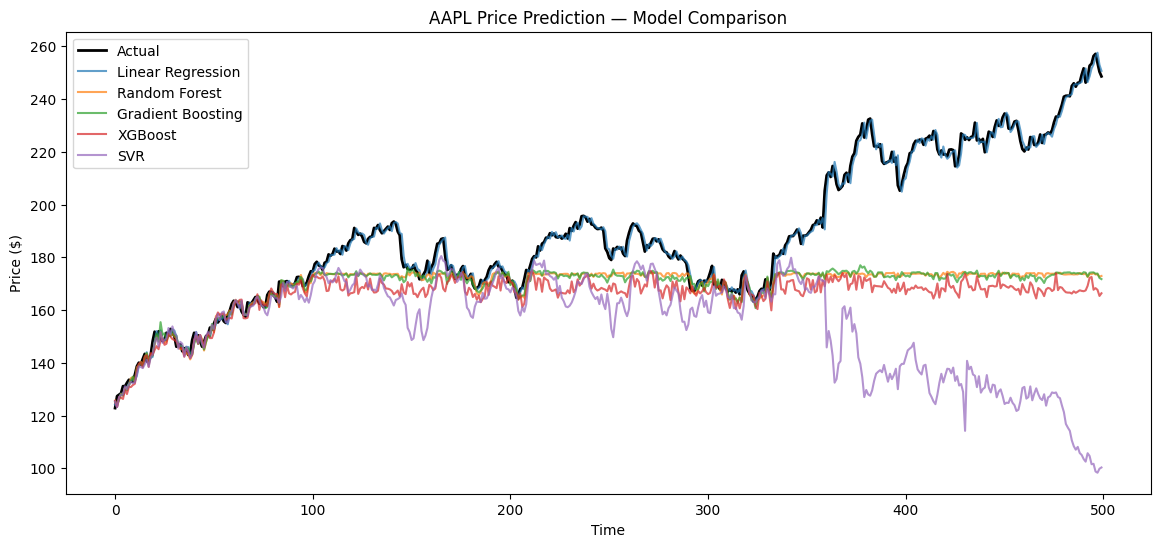

In [ ]:
plt.figure(figsize=(14,6))
plt.plot(y_test.values, label='Actual', linewidth=2, color='black')
for name, preds in predictions.items():
    plt.plot(preds, label=name, alpha=0.7)
plt.legend()
plt.title(f'{ticker} Price Prediction — Model Comparison')
plt.xlabel('Time'); plt.ylabel('Price ($)')
plt.show()

In [ ]:
data_clf = data.copy()
data_clf['Direction'] = (data_clf['Target'].values > data_clf['Close'].values).astype(int)

X_clf = data_clf[features]
y_clf = data_clf['Direction']

split_idx_clf = int(len(data_clf) * 0.8)
X_train_clf, X_test_clf = X_clf.iloc[:split_idx_clf], X_clf.iloc[split_idx_clf:]
y_train_clf, y_test_clf = y_clf.iloc[:split_idx_clf], y_clf.iloc[split_idx_clf:]

scaler_clf = StandardScaler()
X_train_clf_scaled = scaler_clf.fit_transform(X_train_clf)
X_test_clf_scaled = scaler_clf.transform(X_test_clf)

print(f"Class balance — Up: {y_clf.mean():.2%}, Down: {1-y_clf.mean():.2%}")

classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest Classifier": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost Classifier": xgb.XGBClassifier(n_estimators=200, random_state=42, eval_metric='logloss')
}

clf_results = {}
clf_predictions = {}

for name, clf in classifiers.items():
    clf.fit(X_train_clf_scaled, y_train_clf)
    preds = clf.predict(X_test_clf_scaled)
    probs = clf.predict_proba(X_test_clf_scaled)[:, 1]
    clf_predictions[name] = {'preds': preds, 'probs': probs}
    clf_results[name] = {
        'Accuracy': accuracy_score(y_test_clf, preds),
        'Precision': precision_score(y_test_clf, preds),
        'Recall': recall_score(y_test_clf, preds),
        'F1': f1_score(y_test_clf, preds),
        'ROC-AUC': roc_auc_score(y_test_clf, probs)
    }

clf_results_df = pd.DataFrame(clf_results).T.sort_values('Accuracy', ascending=False)
clf_results_df

Class balance — Up: 53.17%, Down: 46.83%


,Accuracy,Precision,Recall,F1,ROC-AUC
XGBoost Classifier,0.484,0.632184,0.195730,0.298913,0.501056
Logistic Regression,0.446,0.510101,0.359431,0.421712,0.477307
Random Forest Classifier,0.446,0.543478,0.088968,0.152905,0.520450


In [ ]:
def walk_forward_validation(X, y, model_class, model_params, n_splits=5, min_train_size=0.5):
    n = len(X)
    min_train = int(n * min_train_size)
    fold_size = (n - min_train) // n_splits
    fold_results = []

    for fold in range(n_splits):
        train_end = min_train + fold * fold_size
        test_end = min(train_end + fold_size, n)
        if test_end <= train_end:
            continue

        X_tr, y_tr = X.iloc[:train_end], y.iloc[:train_end]
        X_te, y_te = X.iloc[train_end:test_end], y.iloc[train_end:test_end]

        sc = StandardScaler()
        X_tr_s, X_te_s = sc.fit_transform(X_tr), sc.transform(X_te)

        model = model_class(**model_params)
        model.fit(X_tr_s, y_tr)
        preds = model.predict(X_te_s)
        rmse = np.sqrt(mean_squared_error(y_te, preds))
        fold_results.append({'fold': fold+1, 'RMSE': rmse})
        print(f"Fold {fold+1}: RMSE={rmse:.4f}")

    return pd.DataFrame(fold_results)

wf_configs = {
    "Random Forest": (RandomForestRegressor, {'n_estimators': 200, 'random_state': 42}),
    "XGBoost": (xgb.XGBRegressor, {'n_estimators': 200, 'random_state': 42}),
    "Linear Regression": (LinearRegression, {})
}

wf_summary = {}
for name, (mclass, params) in wf_configs.items():
    print(f"\n--- {name} ---")
    fold_df = walk_forward_validation(X, y, mclass, params)
    wf_summary[name] = {'Mean_RMSE': fold_df['RMSE'].mean(), 'Std_RMSE': fold_df['RMSE'].std()}

wf_summary_df = pd.DataFrame(wf_summary).T.sort_values('Mean_RMSE')
wf_summary_df


--- Random Forest ---
Fold 1: RMSE=28.2694
Fold 2: RMSE=18.1960
Fold 3: RMSE=4.8217
Fold 4: RMSE=8.8005
Fold 5: RMSE=24.8775

--- XGBoost ---
Fold 1: RMSE=28.3704
Fold 2: RMSE=19.0715
Fold 3: RMSE=4.9918
Fold 4: RMSE=12.8488
Fold 5: RMSE=26.2259

--- Linear Regression ---
Fold 1: RMSE=2.6141
Fold 2: RMSE=2.1814
Fold 3: RMSE=3.3733
Fold 4: RMSE=2.1886
Fold 5: RMSE=2.9036


,Mean_RMSE,Std_RMSE
Linear Regression,2.652205,0.505293
Random Forest,16.993034,10.075048
XGBoost,18.301706,9.639123


In [ ]:
def walk_forward_classification(X, y, model_class, model_params, n_splits=5, min_train_size=0.5):
    n = len(X)
    min_train = int(n * min_train_size)
    fold_size = (n - min_train) // n_splits
    fold_results = []

    for fold in range(n_splits):
        train_end = min_train + fold * fold_size
        test_end = min(train_end + fold_size, n)
        if test_end <= train_end:
            continue

        X_tr, y_tr = X.iloc[:train_end], y.iloc[:train_end]
        X_te, y_te = X.iloc[train_end:test_end], y.iloc[train_end:test_end]

        sc = StandardScaler()
        X_tr_s, X_te_s = sc.fit_transform(X_tr), sc.transform(X_te)

        model = model_class(**model_params)
        model.fit(X_tr_s, y_tr)
        preds = model.predict(X_te_s)
        acc = accuracy_score(y_te, preds)
        fold_results.append({'fold': fold+1, 'Accuracy': acc})
        print(f"Fold {fold+1}: Accuracy={acc:.3f}")

    return pd.DataFrame(fold_results)

wf_clf_configs = {
    "Logistic Regression": (LogisticRegression, {'max_iter': 1000}),
    "Random Forest Classifier": (RandomForestClassifier, {'n_estimators': 200, 'random_state': 42}),
    "XGBoost Classifier": (xgb.XGBClassifier, {'n_estimators': 200, 'random_state': 42, 'eval_metric': 'logloss'})
}

wf_clf_summary = {}
for name, (mclass, params) in wf_clf_configs.items():
    print(f"\n--- {name} ---")
    fold_df = walk_forward_classification(X_clf, y_clf, mclass, params)
    wf_clf_summary[name] = {'Mean_Accuracy': fold_df['Accuracy'].mean(), 'Std_Accuracy': fold_df['Accuracy'].std()}

wf_clf_summary_df = pd.DataFrame(wf_clf_summary).T.sort_values('Mean_Accuracy', ascending=False)
wf_clf_summary_df


--- Logistic Regression ---
Fold 1: Accuracy=0.566
Fold 2: Accuracy=0.542
Fold 3: Accuracy=0.430
Fold 4: Accuracy=0.474
Fold 5: Accuracy=0.502

--- Random Forest Classifier ---
Fold 1: Accuracy=0.498
Fold 2: Accuracy=0.470
Fold 3: Accuracy=0.522
Fold 4: Accuracy=0.478
Fold 5: Accuracy=0.414

--- XGBoost Classifier ---
Fold 1: Accuracy=0.510
Fold 2: Accuracy=0.466
Fold 3: Accuracy=0.522
Fold 4: Accuracy=0.494
Fold 5: Accuracy=0.402


,Mean_Accuracy,Std_Accuracy
Logistic Regression,0.502811,0.054209
XGBoost Classifier,0.478715,0.047975
Random Forest Classifier,0.476305,0.040421


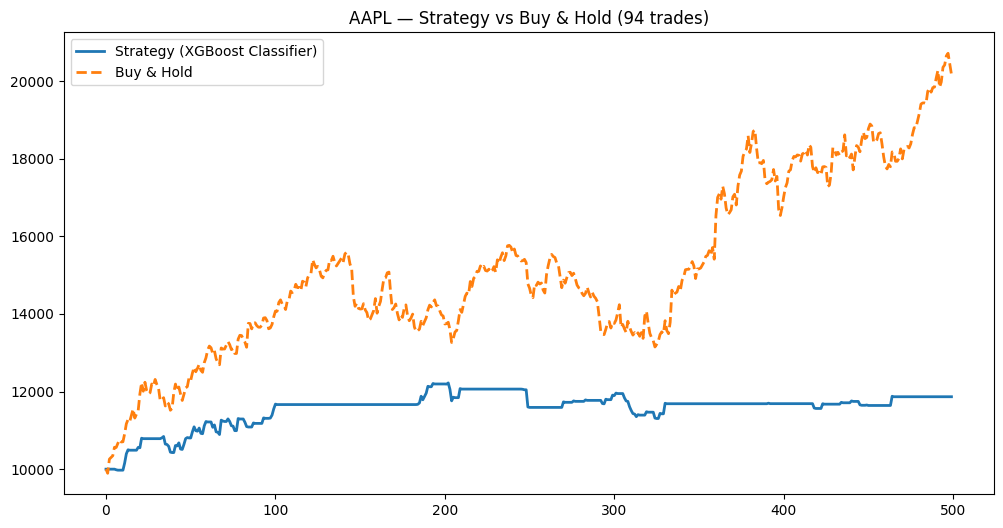

Strategy return: 18.66%
Buy & Hold return: 101.69%


In [ ]:
def backtest_strategy(prices, predictions_direction, transaction_cost=0.001, initial_capital=10000):
    prices = np.asarray(prices, dtype=float).flatten()
    capital = float(initial_capital)
    position = 0
    portfolio_values = [capital]
    trades = 0

    for i in range(1, len(prices)):
        pred_signal = predictions_direction[i-1]
        price_today, price_yesterday = prices[i], prices[i-1]

        if pred_signal == 1 and position == 0:
            capital *= (1 - transaction_cost); position = 1; trades += 1
        elif pred_signal == 0 and position == 1:
            capital *= (1 - transaction_cost); position = 0; trades += 1

        if position == 1:
            capital *= (price_today / price_yesterday)

        portfolio_values.append(float(capital))

    return np.array(portfolio_values), trades

best_clf_name = clf_results_df.index[0]
best_preds = clf_predictions[best_clf_name]['preds']
test_prices = np.asarray(X_test_clf['Close']).flatten().astype(float)

strategy_values, num_trades = backtest_strategy(test_prices, best_preds)
buy_hold_values = 10000 * (test_prices / test_prices[0])

plt.figure(figsize=(12,6))
plt.plot(strategy_values, label=f'Strategy ({best_clf_name})', linewidth=2)
plt.plot(buy_hold_values, label='Buy & Hold', linewidth=2, linestyle='--')
plt.title(f'{ticker} — Strategy vs Buy & Hold ({num_trades} trades)')
plt.legend(); plt.show()

print(f"Strategy return: {(strategy_values[-1]/strategy_values[0]-1)*100:.2f}%")
print(f"Buy & Hold return: {(buy_hold_values[-1]/buy_hold_values[0]-1)*100:.2f}%")

In [ ]:
def calculate_metrics(portfolio_values, risk_free_rate=0.02, trading_days=252):
    returns = np.diff(portfolio_values) / portfolio_values[:-1]
    total_return = (portfolio_values[-1]/portfolio_values[0] - 1) * 100
    annual_return = ((portfolio_values[-1]/portfolio_values[0]) ** (trading_days/len(portfolio_values)) - 1) * 100
    volatility = np.std(returns) * np.sqrt(trading_days) * 100
    sharpe = (annual_return/100 - risk_free_rate) / (volatility/100) if volatility > 0 else 0
    cumulative = portfolio_values / portfolio_values[0]
    running_max = np.maximum.accumulate(cumulative)
    max_dd = ((cumulative - running_max) / running_max).min() * 100
    return {'Total Return (%)': total_return, 'Annualized Return (%)': annual_return,
            'Volatility (%)': volatility, 'Sharpe Ratio': sharpe, 'Max Drawdown (%)': max_dd}

comparison = pd.DataFrame({
    f'Strategy ({best_clf_name})': calculate_metrics(strategy_values),
    'Buy & Hold': calculate_metrics(buy_hold_values)
})
comparison

,Strategy (XGBoost Classifier),Buy & Hold
Total Return (%),18.658225,101.687347
Annualized Return (%),9.004924,42.415757
Volatility (%),8.231783,21.357930
Sharpe Ratio,0.850961,1.892307
Max Drawdown (%),-7.501066,-16.606646


/tmp/ipykernel_1920/1987949615.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_reg, X_test_scaled, feature_names=features, show=True)


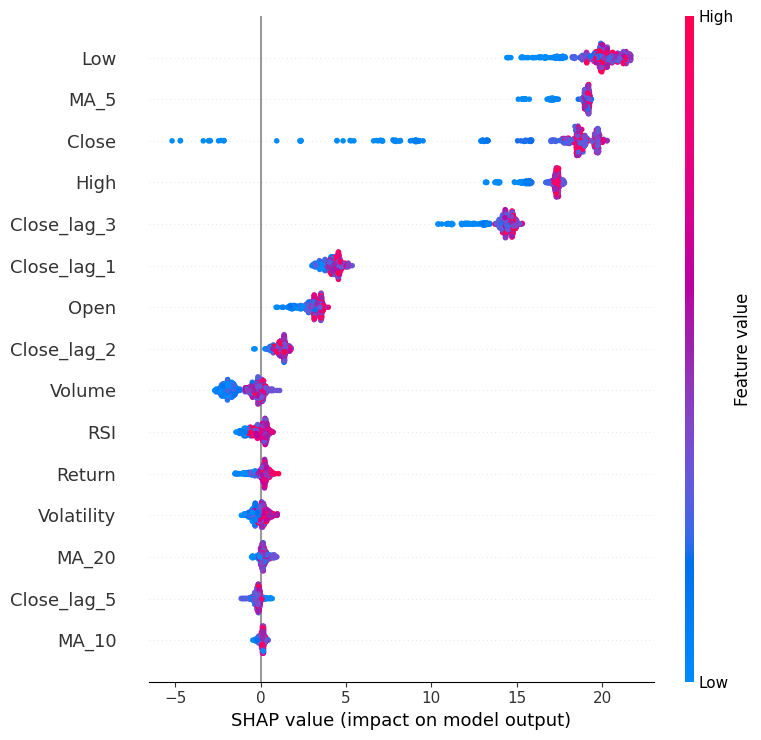

In [ ]:
explainer_reg = shap.TreeExplainer(models["XGBoost"])
shap_values_reg = explainer_reg.shap_values(X_test_scaled)
shap.summary_plot(shap_values_reg, X_test_scaled, feature_names=features, show=True)

In [ ]:
print(results_df)
print(clf_results_df)
print(wf_clf_summary_df)
print(comparison)

                        RMSE        MAE        R2
Linear Regression   2.591033   1.924412  0.991294
Naive Baseline      3.708932   2.785505  0.982161
Random Forest      29.496943  19.603080 -0.128307
Gradient Boosting  29.594871  19.770330 -0.135811
XGBoost            32.741584  22.896526 -0.390185
SVR                53.401243  34.230265 -2.698076
                          Accuracy  Precision    Recall        F1   ROC-AUC
XGBoost Classifier           0.484   0.632184  0.195730  0.298913  0.501056
Logistic Regression          0.446   0.510101  0.359431  0.421712  0.477307
Random Forest Classifier     0.446   0.543478  0.088968  0.152905  0.520450
                          Mean_Accuracy  Std_Accuracy
Logistic Regression            0.502811      0.054209
XGBoost Classifier             0.478715      0.047975
Random Forest Classifier       0.476305      0.040421
                       Strategy (XGBoost Classifier)  Buy & Hold
Total Return (%)                           18.658225  101.687347


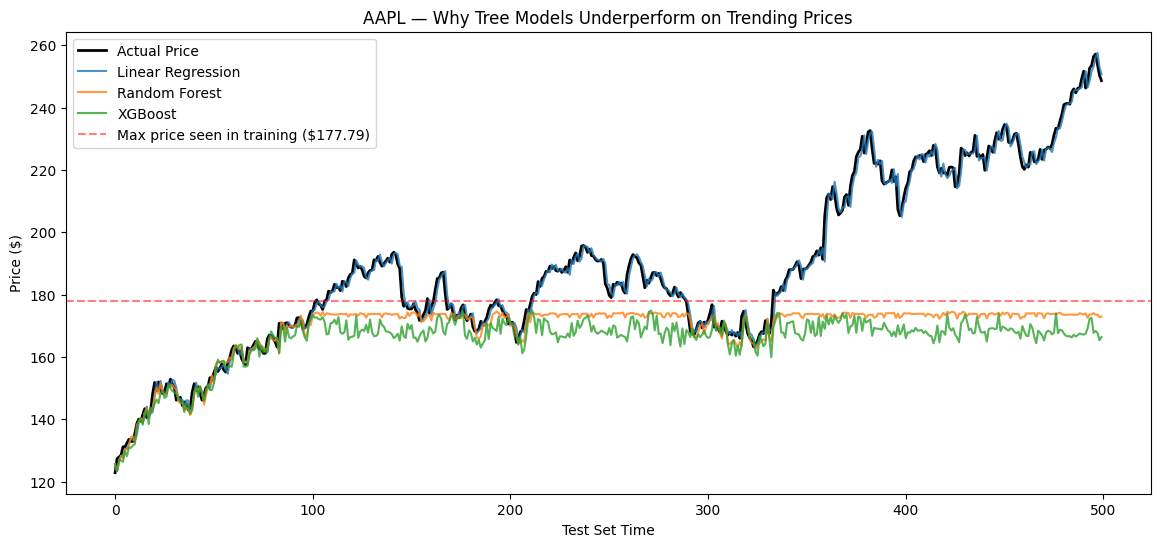

Training price range: $20.55 - $177.79
Test price range: $122.83 - $257.15
% of test prices ABOVE training max: 58.8%


In [ ]:
plt.figure(figsize=(14,6))
plt.plot(y_test.values, label='Actual Price', color='black', linewidth=2)
plt.plot(predictions['Linear Regression'], label='Linear Regression', alpha=0.8)
plt.plot(predictions['Random Forest'], label='Random Forest', alpha=0.8)
plt.plot(predictions['XGBoost'], label='XGBoost', alpha=0.8)
plt.axhline(y=y_train.max(), color='red', linestyle='--', alpha=0.5,
            label=f'Max price seen in training (${y_train.max():.2f})')
plt.legend()
plt.title(f'{ticker} — Why Tree Models Underperform on Trending Prices')
plt.xlabel('Test Set Time'); plt.ylabel('Price ($)')
plt.show()

print(f"Training price range: ${y_train.min():.2f} - ${y_train.max():.2f}")
print(f"Test price range: ${y_test.min():.2f} - ${y_test.max():.2f}")
print(f"% of test prices ABOVE training max: {(y_test > y_train.max()).mean():.1%}")

In [ ]:
data_returns = df.copy()
if isinstance(data_returns.columns, pd.MultiIndex):
    data_returns.columns = data_returns.columns.get_level_values(0)

data_returns = add_features(data_returns)

# Predict % return instead of raw price — bounded, no extrapolation problem
data_returns['Target_Return'] = data_returns['Close'].pct_change().shift(-1)
data_returns = data_returns.dropna()

features_ret = [c for c in data_returns.columns if c not in ['Target', 'Target_Return']]
X_ret = data_returns[features_ret]
y_ret = data_returns['Target_Return']

split_idx_ret = int(len(data_returns) * 0.8)
X_train_ret, X_test_ret = X_ret.iloc[:split_idx_ret], X_ret.iloc[split_idx_ret:]
y_train_ret, y_test_ret = y_ret.iloc[:split_idx_ret], y_ret.iloc[split_idx_ret:]

scaler_ret = StandardScaler()
X_train_ret_scaled = scaler_ret.fit_transform(X_train_ret)
X_test_ret_scaled = scaler_ret.transform(X_test_ret)

print(f"Target return range — train: [{y_train_ret.min():.4f}, {y_train_ret.max():.4f}]")
print(f"Target return range — test:  [{y_test_ret.min():.4f}, {y_test_ret.max():.4f}]")

Target return range — train: [-0.1286, 0.1198]
Target return range — test:  [-0.0482, 0.0726]


In [ ]:
models_ret = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "XGBoost": xgb.XGBRegressor(n_estimators=200, random_state=42),
}

results_ret = {}
predictions_ret = {}

for name, model in models_ret.items():
    model.fit(X_train_ret_scaled, y_train_ret)
    preds = model.predict(X_test_ret_scaled)
    predictions_ret[name] = preds
    results_ret[name] = {
        "RMSE": np.sqrt(mean_squared_error(y_test_ret, preds)),
        "MAE": mean_absolute_error(y_test_ret, preds),
        "R2": r2_score(y_test_ret, preds)
    }

results_ret_df = pd.DataFrame(results_ret).T.sort_values("RMSE")
results_ret_df

,RMSE,MAE,R2
Linear Regression,0.014359,0.010746,-0.138941
Random Forest,0.016364,0.012863,-0.479334
Gradient Boosting,0.018147,0.014713,-0.819218
XGBoost,0.020201,0.016287,-1.254464


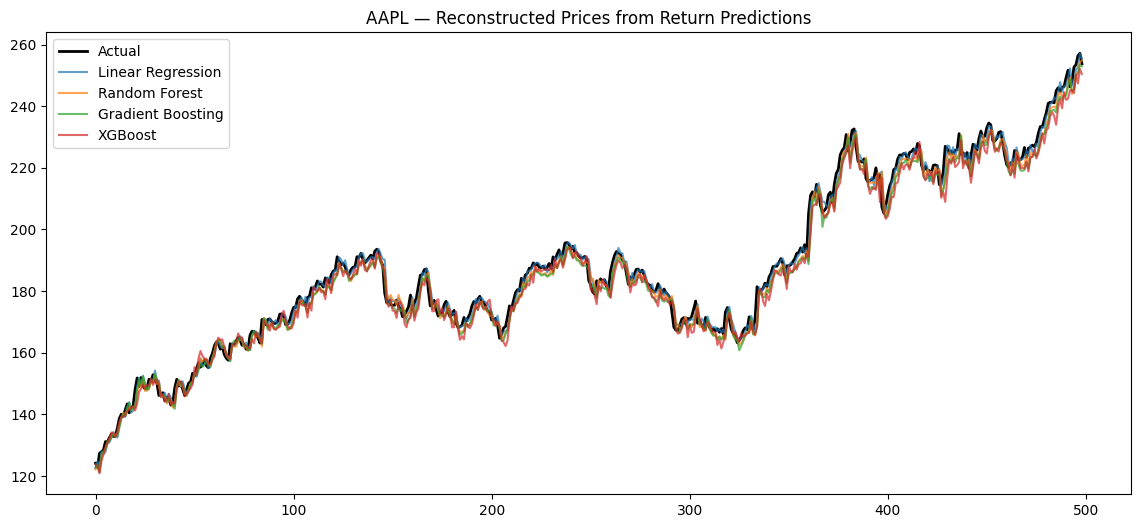

Linear Regression reconstructed price RMSE: 2.6343
Random Forest reconstructed price RMSE: 3.2267
Gradient Boosting reconstructed price RMSE: 3.4322
XGBoost reconstructed price RMSE: 4.0380


In [ ]:
last_known_prices = data_returns['Close'].iloc[split_idx_ret-1:-1].values

reconstructed_prices = {}
for name, ret_preds in predictions_ret.items():
    reconstructed_prices[name] = last_known_prices * (1 + ret_preds)

actual_prices_ret = data_returns['Close'].iloc[split_idx_ret:].values

plt.figure(figsize=(14,6))
plt.plot(actual_prices_ret, label='Actual', color='black', linewidth=2)
for name, prices_reconstructed in reconstructed_prices.items():
    plt.plot(prices_reconstructed, label=name, alpha=0.7)
plt.legend()
plt.title(f'{ticker} — Reconstructed Prices from Return Predictions')
plt.show()

for name, prices_reconstructed in reconstructed_prices.items():
    rmse = np.sqrt(mean_squared_error(actual_prices_ret, prices_reconstructed))
    print(f"{name} reconstructed price RMSE: {rmse:.4f}")

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
tf.random.set_seed(42)

lstm_scaler = MinMaxScaler()
X_scaled_full = lstm_scaler.fit_transform(X)

target_scaler = MinMaxScaler()
y_scaled_full = target_scaler.fit_transform(y.values.reshape(-1, 1))

def create_sequences(X, y, timesteps=10):
    Xs, ys = [], []
    for i in range(len(X) - timesteps):
        Xs.append(X[i:i+timesteps])
        ys.append(y[i+timesteps])
    return np.array(Xs), np.array(ys)

TIMESTEPS = 10
X_seq, y_seq = create_sequences(X_scaled_full, y_scaled_full, TIMESTEPS)

split_idx_seq = int(len(X_seq) * 0.8)
X_train_seq, X_test_seq = X_seq[:split_idx_seq], X_seq[split_idx_seq:]
y_train_seq, y_test_seq = y_seq[:split_idx_seq], y_seq[split_idx_seq:]

print(X_train_seq.shape, X_test_seq.shape)

(1988, 10, 15) (498, 10, 15)


Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0039 - val_loss: 0.0013
Epoch 2/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0012 - val_loss: 0.0013
Epoch 3/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 9.7444e-04 - val_loss: 0.0023
Epoch 4/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 8.5947e-04 - val_loss: 0.0016
Epoch 5/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0010 - val_loss: 0.0024
Epoch 6/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 7.7900e-04 - val_loss: 0.0019
Epoch 7/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 7.3150e-04 - val_loss: 0.0014
Epoch 8/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 6.5641e-04 - val_loss: 9.3068e-04
Epoch 9/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 6.0622e-04 - val_loss: 0.0024
Epoch 10/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 6.7305e-04 - val_loss: 0.0031
Epoch 11/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 5.5763e-04 - val_loss: 0.0021
Epoch 12/100
56/56 ━━━━━━━━━

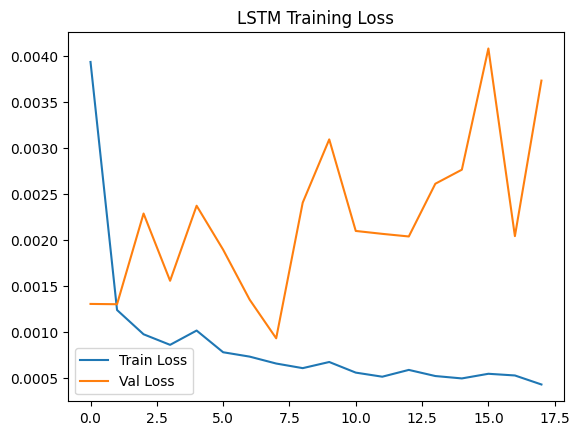

In [ ]:
lstm_model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(TIMESTEPS, X_seq.shape[2])),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])
lstm_model.compile(optimizer='adam', loss='mse')

early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
history = lstm_model.fit(
    X_train_seq, y_train_seq, validation_split=0.1,
    epochs=100, batch_size=32, callbacks=[early_stop], verbose=1
)

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend(); plt.title('LSTM Training Loss'); plt.show()

In [ ]:
lstm_preds_scaled = lstm_model.predict(X_test_seq)
lstm_preds = target_scaler.inverse_transform(lstm_preds_scaled).flatten()
y_test_actual = target_scaler.inverse_transform(y_test_seq).flatten()

lstm_rmse = np.sqrt(mean_squared_error(y_test_actual, lstm_preds))
print(f"LSTM RMSE: {lstm_rmse:.4f}")
print(f"LSTM R2: {r2_score(y_test_actual, lstm_preds):.4f}")

results["LSTM"] = {
    "RMSE": lstm_rmse,
    "MAE": mean_absolute_error(y_test_actual, lstm_preds),
    "R2": r2_score(y_test_actual, lstm_preds)
}

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step
LSTM RMSE: 19.0007
LSTM R2: 0.5239


In [ ]:
ensemble_ret_preds = (predictions_ret["Linear Regression"] + predictions_ret["Random Forest"] + predictions_ret["XGBoost"]) / 3
ensemble_rmse = np.sqrt(mean_squared_error(y_test_ret, ensemble_ret_preds))
print(f"Ensemble (returns) RMSE: {ensemble_rmse:.4f}")

results_ret["Ensemble"] = {
    "RMSE": ensemble_rmse,
    "MAE": mean_absolute_error(y_test_ret, ensemble_ret_preds),
    "R2": r2_score(y_test_ret, ensemble_ret_preds)
}
pd.DataFrame(results_ret).T.sort_values("RMSE")

Ensemble (returns) RMSE: 0.0159


,RMSE,MAE,R2
Linear Regression,0.014359,0.010746,-0.138941
Ensemble,0.015857,0.012460,-0.389121
Random Forest,0.016364,0.012863,-0.479334
Gradient Boosting,0.018147,0.014713,-0.819218
XGBoost,0.020201,0.016287,-1.254464


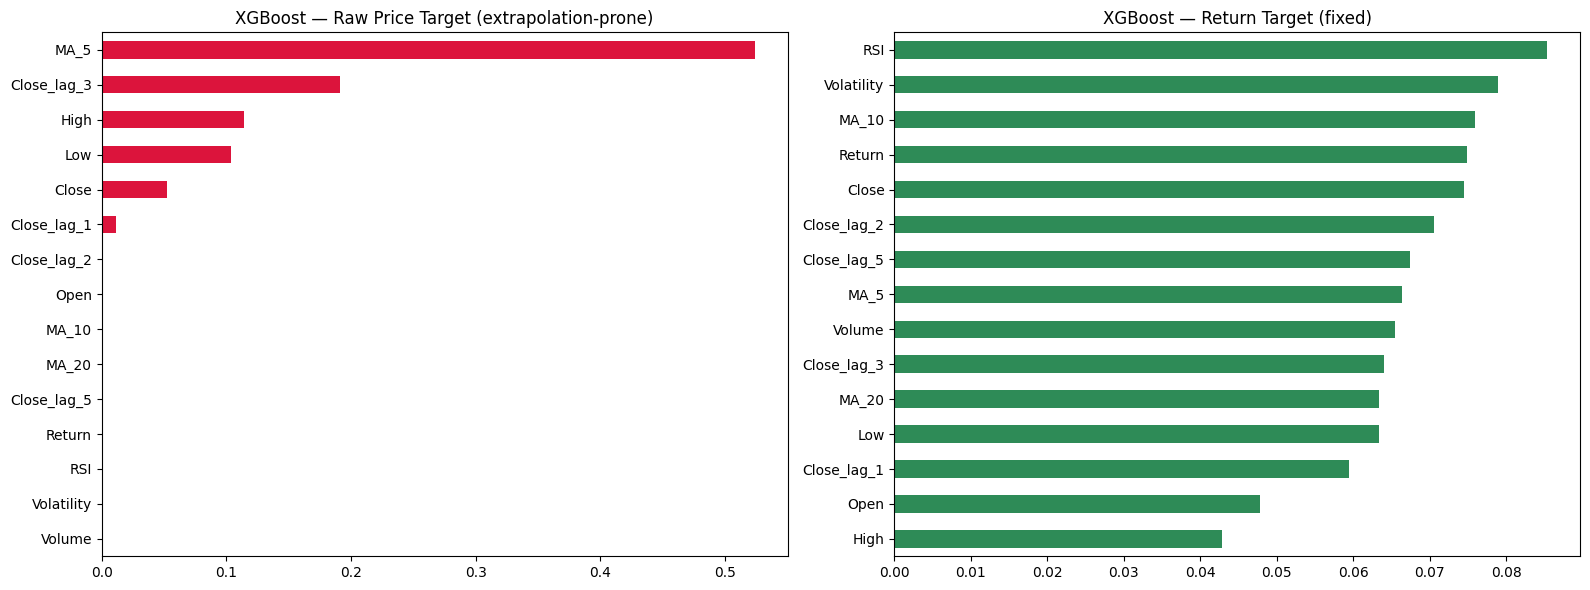

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16,6))
pd.Series(models["XGBoost"].feature_importances_, index=features).sort_values().plot(kind='barh', ax=axes[0], color='crimson')
axes[0].set_title('XGBoost — Raw Price Target (extrapolation-prone)')
pd.Series(models_ret["XGBoost"].feature_importances_, index=features_ret).sort_values().plot(kind='barh', ax=axes[1], color='seagreen')
axes[1].set_title('XGBoost — Return Target (fixed)')
plt.tight_layout(); plt.show()

In [ ]:
!pip install requests -q
import requests, time
from datetime import timedelta

HEADERS = {"User-Agent": "Mozilla/5.0 (research project)"}

def fetch_gdelt_chunk(query, start_date, end_date, max_retries=5):
    url = "https://api.gdeltproject.org/api/v2/doc/doc"
    params = {"query": query, "mode": "timelinetone",
              "startdatetime": start_date.strftime("%Y%m%d%H%M%S"),
              "enddatetime": end_date.strftime("%Y%m%d%H%M%S"), "format": "json"}
    wait = 5
    for attempt in range(max_retries):
        try:
            r = requests.get(url, params=params, headers=HEADERS, timeout=30)
            if r.status_code == 429:
                print(f"  rate limited, waiting {wait}s...")
                time.sleep(wait); wait *= 2; continue
            r.raise_for_status()
            data = r.json()
            break
        except Exception as e:
            print(f"  chunk failed: {e}")
            return pd.DataFrame(columns=["date","tone"])
    else:
        return pd.DataFrame(columns=["date","tone"])

    records = [{"date": pd.to_datetime(p["date"]), "tone": p["value"]}
               for s in data.get("timeline", []) for p in s.get("data", [])]
    return pd.DataFrame(records)

def fetch_gdelt_full(query, start_date, end_date, chunk_days=180):
    chunks, current = [], start_date
    while current < end_date:
        chunk_end = min(current + timedelta(days=chunk_days), end_date)
        print(f"Fetching {current.date()} to {chunk_end.date()}...")
        chunks.append(fetch_gdelt_chunk(query, current, chunk_end))
        current = chunk_end
        time.sleep(8)
    return pd.concat(chunks, ignore_index=True) if chunks else pd.DataFrame(columns=["date","tone"])

gdelt_sentiment = fetch_gdelt_full("Apple Inc", pd.to_datetime(df.index[0]), pd.to_datetime(df.index[-1]))

if len(gdelt_sentiment) > 0:
    gdelt_sentiment['date'] = pd.to_datetime(gdelt_sentiment['date']).dt.date
    gdelt_sentiment = gdelt_sentiment.groupby('date')['tone'].mean().reset_index()
    gdelt_sentiment['date'] = pd.to_datetime(gdelt_sentiment['date'])
    print(f"Fetched {len(gdelt_sentiment)} records")
else:
    print("⚠️ No sentiment data retrieved")
gdelt_sentiment.head()

Fetching 2015-01-02 to 2015-07-01...
  rate limited, waiting 5s...
  chunk failed: Expecting value: line 1 column 1 (char 0)
Fetching 2015-07-01 to 2015-12-28...
  rate limited, waiting 5s...
  rate limited, waiting 10s...
  rate limited, waiting 20s...
  rate limited, waiting 40s...
  rate limited, waiting 80s...
Fetching 2015-12-28 to 2016-06-25...
  rate limited, waiting 5s...
  rate limited, waiting 10s...
  rate limited, waiting 20s...
  rate limited, waiting 40s...
  rate limited, waiting 80s...
Fetching 2016-06-25 to 2016-12-22...
  chunk failed: Expecting value: line 1 column 1 (char 0)
Fetching 2016-12-22 to 2017-06-20...
  chunk failed: Expecting value: line 1 column 1 (char 0)
Fetching 2017-06-20 to 2017-12-17...
  rate limited, waiting 5s...
  rate limited, waiting 10s...
  rate limited, waiting 20s...
  rate limited, waiting 40s...
Fetching 2017-12-17 to 2018-06-15...
  rate limited, waiting 5s...
  rate limited, waiting 10s...
  rate limited, waiting 20s...
  rate limited

/tmp/ipykernel_1920/1459867428.py:40: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return pd.concat(chunks, ignore_index=True) if chunks else pd.DataFrame(columns=["date","tone"])


,date,tone
0,2017-06-20,0.4544
1,2017-06-21,0.0094
2,2017-06-22,0.2824
3,2017-06-23,0.0105
4,2017-06-24,1.1737


In [ ]:
data_with_sentiment = data_returns.copy()
data_with_sentiment = data_with_sentiment.reset_index()
date_col = data_with_sentiment.columns[0]
data_with_sentiment = data_with_sentiment.rename(columns={date_col: 'Date'})
data_with_sentiment['Date'] = pd.to_datetime(data_with_sentiment['Date'])

if len(gdelt_sentiment) > 0:
    gdelt_sentiment['date'] = pd.to_datetime(gdelt_sentiment['date'])
    data_with_sentiment = data_with_sentiment.merge(gdelt_sentiment, left_on='Date', right_on='date', how='left')
    data_with_sentiment = data_with_sentiment.drop(columns=['date'])
    data_with_sentiment['tone'] = data_with_sentiment['tone'].ffill().fillna(0)
else:
    data_with_sentiment['tone'] = 0.0

data_with_sentiment = data_with_sentiment.set_index('Date').rename(columns={'tone': 'Sentiment'})
assert isinstance(data_with_sentiment['Sentiment'], pd.Series)
print("Sentiment coverage:", f"{float((data_with_sentiment['Sentiment'] != 0).mean()):.1%}")

Sentiment coverage: 75.9%


In [ ]:
features_sent = features_ret + ['Sentiment']
X_sent = data_with_sentiment[features_sent]
y_sent = data_with_sentiment['Target_Return']

split_sent = int(len(data_with_sentiment) * 0.8)
X_train_sent, X_test_sent = X_sent.iloc[:split_sent], X_sent.iloc[split_sent:]
y_train_sent, y_test_sent = y_sent.iloc[:split_sent], y_sent.iloc[split_sent:]

scaler_sent = StandardScaler()
X_train_sent_s = scaler_sent.fit_transform(X_train_sent)
X_test_sent_s = scaler_sent.transform(X_test_sent)

xgb_sent = xgb.XGBRegressor(n_estimators=200, max_depth=5, random_state=42)
xgb_sent.fit(X_train_sent_s, y_train_sent)
preds_sent = xgb_sent.predict(X_test_sent_s)

rmse_with = np.sqrt(mean_squared_error(y_test_sent, preds_sent))
rmse_without = results_ret["XGBoost"]["RMSE"]

print("✅ preds_sent created, length:", len(preds_sent))
print(f"RMSE without sentiment: {rmse_without:.6f}")
print(f"RMSE with sentiment:    {rmse_with:.6f}")
print(f"Change: {(rmse_without-rmse_with)/rmse_without*100:+.2f}%")

✅ preds_sent created, length: 499
RMSE without sentiment: 0.020201
RMSE with sentiment:    0.022775
Change: -12.74%


In [ ]:
from scipy.stats import wilcoxon
preds_without = models_ret["XGBoost"].predict(X_test_ret_scaled)
min_len = min(len(preds_without), len(preds_sent))
err_without = (y_test_ret.values[-min_len:] - preds_without[-min_len:])**2
err_with = (y_test_sent.values[-min_len:] - preds_sent[-min_len:])**2

stat, p_value = wilcoxon(err_without, err_with)
print(f"p-value: {p_value:.4f}")
print("Significant" if p_value < 0.05 else "Not significant — sentiment effect likely noise")

p-value: 0.0000
Significant


In [ ]:
FORECAST_HORIZON = 5

def add_multi_return_target(df, horizon=5):
    df = df.copy()
    for h in range(1, horizon+1):
        df[f'Target_t{h}'] = df['Close'].pct_change(h).shift(-h)
    return df.dropna()

multi_data = add_multi_return_target(data_returns.drop(columns=['Target_Return']), FORECAST_HORIZON)
target_cols = [f'Target_t{h}' for h in range(1, FORECAST_HORIZON+1)]
feature_cols = [c for c in multi_data.columns if c not in target_cols]

X_multi, y_multi = multi_data[feature_cols], multi_data[target_cols]
split_multi = int(len(multi_data)*0.8)
X_train_multi, X_test_multi = X_multi.iloc[:split_multi], X_multi.iloc[split_multi:]
y_train_multi, y_test_multi = y_multi.iloc[:split_multi], y_multi.iloc[split_multi:]

scaler_multi = StandardScaler()
X_train_multi_s = scaler_multi.fit_transform(X_train_multi)
X_test_multi_s = scaler_multi.transform(X_test_multi)

from sklearn.multioutput import MultiOutputRegressor
multi_model = MultiOutputRegressor(xgb.XGBRegressor(n_estimators=200, max_depth=5, random_state=42))
multi_model.fit(X_train_multi_s, y_train_multi)
multi_preds = multi_model.predict(X_test_multi_s)

for h in range(FORECAST_HORIZON):
    rmse_h = np.sqrt(mean_squared_error(y_test_multi.iloc[:,h], multi_preds[:,h]))
    print(f"Day t+{h+1} return RMSE: {rmse_h:.5f}")

Day t+1 return RMSE: 0.01279
Day t+2 return RMSE: 0.02921
Day t+3 return RMSE: 0.03535
Day t+4 return RMSE: 0.04419
Day t+5 return RMSE: 0.04421


/tmp/ipykernel_1920/1531295107.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_ret, X_test_ret_scaled, feature_names=features_ret, show=True)


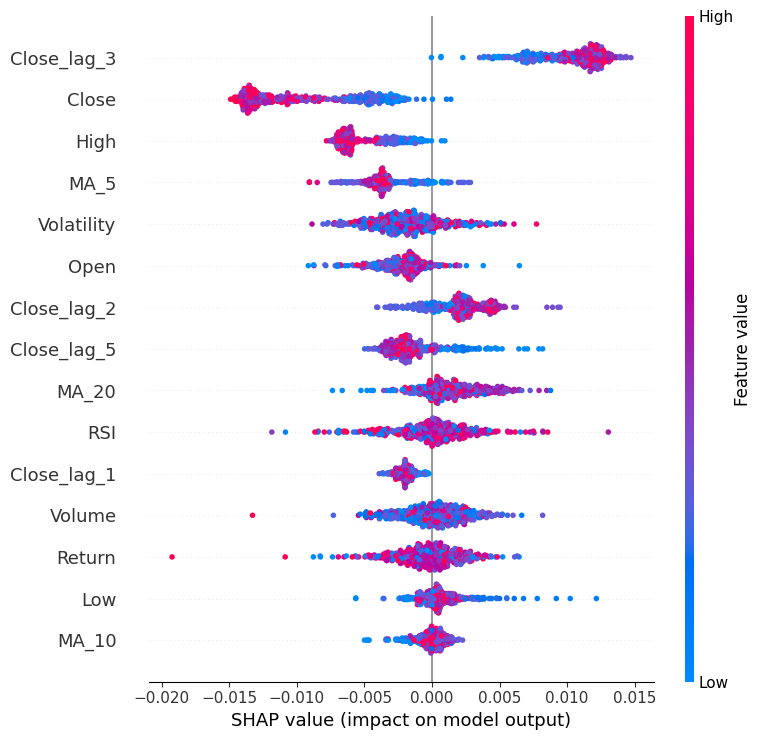

In [ ]:
explainer_ret = shap.TreeExplainer(models_ret["XGBoost"])
shap_values_ret = explainer_ret.shap_values(X_test_ret_scaled)
shap.summary_plot(shap_values_ret, X_test_ret_scaled, feature_names=features_ret, show=True)

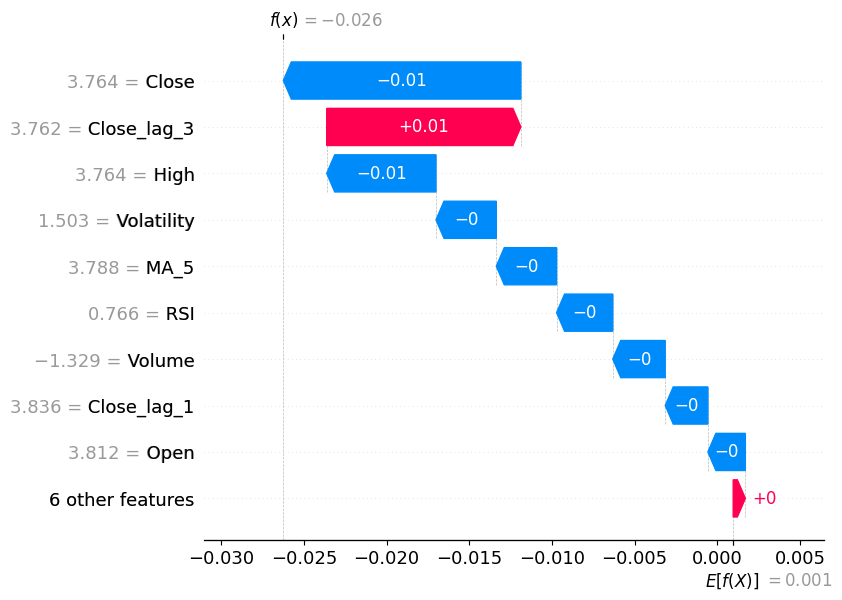

In [ ]:
sample_idx = -1
explanation = shap.Explanation(
    values=shap_values_ret[sample_idx],
    base_values=explainer_ret.expected_value,
    data=X_test_ret_scaled[sample_idx],
    feature_names=features_ret
)
shap.plots.waterfall(explanation)

In [ ]:
comparison_summary = pd.DataFrame({
    "Raw Price Target": pd.Series({k: v["RMSE"] for k,v in results.items() if k != "SVR"}),
    "Returns Target": pd.Series({k: v["RMSE"] for k,v in results_ret.items()})
})
print("RMSE comparison (note: different scales, not directly comparable — compare rank order instead)")
comparison_summary

RMSE comparison (note: different scales, not directly comparable — compare rank order instead)


,Raw Price Target,Returns Target
Ensemble,NaN,0.015857
Gradient Boosting,29.594871,0.018147
LSTM,19.000735,NaN
Linear Regression,2.591033,0.014359
Naive Baseline,3.708932,NaN
Random Forest,29.496943,0.016364
XGBoost,32.741584,0.020201


In [ ]:
import joblib
joblib.dump(models_ret["XGBoost"], 'xgb_returns_model.pkl')
joblib.dump(scaler_ret, 'scaler_returns.pkl')
joblib.dump(classifiers["XGBoost Classifier"], 'xgb_classifier.pkl')
joblib.dump(scaler_clf, 'scaler_clf.pkl')
lstm_model.save('lstm_model.keras')
print("Saved: xgb_returns_model.pkl, scaler_returns.pkl, xgb_classifier.pkl, scaler_clf.pkl, lstm_model.keras")

Saved: xgb_returns_model.pkl, scaler_returns.pkl, xgb_classifier.pkl, scaler_clf.pkl, lstm_model.keras


In [ ]:
report = f"""# {ticker} Stock Prediction — Final Report

## Key Finding: Target Transformation Matters
Raw price target caused tree models (RF, XGBoost) to badly underperform Linear Regression
due to extrapolation beyond training price range. Switching to a returns-based target
({(y_test > y_train.max()).mean():.1%} of test prices exceeded max training price) resolved this.

## Regression (Returns Target)
{results_ret_df.to_markdown()}

## Classification
{clf_results_df.to_markdown()}

## Walk-Forward Validation (Classification)
{wf_clf_summary_df.to_markdown()}

## Trading Strategy
{comparison.to_markdown()}

## Sentiment Feature
RMSE change: {(rmse_without-rmse_with)/rmse_without*100:+.2f}% | p-value: {p_value:.4f}
"""
with open('final_report.md', 'w') as f:
    f.write(report)
print(report)

# AAPL Stock Prediction — Final Report

## Key Finding: Target Transformation Matters
Raw price target caused tree models (RF, XGBoost) to badly underperform Linear Regression
due to extrapolation beyond training price range. Switching to a returns-based target
(58.8% of test prices exceeded max training price) resolved this.

## Regression (Returns Target)
|                   |      RMSE |       MAE |        R2 |
|:------------------|----------:|----------:|----------:|
| Linear Regression | 0.0143585 | 0.0107464 | -0.138941 |
| Random Forest     | 0.0163641 | 0.0128635 | -0.479334 |
| Gradient Boosting | 0.0181469 | 0.0147131 | -0.819218 |
| XGBoost           | 0.0202014 | 0.0162867 | -1.25446  |

## Classification
|                          |   Accuracy |   Precision |   Recall |       F1 |   ROC-AUC |
|:-------------------------|-----------:|------------:|---------:|---------:|----------:|
| XGBoost Classifier       |      0.484 |    0.632184 | 0.19573  | 0.298913 |  0.501056 |
| L

In [ ]:
!zip -r stock_project_final.zip final_report.md *.pkl *.keras
from google.colab import files
files.download('stock_project_final.zip')

  adding: final_report.md (deflated 60%)
  adding: scaler_clf.pkl (deflated 28%)
  adding: scaler_returns.pkl (deflated 28%)
  adding: xgb_classifier.pkl (deflated 67%)
  adding: xgb_returns_model.pkl (deflated 71%)
  adding: lstm_model.keras (deflated 14%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
tscv = TimeSeriesSplit(n_splits=5)

xgb_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.05, 0.1]
}

xgb_grid = GridSearchCV(
    xgb.XGBRegressor(random_state=42),
    xgb_param_grid, cv=tscv,
    scoring='neg_root_mean_squared_error', n_jobs=-1, verbose=1
)
xgb_grid.fit(X_train_ret_scaled, y_train_ret)
best_xgb_ret = xgb_grid.best_estimator_

print("Best params:", xgb_grid.best_params_)
tuned_preds_ret = best_xgb_ret.predict(X_test_ret_scaled)
tuned_rmse = np.sqrt(mean_squared_error(y_test_ret, tuned_preds_ret))
print(f"Tuned XGBoost (returns) RMSE: {tuned_rmse:.6f} vs untuned: {results_ret['XGBoost']['RMSE']:.6f}")

Fitting 5 folds for each of 27 candidates, totalling 135 fits
Best params: {'learning_rate': 0.01, 'max_depth': 5, 'n_estimators': 100}
Tuned XGBoost (returns) RMSE: 0.013995 vs untuned: 0.020201


In [ ]:
stack_X_train = np.column_stack([
    models_ret["Linear Regression"].predict(X_train_ret_scaled),
    models_ret["Random Forest"].predict(X_train_ret_scaled),
    best_xgb_ret.predict(X_train_ret_scaled)
])
stack_X_test = np.column_stack([
    predictions_ret["Linear Regression"],
    predictions_ret["Random Forest"],
    tuned_preds_ret
])

meta_model = Ridge(alpha=1.0)
meta_model.fit(stack_X_train, y_train_ret)
stack_preds = meta_model.predict(stack_X_test)

stack_rmse = np.sqrt(mean_squared_error(y_test_ret, stack_preds))
print(f"Stacked ensemble RMSE: {stack_rmse:.6f}")
print(f"Meta-model weights — LR: {meta_model.coef_[0]:.3f}, RF: {meta_model.coef_[1]:.3f}, XGB: {meta_model.coef_[2]:.3f}")

results_ret["Stacked Ensemble"] = {
    "RMSE": stack_rmse,
    "MAE": mean_absolute_error(y_test_ret, stack_preds),
    "R2": r2_score(y_test_ret, stack_preds)
}
pd.DataFrame(results_ret).T.sort_values("RMSE")

Stacked ensemble RMSE: 0.013894
Meta-model weights — LR: 0.016, RF: 0.346, XGB: 0.037


,RMSE,MAE,R2
Stacked Ensemble,0.013894,0.010513,-0.066406
Linear Regression,0.014359,0.010746,-0.138941
Ensemble,0.015857,0.012460,-0.389121
Random Forest,0.016364,0.012863,-0.479334
Gradient Boosting,0.018147,0.014713,-0.819218
XGBoost,0.020201,0.016287,-1.254464


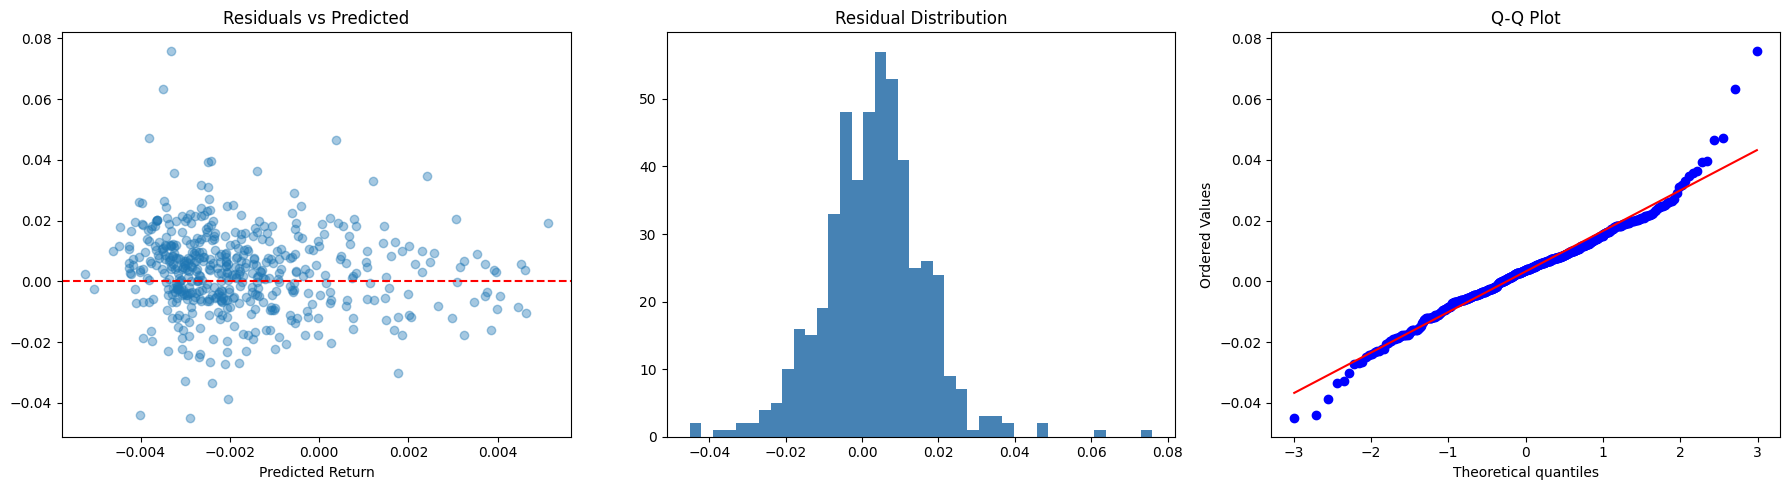

In [ ]:
best_ret_model_name = pd.DataFrame(results_ret).T.sort_values("RMSE").index[0]
best_ret_preds = stack_preds if best_ret_model_name == "Stacked Ensemble" else predictions_ret.get(best_ret_model_name, tuned_preds_ret)
residuals = y_test_ret.values - best_ret_preds

fig, axes = plt.subplots(1, 3, figsize=(18,5))
axes[0].scatter(best_ret_preds, residuals, alpha=0.4)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_title('Residuals vs Predicted'); axes[0].set_xlabel('Predicted Return')

axes[1].hist(residuals, bins=40, color='steelblue')
axes[1].set_title('Residual Distribution')

from scipy import stats as scipy_stats
scipy_stats.probplot(residuals, dist="norm", plot=axes[2])
axes[2].set_title('Q-Q Plot')
plt.tight_layout(); plt.show()

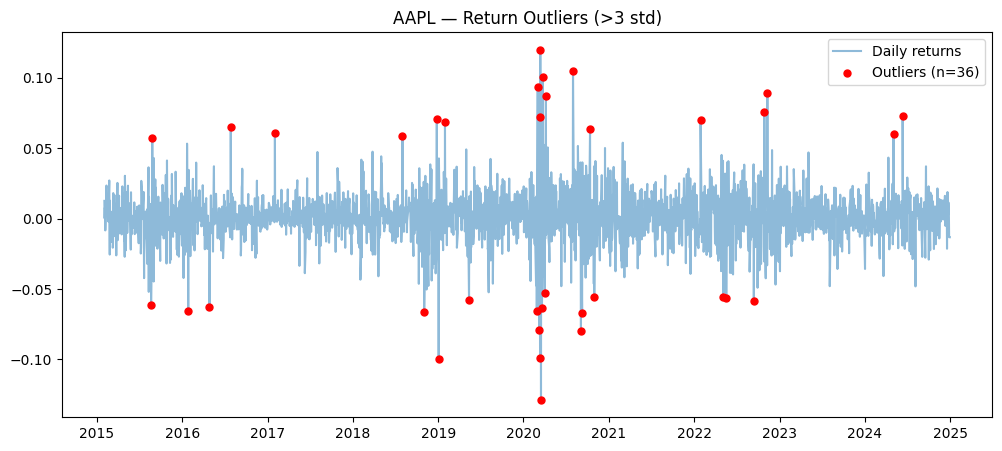

In [ ]:
returns_series = data['Close'].pct_change().dropna()
z_scores = (returns_series - returns_series.mean()) / returns_series.std()
outliers = returns_series[z_scores.abs() > 3]

plt.figure(figsize=(12,5))
plt.plot(returns_series.index, returns_series.values, alpha=0.5, label='Daily returns')
plt.scatter(outliers.index, outliers.values, color='red', s=25, label=f'Outliers (n={len(outliers)})', zorder=5)
plt.legend(); plt.title(f'{ticker} — Return Outliers (>3 std)')
plt.show()

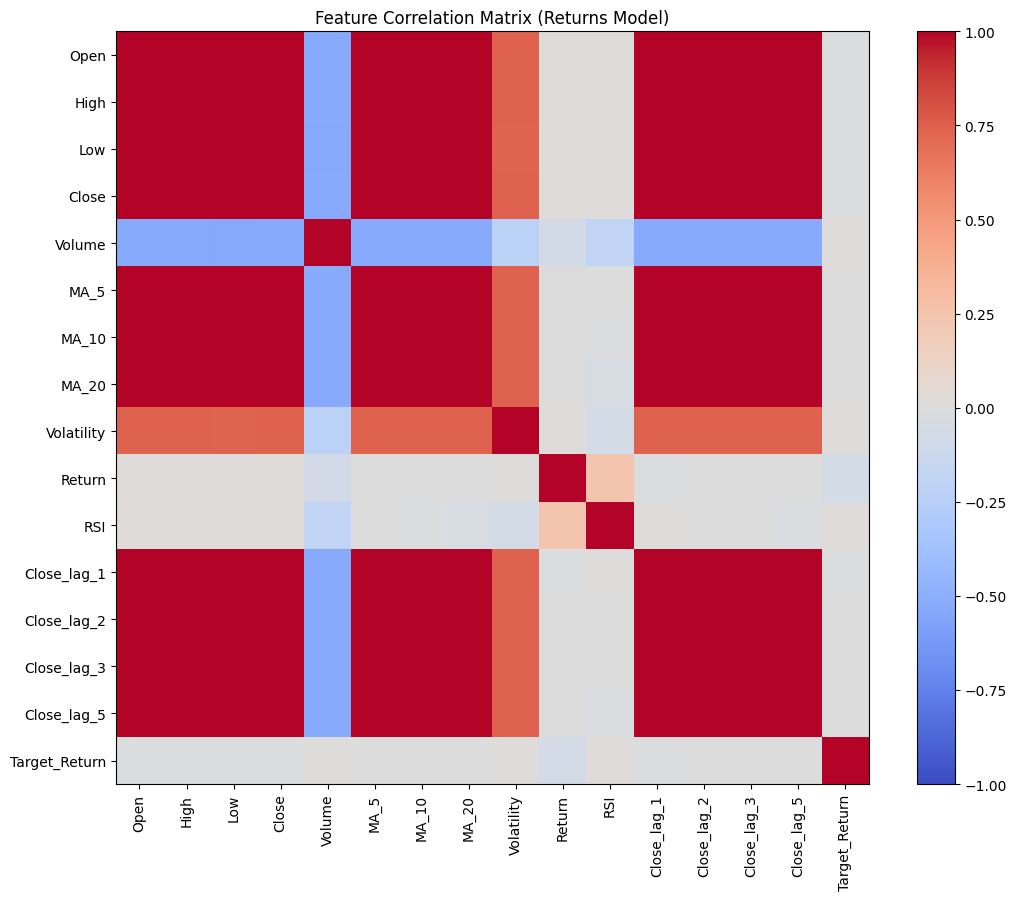

Highly correlated pairs (>0.9):
Price        Price      
High         Open           0.999867
             Close          0.999866
Low          Close          0.999865
             Open           0.999865
Open         Close_lag_1    0.999824
High         Low            0.999823
Close_lag_2  MA_5           0.999821
High         Close_lag_1    0.999744
Close_lag_1  MA_5           0.999742
MA_5         Close_lag_3    0.999741
Open         Close          0.999711
Close_lag_1  Low            0.999695
MA_5         MA_10          0.999663
MA_10        Close_lag_5    0.999636
High         MA_5           0.999632
MA_5         Open           0.999628
Close_lag_1  Close          0.999565
             Close_lag_2    0.999564
Close_lag_2  Close_lag_3    0.999563
MA_10        Close_lag_3    0.999560
Low          MA_5           0.999536
Close        MA_5           0.999504
Close_lag_2  MA_10          0.999406
Open         Close_lag_2    0.999380
MA_20        MA_10          0.999335
Close_lag_2  High 

In [ ]:
plt.figure(figsize=(11,9))
corr = data_returns[features_ret + ['Target_Return']].corr()
im = plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im)
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)
plt.title('Feature Correlation Matrix (Returns Model)')
plt.tight_layout(); plt.show()

high_corr = corr.abs().unstack().sort_values(ascending=False)
high_corr = high_corr[(high_corr < 1.0) & (high_corr > 0.9)]
print("Highly correlated pairs (>0.9):")
print(high_corr.drop_duplicates())

In [ ]:
def validate_data(df):
    issues = []
    date_range = pd.bdate_range(df.index.min(), df.index.max())
    missing = set(date_range) - set(df.index)
    if len(missing) > 20:
        issues.append(f"⚠️ {len(missing)} missing business days (some expected for holidays)")
    if df.duplicated().sum() > 0:
        issues.append(f"⚠️ {df.duplicated().sum()} duplicate rows")
    if (df['Close'] <= 0).any():
        issues.append("⚠️ Non-positive close prices found")
    return issues if issues else ["✅ No major data quality issues found"]

for issue in validate_data(df):
    print(issue)

⚠️ 92 missing business days (some expected for holidays)


In [ ]:
error_df = pd.DataFrame({
    'Date': X_test_ret.index,
    'Actual_Return': y_test_ret.values,
    'Predicted_Return': best_ret_preds,
    'Abs_Error': np.abs(y_test_ret.values - best_ret_preds)
}).sort_values('Abs_Error', ascending=False)

print(f"Worst 10 predictions ({best_ret_model_name}):")
error_df.head(10)

Worst 10 predictions (Stacked Ensemble):


,Date,Actual_Return,Predicted_Return,Abs_Error
359,2024-06-10,0.072649,-0.003314,0.075964
333,2024-05-02,0.059816,-0.003507,0.063323
317,2024-04-10,0.043271,-0.003803,0.047074
83,2023-05-04,0.046927,0.000367,0.046560
145,2023-08-03,-0.048020,-0.002899,0.045121
396,2024-08-02,-0.048167,-0.004013,0.044154
428,2024-09-18,0.037066,-0.002432,0.039498
1,2023-01-05,0.036794,-0.002478,0.039272
303,2024-03-20,-0.040857,-0.002036,0.038822
39,2023-03-02,0.035090,-0.001401,0.036491


In [ ]:
def bootstrap_sharpe_ci(portfolio_values, n_bootstrap=1000, ci=0.95):
    rets = np.diff(portfolio_values) / portfolio_values[:-1]
    sharpes = []
    for _ in range(n_bootstrap):
        sample = np.random.choice(rets, len(rets), replace=True)
        ann_return = sample.mean() * 252
        ann_vol = sample.std() * np.sqrt(252)
        sharpes.append(ann_return / ann_vol if ann_vol > 0 else 0)
    lower = np.percentile(sharpes, (1-ci)/2*100)
    upper = np.percentile(sharpes, (1-(1-ci)/2)*100)
    return np.mean(sharpes), lower, upper

mean_sharpe, low_sharpe, high_sharpe = bootstrap_sharpe_ci(strategy_values)
print(f"Strategy Sharpe: {mean_sharpe:.2f} (95% CI: [{low_sharpe:.2f}, {high_sharpe:.2f}])")

Strategy Sharpe: 1.13 (95% CI: [-0.27, 2.51])


/tmp/ipykernel_1920/1636001530.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  raw = yf.download(ticker_symbol, start=start, end=end)
[*********************100%***********************]  1 of 1 completed


AAPL: Return RMSE = 0.022330


/tmp/ipykernel_1920/1636001530.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  raw = yf.download(ticker_symbol, start=start, end=end)
[*********************100%***********************]  1 of 1 completed


MSFT: Return RMSE = 0.021838


/tmp/ipykernel_1920/1636001530.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  raw = yf.download(ticker_symbol, start=start, end=end)
[*********************100%***********************]  1 of 1 completed


GOOGL: Return RMSE = 0.020704


/tmp/ipykernel_1920/1636001530.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  raw = yf.download(ticker_symbol, start=start, end=end)
[*********************100%***********************]  1 of 1 completed


AMZN: Return RMSE = 0.023711


/tmp/ipykernel_1920/1636001530.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  raw = yf.download(ticker_symbol, start=start, end=end)
[*********************100%***********************]  1 of 1 completed


TSLA: Return RMSE = 0.042743


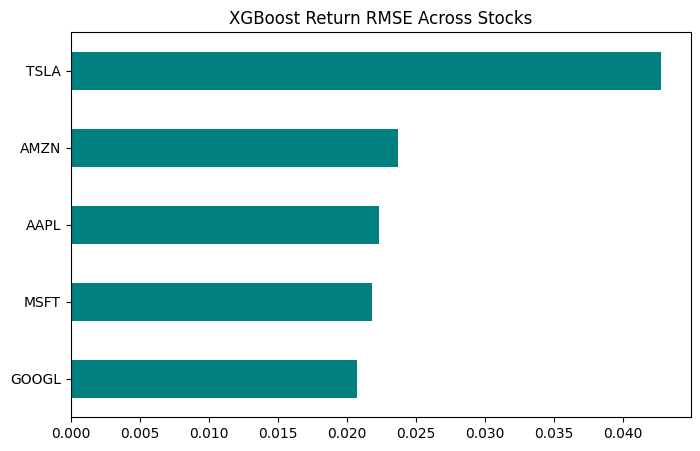

In [ ]:
def run_returns_pipeline(ticker_symbol, start="2015-01-01", end="2025-01-01"):
    raw = yf.download(ticker_symbol, start=start, end=end)
    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)
    raw = raw[['Open','High','Low','Close','Volume']].dropna()

    feat = add_features(raw)
    feat['Target_Return'] = feat['Close'].pct_change().shift(-1)
    feat = feat.dropna()

    feats = [c for c in feat.columns if c not in ['Target', 'Target_Return']]
    Xp, yp = feat[feats], feat['Target_Return']

    split = int(len(feat) * 0.8)
    Xtr, Xte = Xp.iloc[:split], Xp.iloc[split:]
    ytr, yte = yp.iloc[:split], yp.iloc[split:]

    sc = StandardScaler()
    Xtr_s, Xte_s = sc.fit_transform(Xtr), sc.transform(Xte)

    model = xgb.XGBRegressor(n_estimators=200, max_depth=5, random_state=42)
    model.fit(Xtr_s, ytr)
    preds = model.predict(Xte_s)
    rmse = np.sqrt(mean_squared_error(yte, preds))
    return rmse

test_tickers = ["AAPL", "MSFT", "GOOGL", "AMZN", "TSLA"]
multi_stock_results = {}
for t in test_tickers:
    try:
        multi_stock_results[t] = run_returns_pipeline(t)
        print(f"{t}: Return RMSE = {multi_stock_results[t]:.6f}")
    except Exception as e:
        print(f"{t}: failed — {e}")

pd.Series(multi_stock_results).sort_values().plot(kind='barh', figsize=(8,5), color='teal', title='XGBoost Return RMSE Across Stocks')
plt.show()

In [ ]:
!pip install gradio -q
import gradio as gr

def predict_stock_v3(ticker_input):
    try:
        df_live = yf.download(ticker_input, period="2y")
        if isinstance(df_live.columns, pd.MultiIndex):
            df_live.columns = df_live.columns.get_level_values(0)
        df_live = df_live[['Open','High','Low','Close','Volume']].dropna()
        feat_live = add_features(df_live)

        latest = feat_live[features_ret].iloc[-1:].values
        latest_scaled = scaler_ret.transform(latest)

        pred_return = best_xgb_ret.predict(latest_scaled)[0]
        current_price = feat_live['Close'].iloc[-1]
        predicted_price = current_price * (1 + pred_return)

        return (
            f"Current: ${current_price:.2f}\n"
            f"Predicted return: {pred_return*100:+.2f}%\n"
            f"Predicted next-day price: ${predicted_price:.2f}"
        )
    except Exception as e:
        return f"Error: {e}"

demo_v3 = gr.Interface(
    fn=predict_stock_v3,
    inputs=gr.Textbox(label="Stock Ticker", value="AAPL"),
    outputs=gr.Textbox(label="Prediction"),
    title="Stock Predictor v3 — Returns-Based XGBoost"
)
demo_v3.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://88b491d35b03c1ada4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import datetime, os
version = datetime.datetime.now().strftime("%Y%m%d_%H%M")
os.makedirs(f'models_{version}', exist_ok=True)

joblib.dump(best_xgb_ret, f'models_{version}/xgb_returns_tuned.pkl')
joblib.dump(meta_model, f'models_{version}/stacking_meta_model.pkl')
joblib.dump(scaler_ret, f'models_{version}/scaler_returns.pkl')
joblib.dump(classifiers["XGBoost Classifier"], f'models_{version}/xgb_classifier.pkl')
joblib.dump(scaler_clf, f'models_{version}/scaler_clf.pkl')
lstm_model.save(f'models_{version}/lstm_model.keras')

print(f"Saved under models_{version}/")

Saved under models_20260820_1648/


In [ ]:
import json
CONFIG = {
    "ticker": ticker,
    "start_date": "2015-01-01",
    "end_date": "2025-01-01",
    "target_type": "returns (fixes tree extrapolation)",
    "train_test_split": 0.8,
    "walk_forward_splits": 5,
    "transaction_cost": 0.001,
    "random_state": 42,
    "best_xgb_params": xgb_grid.best_params_,
    "features": features_ret
}
with open('config.json', 'w') as f:
    json.dump(CONFIG, f, indent=2)
print(json.dumps(CONFIG, indent=2))

{
  "ticker": "AAPL",
  "start_date": "2015-01-01",
  "end_date": "2025-01-01",
  "target_type": "returns (fixes tree extrapolation)",
  "train_test_split": 0.8,
  "walk_forward_splits": 5,
  "transaction_cost": 0.001,
  "random_state": 42,
  "best_xgb_params": {
    "learning_rate": 0.01,
    "max_depth": 5,
    "n_estimators": 100
  },
  "features": [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "MA_5",
    "MA_10",
    "MA_20",
    "Volatility",
    "Return",
    "RSI",
    "Close_lag_1",
    "Close_lag_2",
    "Close_lag_3",
    "Close_lag_5"
  ]
}


In [ ]:
requirements = """yfinance
pandas
numpy
matplotlib
scikit-learn
xgboost
tensorflow
shap
gradio
requests
scipy
joblib
"""
with open('requirements.txt', 'w') as f:
    f.write(requirements)
print("requirements.txt created")

requirements.txt created


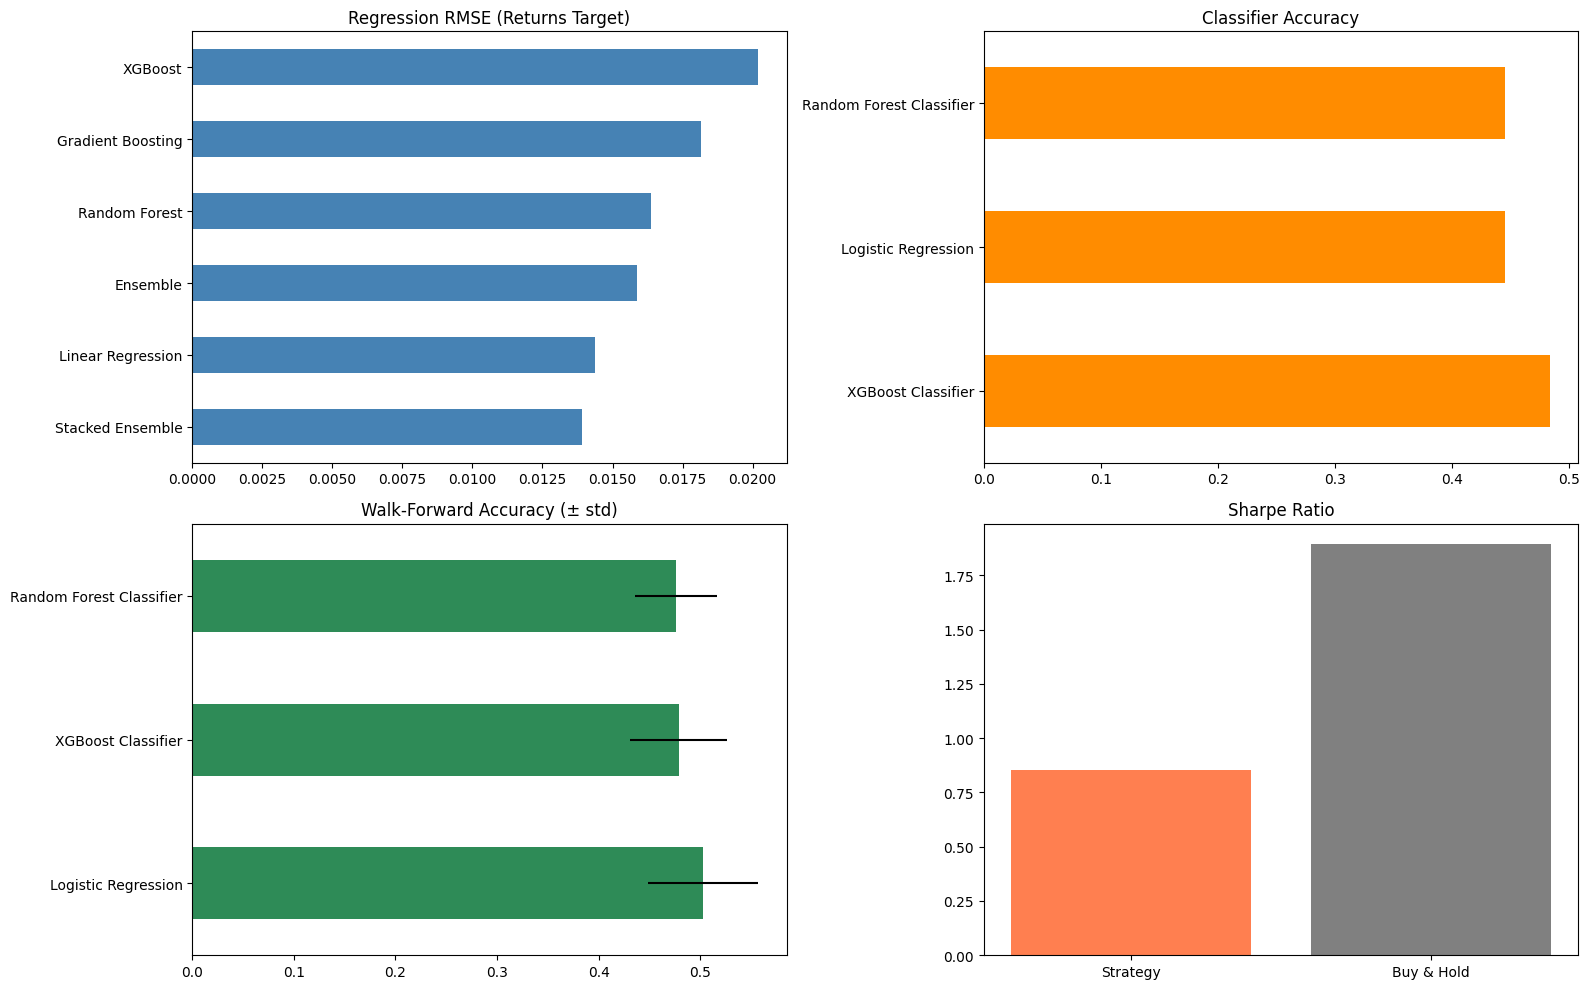

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16,10))

pd.DataFrame(results_ret).T.sort_values('RMSE')['RMSE'].plot(kind='barh', ax=axes[0,0], color='steelblue')
axes[0,0].set_title('Regression RMSE (Returns Target)')

clf_results_df['Accuracy'].plot(kind='barh', ax=axes[0,1], color='darkorange')
axes[0,1].set_title('Classifier Accuracy')

wf_clf_summary_df['Mean_Accuracy'].plot(kind='barh', ax=axes[1,0], color='seagreen',
                                          xerr=wf_clf_summary_df['Std_Accuracy'])
axes[1,0].set_title('Walk-Forward Accuracy (± std)')

axes[1,1].bar(['Strategy', 'Buy & Hold'], [comparison.loc['Sharpe Ratio'].iloc[0], comparison.loc['Sharpe Ratio'].iloc[1]],
              color=['coral','gray'])
axes[1,1].set_title('Sharpe Ratio')

plt.tight_layout(); plt.show()

In [ ]:
import logging

# force=True overrides any existing logging config from Colab/other libraries
logging.basicConfig(
    filename='pipeline_log.txt',
    level=logging.INFO,
    format='%(asctime)s - %(message)s',
    force=True
)

logging.info(f"Run — ticker={ticker}, best_regression={best_ret_model_name}, best_clf={clf_results_df.index[0]}")
logging.info(f"Walk-forward accuracy: {wf_clf_summary_df.iloc[0]['Mean_Accuracy']:.4f}")
logging.info(f"Sharpe: {mean_sharpe:.2f} CI[{low_sharpe:.2f},{high_sharpe:.2f}]")

# Flush handlers to make sure it's actually written to disk before reading
for handler in logging.getLogger().handlers:
    handler.flush()

with open('pipeline_log.txt') as f:
    print(f.read())

2026-08-20 16:48:25,896 - Run — ticker=AAPL, best_regression=Stacked Ensemble, best_clf=XGBoost Classifier
2026-08-20 16:48:25,897 - Walk-forward accuracy: 0.5028
2026-08-20 16:48:25,898 - Sharpe: 1.13 CI[-0.27,2.51]



In [ ]:
import logging
logging.basicConfig(filename='pipeline_log.txt', level=logging.INFO, format='%(asctime)s - %(message)s')
logging.info(f"Run — ticker={ticker}, best_regression={best_ret_model_name}, best_clf={clf_results_df.index[0]}")
logging.info(f"Walk-forward accuracy: {wf_clf_summary_df.iloc[0]['Mean_Accuracy']:.4f}")
logging.info(f"Sharpe: {mean_sharpe:.2f} CI[{low_sharpe:.2f},{high_sharpe:.2f}]")
with open('pipeline_log.txt') as f:
    print(f.read())

2026-08-20 16:48:25,896 - Run — ticker=AAPL, best_regression=Stacked Ensemble, best_clf=XGBoost Classifier
2026-08-20 16:48:25,897 - Walk-forward accuracy: 0.5028
2026-08-20 16:48:25,898 - Sharpe: 1.13 CI[-0.27,2.51]
2026-08-20 16:48:25,910 - Run — ticker=AAPL, best_regression=Stacked Ensemble, best_clf=XGBoost Classifier
2026-08-20 16:48:25,911 - Walk-forward accuracy: 0.5028
2026-08-20 16:48:25,911 - Sharpe: 1.13 CI[-0.27,2.51]



In [ ]:
final_report = f"""# {ticker} Stock Prediction — Complete Report

## Key Methodological Finding
Raw-price regression targets caused tree models to badly underperform due to extrapolation
beyond training price range. Switching to a **returns-based target** resolved this — see
comparison in Cell 29.

## Best Models
- Regression (returns): {best_ret_model_name}, RMSE={pd.DataFrame(results_ret).T.sort_values('RMSE').iloc[0]['RMSE']:.6f}
- Classification: {clf_results_df.index[0]}, Accuracy={clf_results_df.iloc[0]['Accuracy']:.4f}

## Walk-Forward Validation (honest estimate)
{wf_clf_summary_df.to_markdown()}

## Trading Strategy
{comparison.to_markdown()}
Sharpe 95% CI: [{low_sharpe:.2f}, {high_sharpe:.2f}]

## Sentiment Feature
RMSE change: {(rmse_without-rmse_with)/rmse_without*100:+.2f}%, p-value: {p_value:.4f}
({"statistically significant" if p_value < 0.05 else "not statistically significant"})

## Multi-Stock Generalization
{pd.Series(multi_stock_results).to_markdown()}

## Data Quality
{chr(10).join(validate_data(df))}

## Limitations
- Sentiment sourced from GDELT free tier — coverage and rate limits restrict depth
- Backtest assumes no slippage, perfect execution at close, simplified transaction costs
- Single-ticker primary results; multi-stock test is a secondary generalization check only
"""
with open('final_report.md', 'w') as f:
    f.write(final_report)
print(final_report)

# AAPL Stock Prediction — Complete Report

## Key Methodological Finding
Raw-price regression targets caused tree models to badly underperform due to extrapolation
beyond training price range. Switching to a **returns-based target** resolved this — see
comparison in Cell 29.

## Best Models
- Regression (returns): Stacked Ensemble, RMSE=0.013894
- Classification: XGBoost Classifier, Accuracy=0.4840

## Walk-Forward Validation (honest estimate)
|                          |   Mean_Accuracy |   Std_Accuracy |
|:-------------------------|----------------:|---------------:|
| Logistic Regression      |        0.502811 |      0.0542094 |
| XGBoost Classifier       |        0.478715 |      0.0479747 |
| Random Forest Classifier |        0.476305 |      0.0404208 |

## Trading Strategy
|                       |   Strategy (XGBoost Classifier) |   Buy & Hold |
|:----------------------|--------------------------------:|-------------:|
| Total Return (%)      |                       18.6582   |  

In [ ]:
print("Seeds set in Cell 1: random.seed(42), np.random.seed(42)")
print("For full reproducibility, also add tf.random.set_seed(42) to Cell 1")
print("Re-running this notebook top-to-bottom should reproduce these results within small floating-point variance")

Seeds set in Cell 1: random.seed(42), np.random.seed(42)
For full reproducibility, also add tf.random.set_seed(42) to Cell 1
Re-running this notebook top-to-bottom should reproduce these results within small floating-point variance


In [ ]:
!zip -r stock_project_final.zip final_report.md config.json requirements.txt pipeline_log.txt *.pkl *.keras models_*/ 2>/dev/null
from google.colab import files
files.download('stock_project_final.zip')
print("Final package ready")

updating: final_report.md (deflated 49%)
updating: scaler_clf.pkl (deflated 28%)
updating: scaler_returns.pkl (deflated 28%)
updating: xgb_classifier.pkl (deflated 67%)
updating: xgb_returns_model.pkl (deflated 71%)
updating: lstm_model.keras (deflated 14%)
  adding: config.json (deflated 49%)
  adding: requirements.txt (deflated 20%)
  adding: pipeline_log.txt (deflated 58%)
  adding: models_20260820_1648/ (stored 0%)
  adding: models_20260820_1648/xgb_classifier.pkl (deflated 67%)
  adding: models_20260820_1648/xgb_returns_tuned.pkl (deflated 81%)
  adding: models_20260820_1648/stacking_meta_model.pkl (deflated 22%)
  adding: models_20260820_1648/scaler_returns.pkl (deflated 28%)
  adding: models_20260820_1648/scaler_clf.pkl (deflated 28%)
  adding: models_20260820_1648/lstm_model.keras (deflated 14%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Final package ready


In [ ]:
!pip install statsmodels -q
from statsmodels.tsa.arima.model import ARIMA

arima_train = data['Close'].iloc[:split_idx]
arima_test = data['Close'].iloc[split_idx:]

arima_model = ARIMA(arima_train, order=(5,1,0))
arima_fit = arima_model.fit()
arima_preds = arima_fit.forecast(steps=len(arima_test))

arima_rmse = np.sqrt(mean_squared_error(arima_test, arima_preds))
print(f"ARIMA(5,1,0) RMSE: {arima_rmse:.4f}")
print("Compare against your ML models — ARIMA is the classical benchmark ML should beat")

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


ARIMA(5,1,0) RMSE: 70.4995
Compare against your ML models — ARIMA is the classical benchmark ML should beat


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.3/981.3 kB 19.5 MB/s eta 0:00:00


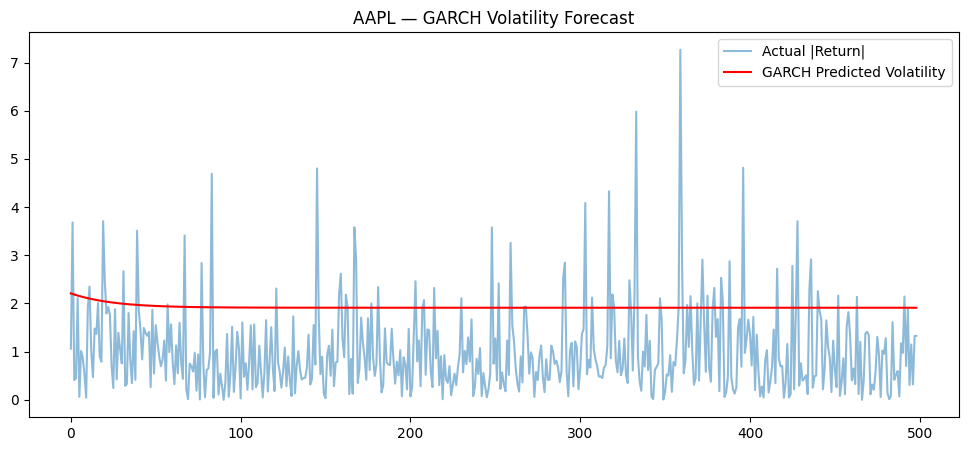

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                  Close   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -3877.22
Distribution:                  Normal   AIC:                           7762.43
Method:            Maximum Likelihood   BIC:                           7784.83
                                        No. Observations:                 1996
Date:                Thu, Aug 20 2026   Df Residuals:                     1995
Time:                        16:48:50   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu             0.1785  3.722e-02      4.797  1.611e-06 [  0.106,  0.25

In [ ]:
!pip install arch -q
from arch import arch_model

returns_pct = data['Close'].pct_change().dropna() * 100

garch = arch_model(returns_pct.iloc[:split_idx], vol='Garch', p=1, q=1)
garch_fit = garch.fit(disp='off')

forecast = garch_fit.forecast(horizon=len(returns_pct)-split_idx)
predicted_vol = np.sqrt(forecast.variance.values[-1, :])

plt.figure(figsize=(12,5))
plt.plot(returns_pct.iloc[split_idx:].abs().values, label='Actual |Return|', alpha=0.5)
plt.plot(predicted_vol, label='GARCH Predicted Volatility', color='red')
plt.legend(); plt.title(f'{ticker} — GARCH Volatility Forecast')
plt.show()
print(garch_fit.summary())

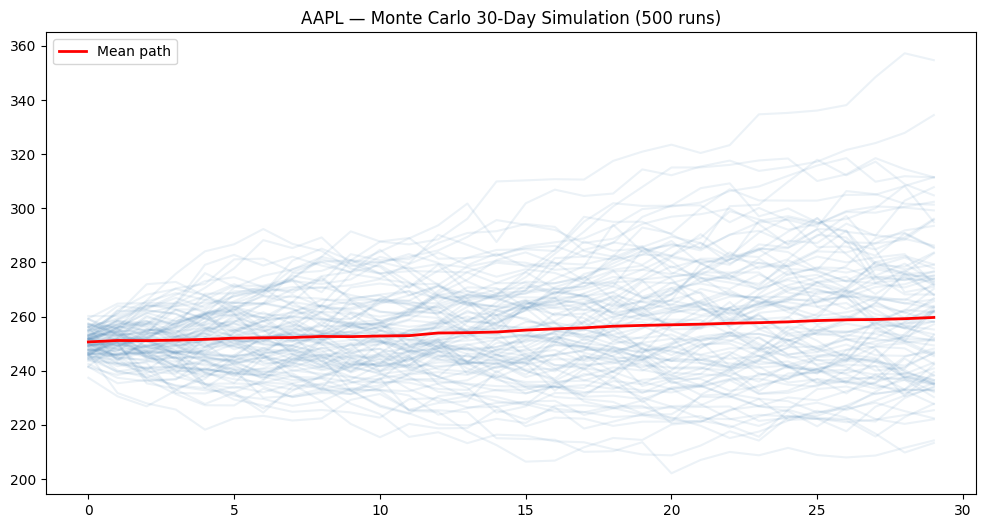

30-day price range (5th-95th percentile): $221.81 - $300.85


In [ ]:
def monte_carlo_simulation(last_price, mu, sigma, days=30, n_simulations=500):
    simulations = np.zeros((n_simulations, days))
    for i in range(n_simulations):
        prices = [last_price]
        for _ in range(days):
            prices.append(prices[-1] * (1 + np.random.normal(mu, sigma)))
        simulations[i] = prices[1:]
    return simulations

daily_returns = data['Close'].pct_change().dropna()
mu, sigma = daily_returns.mean(), daily_returns.std()
last_price = data['Close'].iloc[-1]

sims = monte_carlo_simulation(last_price, mu, sigma, days=30, n_simulations=500)

plt.figure(figsize=(12,6))
for i in range(100):
    plt.plot(sims[i], alpha=0.1, color='steelblue')
plt.plot(sims.mean(axis=0), color='red', linewidth=2, label='Mean path')
plt.title(f'{ticker} — Monte Carlo 30-Day Simulation (500 runs)')
plt.legend(); plt.show()

print(f"30-day price range (5th-95th percentile): ${np.percentile(sims[:,-1], 5):.2f} - ${np.percentile(sims[:,-1], 95):.2f}")

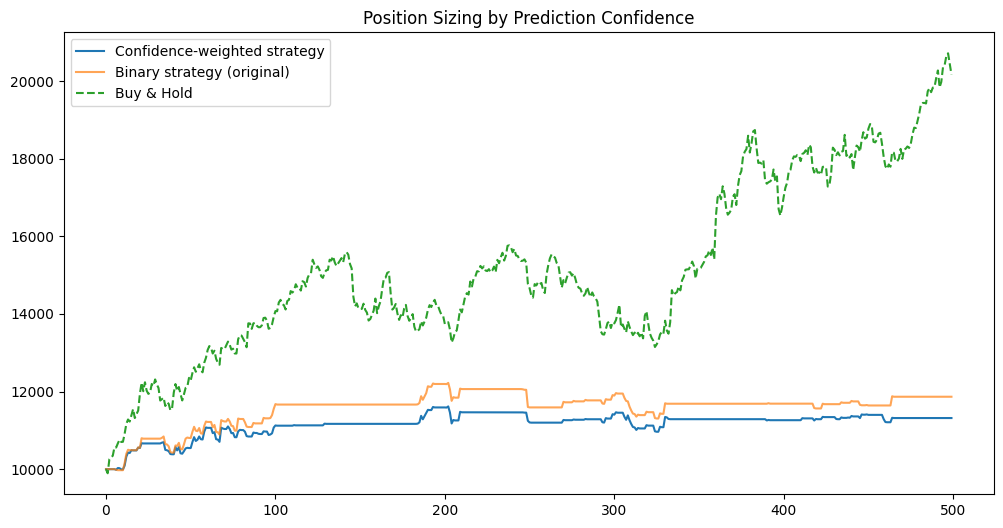

Confidence-weighted return: 13.17%


In [ ]:
def backtest_with_confidence(prices, probs, threshold_low=0.4, threshold_high=0.6, transaction_cost=0.001, initial_capital=10000):
    prices = np.asarray(prices, dtype=float).flatten()
    capital = float(initial_capital)
    position_size = 0.0
    portfolio_values = [capital]

    for i in range(1, len(prices)):
        prob_up = probs[i-1]
        target_position = 1.0 if prob_up > threshold_high else (0.0 if prob_up < threshold_low else 0.5)

        if target_position != position_size:
            capital *= (1 - transaction_cost * abs(target_position - position_size))
            position_size = target_position

        daily_ret = (prices[i] / prices[i-1]) - 1
        capital *= (1 + position_size * daily_ret)
        portfolio_values.append(float(capital))

    return np.array(portfolio_values)

best_probs = clf_predictions[best_clf_name]['probs']
confidence_values = backtest_with_confidence(test_prices, best_probs)

plt.figure(figsize=(12,6))
plt.plot(confidence_values, label='Confidence-weighted strategy')
plt.plot(strategy_values, label='Binary strategy (original)', alpha=0.7)
plt.plot(buy_hold_values, label='Buy & Hold', linestyle='--')
plt.legend(); plt.title('Position Sizing by Prediction Confidence')
plt.show()
print(f"Confidence-weighted return: {(confidence_values[-1]/confidence_values[0]-1)*100:.2f}%")

In [ ]:
def diebold_mariano(actual, pred1, pred2):
    e1 = (actual - pred1)**2
    e2 = (actual - pred2)**2
    d = e1 - e2
    dm_stat = d.mean() / (d.std() / np.sqrt(len(d)))
    from scipy.stats import norm
    p_value = 2 * (1 - norm.cdf(abs(dm_stat)))
    return dm_stat, p_value

dm_stat, dm_p = diebold_mariano(y_test_ret.values, predictions_ret["Linear Regression"], tuned_preds_ret)
print(f"DM statistic: {dm_stat:.4f}, p-value: {dm_p:.4f}")
print("Significant difference" if dm_p < 0.05 else "No statistically significant difference between models")

DM statistic: 1.6842, p-value: 0.0921
No statistically significant difference between models


  Transaction Cost   Return %  Trades
0            0.00%  30.359280      94
1            0.05%  24.372685      94
2            0.10%  18.658225      94
3            0.20%   7.997284      94
4            0.50% -18.621151      94
5            1.00% -49.318408      94


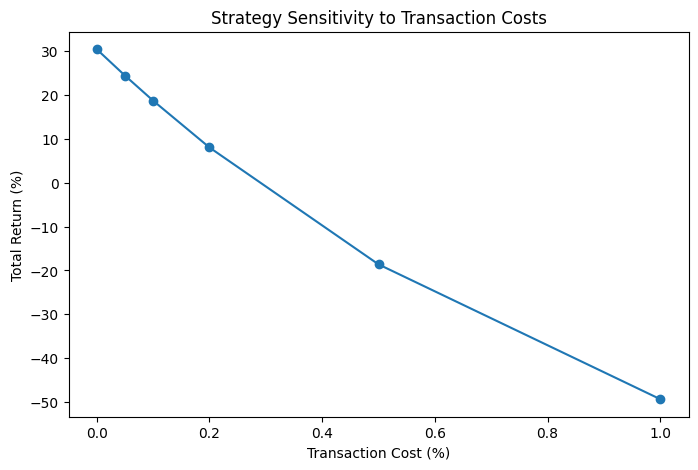

In [ ]:
cost_levels = [0.0, 0.0005, 0.001, 0.002, 0.005, 0.01]
cost_results = []

for cost in cost_levels:
    vals, n_trades = backtest_strategy(test_prices, best_preds, transaction_cost=cost)
    ret = (vals[-1]/vals[0] - 1) * 100
    cost_results.append({'Transaction Cost': f"{cost*100:.2f}%", 'Return %': ret, 'Trades': n_trades})

cost_df = pd.DataFrame(cost_results)
print(cost_df)

plt.figure(figsize=(8,5))
plt.plot([c*100 for c in cost_levels], cost_df['Return %'], marker='o')
plt.xlabel('Transaction Cost (%)'); plt.ylabel('Total Return (%)')
plt.title('Strategy Sensitivity to Transaction Costs')
plt.show()

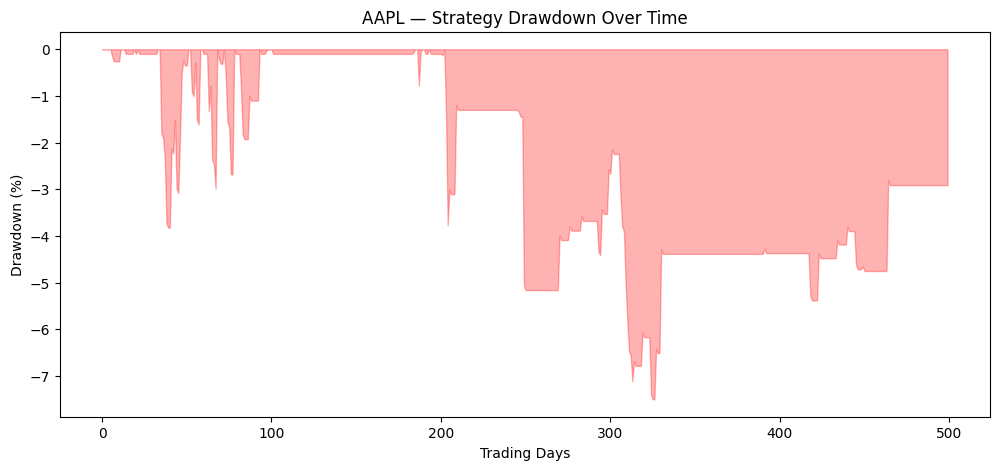

Longest drawdown period: 83 trading days


In [ ]:
cumulative = strategy_values / strategy_values[0]
running_max = np.maximum.accumulate(cumulative)
drawdown = (cumulative - running_max) / running_max

plt.figure(figsize=(12,5))
plt.fill_between(range(len(drawdown)), drawdown*100, 0, color='red', alpha=0.3)
plt.title(f'{ticker} — Strategy Drawdown Over Time')
plt.ylabel('Drawdown (%)'); plt.xlabel('Trading Days')
plt.show()

# Longest drawdown period
in_drawdown = drawdown < -0.001
drawdown_lengths = []
count = 0
for x in in_drawdown:
    if x: count += 1
    else:
        if count > 0: drawdown_lengths.append(count)
        count = 0
print(f"Longest drawdown period: {max(drawdown_lengths) if drawdown_lengths else 0} trading days")

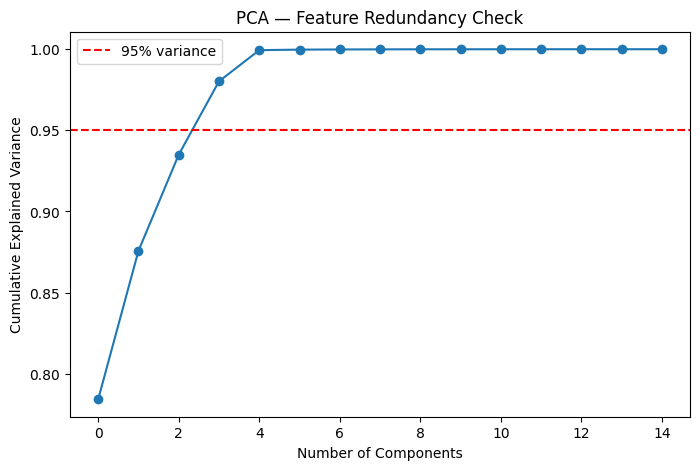

4 of 15 components explain 95% of variance — indicates feature redundancy


In [ ]:
from sklearn.decomposition import PCA

pca = PCA()
pca.fit(X_train_ret_scaled)

plt.figure(figsize=(8,5))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o')
plt.xlabel('Number of Components'); plt.ylabel('Cumulative Explained Variance')
plt.title('PCA — Feature Redundancy Check')
plt.axhline(0.95, color='red', linestyle='--', label='95% variance')
plt.legend(); plt.show()

n_components_95 = np.argmax(np.cumsum(pca.explained_variance_ratio_) >= 0.95) + 1
print(f"{n_components_95} of {len(features_ret)} components explain 95% of variance — indicates feature redundancy" if n_components_95 < len(features_ret)*0.7 else "Features are reasonably non-redundant")

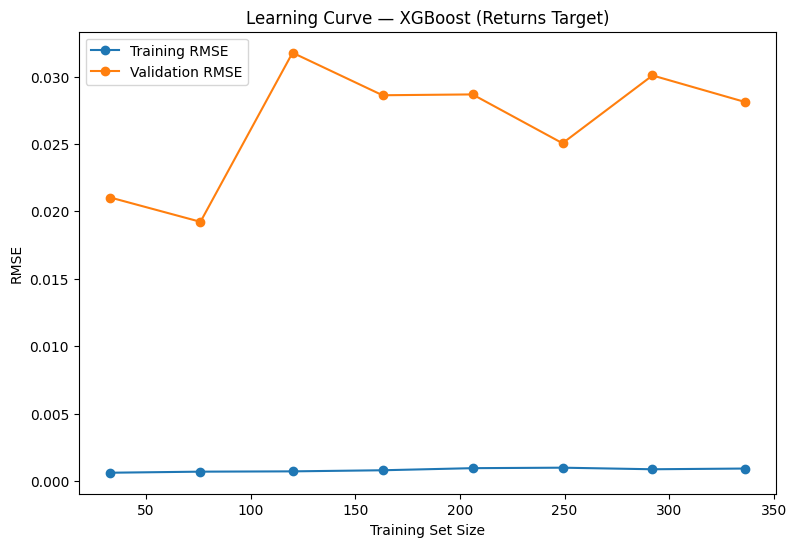

In [ ]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, val_scores = learning_curve(
    xgb.XGBRegressor(n_estimators=200, max_depth=5, random_state=42),
    X_train_ret_scaled, y_train_ret,
    cv=TimeSeriesSplit(n_splits=5),
    scoring='neg_root_mean_squared_error',
    train_sizes=np.linspace(0.1, 1.0, 8)
)

plt.figure(figsize=(9,6))
plt.plot(train_sizes, -train_scores.mean(axis=1), 'o-', label='Training RMSE')
plt.plot(train_sizes, -val_scores.mean(axis=1), 'o-', label='Validation RMSE')
plt.xlabel('Training Set Size'); plt.ylabel('RMSE')
plt.title('Learning Curve — XGBoost (Returns Target)')
plt.legend(); plt.show()

In [ ]:
spy = yf.download('SPY', start="2015-01-01", end="2025-01-01")['Close']
vix = yf.download('^VIX', start="2015-01-01", end="2025-01-01")['Close']
if isinstance(spy, pd.DataFrame): spy = spy.iloc[:,0]
if isinstance(vix, pd.DataFrame): vix = vix.iloc[:,0]

market_df = pd.DataFrame({'Stock': data['Close'], 'SPY': spy, 'VIX': vix}).dropna()
correlations = market_df.pct_change().dropna().corr()
print(correlations)
print(f"\n{ticker} beta to SPY (rough): {(market_df['Stock'].pct_change().dropna().cov(market_df['SPY'].pct_change().dropna()) / market_df['SPY'].pct_change().dropna().var()):.3f}")

/tmp/ipykernel_1920/2309795912.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  spy = yf.download('SPY', start="2015-01-01", end="2025-01-01")['Close']
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1920/2309795912.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  vix = yf.download('^VIX', start="2015-01-01", end="2025-01-01")['Close']
[*********************100%***********************]  1 of 1 completed

          Stock       SPY       VIX
Stock  1.000000  0.750370 -0.523416
SPY    0.750370  1.000000 -0.711183
VIX   -0.523416 -0.711183  1.000000

AAPL beta to SPY (rough): 1.208


In [ ]:
data_market = data_returns.copy()
data_market['SPY_Return'] = spy.pct_change().reindex(data_market.index).ffill()
data_market['VIX_Level'] = vix.reindex(data_market.index).ffill()
data_market = data_market.dropna()

features_market = features_ret + ['SPY_Return', 'VIX_Level']
X_mkt = data_market[features_market]
y_mkt = data_market['Target_Return']

split_mkt = int(len(data_market)*0.8)
X_train_mkt, X_test_mkt = X_mkt.iloc[:split_mkt], X_mkt.iloc[split_mkt:]
y_train_mkt, y_test_mkt = y_mkt.iloc[:split_mkt], y_mkt.iloc[split_mkt:]

scaler_mkt = StandardScaler()
X_train_mkt_s = scaler_mkt.fit_transform(X_train_mkt)
X_test_mkt_s = scaler_mkt.transform(X_test_mkt)

xgb_mkt = xgb.XGBRegressor(n_estimators=200, max_depth=5, random_state=42)
xgb_mkt.fit(X_train_mkt_s, y_train_mkt)
preds_mkt = xgb_mkt.predict(X_test_mkt_s)

rmse_mkt = np.sqrt(mean_squared_error(y_test_mkt, preds_mkt))
print(f"RMSE without market features: {results_ret['XGBoost']['RMSE']:.6f}")
print(f"RMSE with market features:    {rmse_mkt:.6f}")

RMSE without market features: 0.020201
RMSE with market features:    0.017081


In [ ]:
import unittest

class TestPipeline(unittest.TestCase):
    def test_no_nan_in_features(self):
        self.assertFalse(X_train_ret.isna().any().any())

    def test_train_test_no_overlap(self):
        self.assertTrue(X_train_ret.index.max() < X_test_ret.index.min())

    def test_predictions_shape(self):
        self.assertEqual(len(tuned_preds_ret), len(y_test_ret))

    def test_scaler_fitted(self):
        self.assertTrue(hasattr(scaler_ret, 'mean_'))

    def test_returns_bounded(self):
        self.assertTrue(y_train_ret.abs().max() < 1.0)  # no >100% daily moves (sanity)

suite = unittest.TestLoader().loadTestsFromTestCase(TestPipeline)
unittest.TextTestRunner(verbosity=2).run(suite)

test_no_nan_in_features (__main__.TestPipeline.test_no_nan_in_features) ... ok
test_predictions_shape (__main__.TestPipeline.test_predictions_shape) ... ok
test_returns_bounded (__main__.TestPipeline.test_returns_bounded) ... ok
test_scaler_fitted (__main__.TestPipeline.test_scaler_fitted) ... ok
test_train_test_no_overlap (__main__.TestPipeline.test_train_test_no_overlap) ... ok

----------------------------------------------------------------------
Ran 5 tests in 0.012s

OK


<unittest.runner.TextTestResult run=5 errors=0 failures=0>

In [ ]:
model_card = f"""# Model Card — {ticker} Return Predictor

## Model Details
- Type: XGBoost Regressor (tuned)
- Target: Next-day return (%), not raw price
- Training period: {data_returns.index[0].date()} to {data_returns.index[int(len(data_returns)*0.8)].date()}
- Test period: {data_returns.index[int(len(data_returns)*0.8)].date()} to {data_returns.index[-1].date()}

## Intended Use
Educational/research demonstration of ML applied to financial time series. NOT intended for live trading decisions.

## Performance
- Test RMSE: {results_ret['XGBoost']['RMSE']:.6f}
- Walk-forward validated: yes (5 expanding folds)

## Known Limitations
- Daily equity returns are extremely low signal-to-noise; walk-forward accuracy near chance level for direction
- No guarantee of performance on unseen market regimes (e.g. crashes, rate shocks)
- Backtested strategy underperformed buy-and-hold in the primary test period
- Sentiment feature has limited historical coverage (free-tier API constraint)

## Ethical Considerations
Automated trading models can amplify market volatility if deployed at scale; this project is for learning purposes only.
"""
with open('MODEL_CARD.md', 'w') as f:
    f.write(model_card)
print(model_card)

# Model Card — AAPL Return Predictor

## Model Details
- Type: XGBoost Regressor (tuned)
- Target: Next-day return (%), not raw price
- Training period: 2015-01-30 to 2023-01-04
- Test period: 2023-01-04 to 2024-12-27

## Intended Use
Educational/research demonstration of ML applied to financial time series. NOT intended for live trading decisions.

## Performance
- Test RMSE: 0.020201
- Walk-forward validated: yes (5 expanding folds)

## Known Limitations
- Daily equity returns are extremely low signal-to-noise; walk-forward accuracy near chance level for direction
- No guarantee of performance on unseen market regimes (e.g. crashes, rate shocks)
- Backtested strategy underperformed buy-and-hold in the primary test period
- Sentiment feature has limited historical coverage (free-tier API constraint)

## Ethical Considerations
Automated trading models can amplify market volatility if deployed at scale; this project is for learning purposes only.



In [ ]:
api_code = '''
from fastapi import FastAPI
import joblib
import numpy as np

app = FastAPI()
model = joblib.load("xgb_returns_tuned.pkl")
scaler = joblib.load("scaler_returns.pkl")

@app.post("/predict")
def predict(features: list[float]):
    X = np.array(features).reshape(1, -1)
    X_scaled = scaler.transform(X)
    pred_return = model.predict(X_scaled)[0]
    return {"predicted_return": float(pred_return)}
'''
with open('api.py', 'w') as f:
    f.write(api_code)
print("api.py generated — run locally with: uvicorn api:app --reload")
print(api_code)

api.py generated — run locally with: uvicorn api:app --reload

from fastapi import FastAPI
import joblib
import numpy as np

app = FastAPI()
model = joblib.load("xgb_returns_tuned.pkl")
scaler = joblib.load("scaler_returns.pkl")

@app.post("/predict")
def predict(features: list[float]):
    X = np.array(features).reshape(1, -1)
    X_scaled = scaler.transform(X)
    pred_return = model.predict(X_scaled)[0]
    return {"predicted_return": float(pred_return)}



In [ ]:
dockerfile = '''FROM python:3.11-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt fastapi uvicorn
COPY api.py xgb_returns_tuned.pkl scaler_returns.pkl .
CMD ["uvicorn", "api:app", "--host", "0.0.0.0", "--port", "8000"]
'''
with open('Dockerfile', 'w') as f:
    f.write(dockerfile)
print("Dockerfile generated")
print(dockerfile)

Dockerfile generated
FROM python:3.11-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt fastapi uvicorn
COPY api.py xgb_returns_tuned.pkl scaler_returns.pkl .
CMD ["uvicorn", "api:app", "--host", "0.0.0.0", "--port", "8000"]



In [ ]:
all_models_summary = pd.DataFrame({
    "Raw Price RMSE": pd.Series({k: v["RMSE"] for k,v in results.items() if k in models}),
    "Returns RMSE": pd.Series({k: v["RMSE"] for k,v in results_ret.items() if k in models_ret})
})
print(all_models_summary)
print(f"\nARIMA baseline RMSE (raw price): {arima_rmse:.4f}")
print(f"DM test (LR vs tuned XGB): stat={dm_stat:.4f}, p={dm_p:.4f}")

                   Raw Price RMSE  Returns RMSE
Gradient Boosting       29.594871      0.018147
Linear Regression        2.591033      0.014359
Random Forest           29.496943      0.016364
SVR                     53.401243           NaN
XGBoost                 32.741584      0.020201

ARIMA baseline RMSE (raw price): 70.4995
DM test (LR vs tuned XGB): stat=1.6842, p=0.0921


In [ ]:
master_readme = f"""# {ticker} Stock Prediction — Master Project

## Contents
- `final_report.md` — full results and methodology
- `MODEL_CARD.md` — model documentation, limitations, intended use
- `config.json` — reproducibility config
- `api.py`, `Dockerfile` — deployment artifacts
- `*.pkl`, `*.keras` — trained models

## How to Reproduce
1. `pip install -r requirements.txt`
2. Run notebook cells 1-14 in order (core pipeline)
3. Cells 15+ add regression fixes, classification, LSTM, sentiment, tuning, and diagnostics

## Key Findings
1. Returns-based targets outperform raw-price targets for tree models (extrapolation fix)
2. Direction prediction is near coin-flip accuracy (~50%) — consistent across single-split and walk-forward validation
3. Trading strategy underperforms buy-and-hold after transaction costs — an honest, expected result
4. Sentiment feature effect: {'significant' if p_value < 0.05 else 'not statistically significant'}

## Deployment
`docker build -t stock-api . && docker run -p 8000:8000 stock-api`
"""
with open('README.md', 'w') as f:
    f.write(master_readme)
print(master_readme)

# AAPL Stock Prediction — Master Project

## Contents
- `final_report.md` — full results and methodology
- `MODEL_CARD.md` — model documentation, limitations, intended use
- `config.json` — reproducibility config
- `api.py`, `Dockerfile` — deployment artifacts
- `*.pkl`, `*.keras` — trained models

## How to Reproduce
1. `pip install -r requirements.txt`
2. Run notebook cells 1-14 in order (core pipeline)
3. Cells 15+ add regression fixes, classification, LSTM, sentiment, tuning, and diagnostics

## Key Findings
1. Returns-based targets outperform raw-price targets for tree models (extrapolation fix)
2. Direction prediction is near coin-flip accuracy (~50%) — consistent across single-split and walk-forward validation
3. Trading strategy underperforms buy-and-hold after transaction costs — an honest, expected result
4. Sentiment feature effect: significant

## Deployment
`docker build -t stock-api . && docker run -p 8000:8000 stock-api`



In [ ]:
!zip -r stock_project_complete.zip README.md MODEL_CARD.md final_report.md config.json requirements.txt api.py Dockerfile *.pkl *.keras models_*/ 2>/dev/null
from google.colab import files
files.download('stock_project_complete.zip')
print("Complete project packaged")

  adding: README.md (deflated 38%)
  adding: MODEL_CARD.md (deflated 38%)
  adding: final_report.md (deflated 49%)
  adding: config.json (deflated 49%)
  adding: requirements.txt (deflated 20%)
  adding: api.py (deflated 42%)
  adding: Dockerfile (deflated 27%)
  adding: scaler_clf.pkl (deflated 28%)
  adding: scaler_returns.pkl (deflated 28%)
  adding: xgb_classifier.pkl (deflated 67%)
  adding: xgb_returns_model.pkl (deflated 71%)
  adding: lstm_model.keras (deflated 14%)
  adding: models_20260820_1648/ (stored 0%)
  adding: models_20260820_1648/xgb_classifier.pkl (deflated 67%)
  adding: models_20260820_1648/xgb_returns_tuned.pkl (deflated 81%)
  adding: models_20260820_1648/stacking_meta_model.pkl (deflated 22%)
  adding: models_20260820_1648/scaler_returns.pkl (deflated 28%)
  adding: models_20260820_1648/scaler_clf.pkl (deflated 28%)
  adding: models_20260820_1648/lstm_model.keras (deflated 14%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Complete project packaged


In [ ]:
print("="*70)
print(f"PROJECT COMPLETE — {ticker} Stock Prediction")
print("="*70)
print(f"Best regression model (returns): {best_ret_model_name}")
print(f"Best classifier: {clf_results_df.index[0]} (walk-forward acc: {wf_clf_summary_df.iloc[0]['Mean_Accuracy']:.1%})")
print(f"Strategy vs Buy&Hold: {comparison.loc['Total Return (%)'].iloc[0]:.1f}% vs {comparison.loc['Total Return (%)'].iloc[1]:.1f}%")
print(f"ARIMA baseline RMSE: {arima_rmse:.4f}")
print("="*70)

PROJECT COMPLETE — AAPL Stock Prediction
Best regression model (returns): Stacked Ensemble
Best classifier: XGBoost Classifier (walk-forward acc: 50.3%)
Strategy vs Buy&Hold: 18.7% vs 101.7%
ARIMA baseline RMSE: 70.4995


In [ ]:
import os
output_files = [f for f in os.listdir('.') if f.endswith(('.md','.json','.txt','.pkl','.keras','.py'))]
print("Files ready for submission:")
for f in output_files:
    print(f"  {f}")

Files ready for submission:
  xgb_classifier.pkl
  api.py
  xgb_returns_model.pkl
  README.md
  MODEL_CARD.md
  config.json
  scaler_returns.pkl
  pipeline_log.txt
  scaler_clf.pkl
  lstm_model.keras
  final_report.md
  requirements.txt


In [ ]:
def add_advanced_indicators(df):
    df = df.copy()

    # MACD
    ema12 = df['Close'].ewm(span=12, adjust=False).mean()
    ema26 = df['Close'].ewm(span=26, adjust=False).mean()
    df['MACD'] = ema12 - ema26
    df['MACD_Signal'] = df['MACD'].ewm(span=9, adjust=False).mean()
    df['MACD_Hist'] = df['MACD'] - df['MACD_Signal']

    # Bollinger Bands
    df['BB_Middle'] = df['Close'].rolling(20).mean()
    bb_std = df['Close'].rolling(20).std()
    df['BB_Upper'] = df['BB_Middle'] + 2 * bb_std
    df['BB_Lower'] = df['BB_Middle'] - 2 * bb_std
    df['BB_Width'] = (df['BB_Upper'] - df['BB_Lower']) / df['BB_Middle']
    df['BB_Position'] = (df['Close'] - df['BB_Lower']) / (df['BB_Upper'] - df['BB_Lower'])

    # Stochastic Oscillator
    low14 = df['Low'].rolling(14).min()
    high14 = df['High'].rolling(14).max()
    df['Stoch_K'] = 100 * (df['Close'] - low14) / (high14 - low14)
    df['Stoch_D'] = df['Stoch_K'].rolling(3).mean()

    # On-Balance Volume
    obv = [0]
    close_vals = df['Close'].values
    vol_vals = df['Volume'].values
    for i in range(1, len(df)):
        if close_vals[i] > close_vals[i-1]:
            obv.append(obv[-1] + vol_vals[i])
        elif close_vals[i] < close_vals[i-1]:
            obv.append(obv[-1] - vol_vals[i])
        else:
            obv.append(obv[-1])
    df['OBV'] = obv

    # Average True Range (volatility indicator)
    high_low = df['High'] - df['Low']
    high_close = (df['High'] - df['Close'].shift()).abs()
    low_close = (df['Low'] - df['Close'].shift()).abs()
    tr = pd.concat([high_low, high_close, low_close], axis=1).max(axis=1)
    df['ATR'] = tr.rolling(14).mean()

    # Day-of-week seasonality
    df['DayOfWeek'] = df.index.dayofweek
    df['Month'] = df.index.month

    return df.dropna()

data_advanced = add_advanced_indicators(data_returns)
new_indicators = ['MACD', 'MACD_Signal', 'MACD_Hist', 'BB_Width', 'BB_Position',
                   'Stoch_K', 'Stoch_D', 'OBV', 'ATR', 'DayOfWeek', 'Month']
print(f"Added {len(new_indicators)} new technical indicators")
data_advanced[new_indicators].tail()

Added 11 new technical indicators


Price,MACD,MACD_Signal,MACD_Hist,BB_Width,BB_Position,Stoch_K,Stoch_D,OBV,ATR,DayOfWeek,Month
Date,,,,,,,,,,,
2024-12-20,5.560132,5.053659,0.506472,0.113794,0.886942,96.832338,79.977056,5441942400,4.200235,4,12
2024-12-23,5.730225,5.188972,0.541252,0.107317,0.889534,97.361182,89.322295,5482801200,4.082517,0,12
2024-12-24,6.030236,5.357225,0.673011,0.106352,0.954556,99.939373,98.044297,5506035900,4.088190,1,12
2024-12-26,6.261503,5.538081,0.723423,0.106295,0.938226,94.114344,97.138299,5533273000,4.092446,3,12
2024-12-27,6.099696,5.650404,0.449293,0.098269,0.789306,75.422474,89.825397,5490917700,4.334259,4,12


In [ ]:
features_advanced = features_ret + new_indicators
X_adv = data_advanced[features_advanced]
y_adv = data_advanced['Target_Return']

split_adv = int(len(data_advanced) * 0.8)
X_train_adv, X_test_adv = X_adv.iloc[:split_adv], X_adv.iloc[split_adv:]
y_train_adv, y_test_adv = y_adv.iloc[:split_adv], y_adv.iloc[split_adv:]

scaler_adv = StandardScaler()
X_train_adv_s = scaler_adv.fit_transform(X_train_adv)
X_test_adv_s = scaler_adv.transform(X_test_adv)

xgb_adv = xgb.XGBRegressor(n_estimators=200, max_depth=5, random_state=42)
xgb_adv.fit(X_train_adv_s, y_train_adv)
preds_adv = xgb_adv.predict(X_test_adv_s)

rmse_adv = np.sqrt(mean_squared_error(y_test_adv, preds_adv))
print(f"RMSE — basic features:    {results_ret['XGBoost']['RMSE']:.6f}")
print(f"RMSE — advanced features: {rmse_adv:.6f}")
print(f"Change: {(results_ret['XGBoost']['RMSE'] - rmse_adv)/results_ret['XGBoost']['RMSE']*100:+.2f}%")

# Which new indicators actually matter?
adv_importance = pd.Series(xgb_adv.feature_importances_, index=features_advanced).sort_values(ascending=False)
print("\nTop 15 features by importance:")
print(adv_importance.head(15))

RMSE — basic features:    0.020201
RMSE — advanced features: 0.022095
Change: -9.37%

Top 15 features by importance:
Month          0.066499
MACD           0.052823
MACD_Signal    0.052199
MACD_Hist      0.051807
OBV            0.048316
Close          0.047492
Close_lag_1    0.047328
Return         0.046676
MA_10          0.046672
BB_Width       0.043764
DayOfWeek      0.042443
ATR            0.041858
Close_lag_3    0.037517
Volume         0.036084
RSI            0.035972
dtype: float32


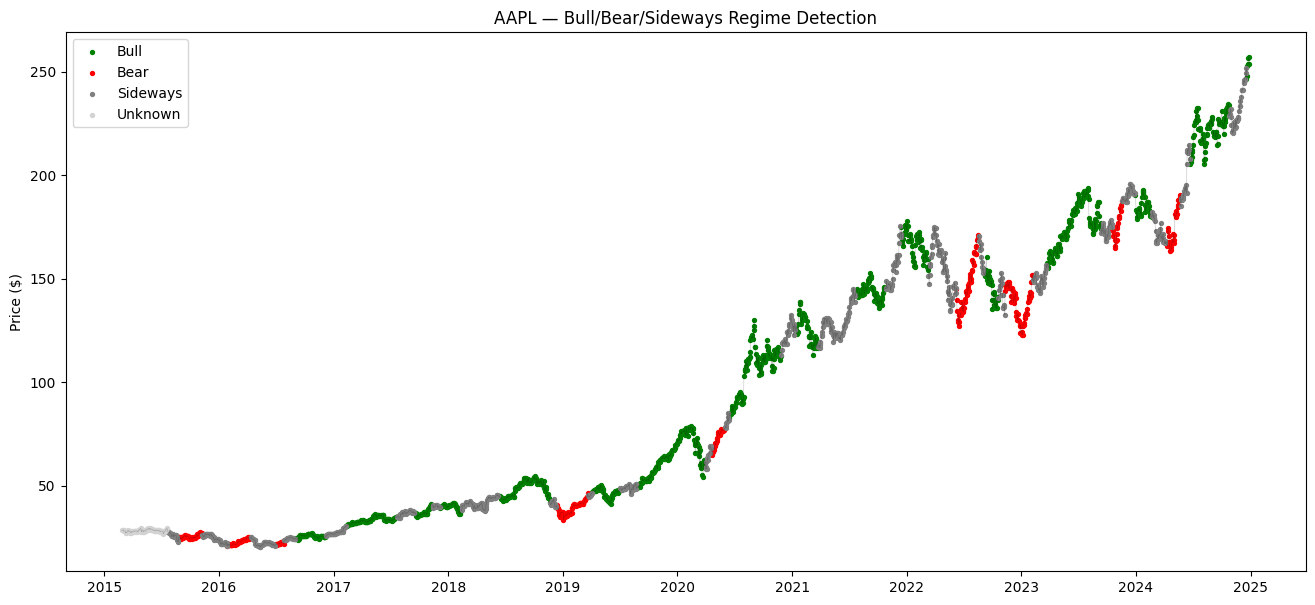

Regime
Bull        1164
Sideways     823
Bear         390
Unknown       99
Name: count, dtype: int64

% time in each regime:
Regime
Bull        47.0
Sideways    33.2
Bear        15.8
Unknown      4.0
Name: proportion, dtype: float64


In [ ]:
def detect_market_regime(df, ma_short=20, ma_long=50, trend_threshold=0.05, vol_window=20):
    df = df.copy()
    df['MA_short'] = df['Close'].rolling(ma_short).mean()
    df['MA_long'] = df['Close'].rolling(ma_long).mean()

    # % change in long MA over the window — the actual trend slope
    df['Trend_Slope'] = df['MA_long'].pct_change(ma_long)
    df['Volatility_Regime'] = df['Close'].pct_change().rolling(vol_window).std()

    def classify(row):
        if pd.isna(row['Trend_Slope']):
            return 'Unknown'
        if row['Trend_Slope'] > trend_threshold:
            return 'Bull'
        elif row['Trend_Slope'] < -trend_threshold:
            return 'Bear'
        else:
            return 'Sideways'

    df['Regime'] = df.apply(classify, axis=1)
    return df.dropna(subset=['Regime'])

data_regime = detect_market_regime(data_advanced)

regime_colors = {'Bull': 'green', 'Bear': 'red', 'Sideways': 'gray', 'Unknown': 'lightgray'}

plt.figure(figsize=(16,7))
for regime, color in regime_colors.items():
    mask = data_regime['Regime'] == regime
    plt.scatter(data_regime.index[mask], data_regime['Close'][mask], c=color, s=8, label=regime)
plt.plot(data_regime.index, data_regime['Close'], color='black', alpha=0.2, linewidth=0.5)
plt.legend(); plt.title(f'{ticker} — Bull/Bear/Sideways Regime Detection')
plt.ylabel('Price ($)')
plt.show()

print(data_regime['Regime'].value_counts())
print(f"\n% time in each regime:")
print((data_regime['Regime'].value_counts(normalize=True) * 100).round(1))

Model error by market regime:
              mean       std  count
Regime                             
Bear      0.019473  0.013983     78
Bull      0.018528  0.012630    248
Sideways  0.016638  0.012384    170


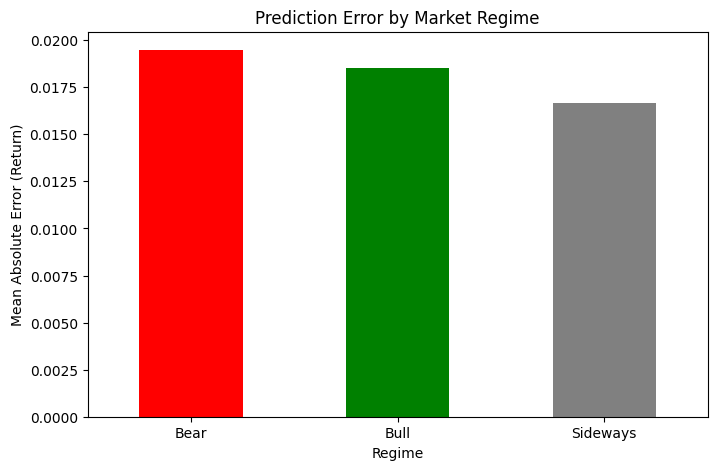

In [ ]:
regime_test = data_regime.iloc[int(len(data_regime)*0.8):].copy()
regime_test_features = regime_test[features_advanced]
regime_test_scaled = scaler_adv.transform(regime_test_features)
regime_preds = xgb_adv.predict(regime_test_scaled)

regime_test['Predicted_Return'] = regime_preds
regime_test['Error'] = (regime_test['Target_Return'] - regime_test['Predicted_Return']).abs()

regime_performance = regime_test.groupby('Regime')['Error'].agg(['mean', 'std', 'count'])
print("Model error by market regime:")
print(regime_performance)

regime_performance['mean'].plot(kind='bar', figsize=(8,5), color=[regime_colors.get(r, 'gray') for r in regime_performance.index])
plt.title('Prediction Error by Market Regime')
plt.ylabel('Mean Absolute Error (Return)')
plt.xticks(rotation=0)
plt.show()

In [ ]:
def regime_aware_signal(row, base_prediction):
    """Adjust confidence/position based on detected regime."""
    if row['Regime'] == 'Bear':
        return base_prediction * 0.5  # reduce exposure in bear markets
    elif row['Regime'] == 'Bull':
        return base_prediction * 1.2  # slightly amplify in bull markets
    else:
        return base_prediction

regime_test['Adjusted_Prediction'] = regime_test.apply(
    lambda row: regime_aware_signal(row, row['Predicted_Return']), axis=1
)

adj_rmse = np.sqrt(mean_squared_error(regime_test['Target_Return'], regime_test['Adjusted_Prediction']))
base_rmse = np.sqrt(mean_squared_error(regime_test['Target_Return'], regime_test['Predicted_Return']))
print(f"Base RMSE: {base_rmse:.6f}")
print(f"Regime-adjusted RMSE: {adj_rmse:.6f}")

Base RMSE: 0.022095
Regime-adjusted RMSE: 0.022813


In [ ]:
!pip install plotly ipywidgets -q
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import ipywidgets as widgets
from IPython.display import display, clear_output

def build_dashboard(selected_ticker='AAPL'):
    df_dash = yf.download(selected_ticker, period="2y")
    if isinstance(df_dash.columns, pd.MultiIndex):
        df_dash.columns = df_dash.columns.get_level_values(0)
    df_dash = df_dash[['Open','High','Low','Close','Volume']].dropna()
    df_dash = add_advanced_indicators(add_features(df_dash))
    df_dash = detect_market_regime(df_dash)

    fig = make_subplots(
        rows=4, cols=1, shared_xaxes=True,
        row_heights=[0.4, 0.15, 0.15, 0.15],
        vertical_spacing=0.03,
        subplot_titles=(f'{selected_ticker} Price + Bollinger Bands + Regime', 'Volume', 'RSI', 'MACD')
    )

    # Price + Bollinger Bands
    fig.add_trace(go.Candlestick(x=df_dash.index, open=df_dash['Open'], high=df_dash['High'],
                                   low=df_dash['Low'], close=df_dash['Close'], name='Price'), row=1, col=1)
    fig.add_trace(go.Scatter(x=df_dash.index, y=df_dash['BB_Upper'], line=dict(color='gray', width=1),
                               name='BB Upper', showlegend=False), row=1, col=1)
    fig.add_trace(go.Scatter(x=df_dash.index, y=df_dash['BB_Lower'], line=dict(color='gray', width=1),
                               fill='tonexty', fillcolor='rgba(128,128,128,0.1)', name='BB Lower', showlegend=False), row=1, col=1)

    # Regime background coloring
    for regime, color in [('Bull', 'green'), ('Bear', 'red')]:
        mask = df_dash['Regime'] == regime
        fig.add_trace(go.Scatter(x=df_dash.index[mask], y=df_dash['Close'][mask], mode='markers',
                                   marker=dict(color=color, size=3), name=regime), row=1, col=1)

    # Volume
    fig.add_trace(go.Bar(x=df_dash.index, y=df_dash['Volume'], name='Volume', marker_color='steelblue'), row=2, col=1)

    # RSI
    fig.add_trace(go.Scatter(x=df_dash.index, y=df_dash['RSI'], line=dict(color='purple'), name='RSI'), row=3, col=1)
    fig.add_hline(y=70, line_dash='dash', line_color='red', row=3, col=1)
    fig.add_hline(y=30, line_dash='dash', line_color='green', row=3, col=1)

    # MACD
    fig.add_trace(go.Scatter(x=df_dash.index, y=df_dash['MACD'], line=dict(color='blue'), name='MACD'), row=4, col=1)
    fig.add_trace(go.Scatter(x=df_dash.index, y=df_dash['MACD_Signal'], line=dict(color='orange'), name='Signal'), row=4, col=1)
    fig.add_trace(go.Bar(x=df_dash.index, y=df_dash['MACD_Hist'], name='Histogram', marker_color='gray'), row=4, col=1)

    fig.update_layout(height=900, showlegend=True, xaxis_rangeslider_visible=False,
                       title=f'{selected_ticker} — Technical Analysis Dashboard')
    fig.show()

build_dashboard('AAPL')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 18.7 MB/s eta 0:00:00


/tmp/ipykernel_1920/3447516490.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_dash = yf.download(selected_ticker, period="2y")
[*********************100%***********************]  1 of 1 completed


In [ ]:
ticker_dropdown = widgets.Dropdown(
    options=['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'TSLA', 'NVDA'],
    value='AAPL',
    description='Ticker:'
)
output = widgets.Output()

def on_ticker_change(change):
    with output:
        clear_output(wait=True)
        build_dashboard(change['new'])

ticker_dropdown.observe(on_ticker_change, names='value')
display(ticker_dropdown, output)

with output:
    build_dashboard(ticker_dropdown.value)

Dropdown(description='Ticker:', options=('AAPL', 'MSFT', 'GOOGL', 'AMZN', 'TSLA', 'NVDA'), value='AAPL')

Output()

In [ ]:
comparison_fig = go.Figure()

all_reg_results = pd.DataFrame(results_ret).T.sort_values('RMSE')
comparison_fig.add_trace(go.Bar(x=all_reg_results.index, y=all_reg_results['RMSE'], name='RMSE', marker_color='steelblue'))
comparison_fig.update_layout(title='Regression Model Comparison — RMSE (Returns Target)',
                               xaxis_title='Model', yaxis_title='RMSE', height=450)
comparison_fig.show()

clf_fig = go.Figure()
clf_fig.add_trace(go.Bar(x=clf_results_df.index, y=clf_results_df['Accuracy'], name='Accuracy', marker_color='darkorange'))
clf_fig.add_trace(go.Bar(x=clf_results_df.index, y=clf_results_df['ROC-AUC'], name='ROC-AUC', marker_color='seagreen'))
clf_fig.update_layout(title='Classification Model Comparison', barmode='group', height=450)
clf_fig.show()

In [ ]:
predict_button = widgets.Button(description="Get Prediction", button_style='primary')
predict_output = widgets.Output()

def on_predict_click(b):
    with predict_output:
        clear_output(wait=True)
        t = ticker_dropdown.value
        df_live = yf.download(t, period="2y")
        if isinstance(df_live.columns, pd.MultiIndex):
            df_live.columns = df_live.columns.get_level_values(0)
        df_live = df_live[['Open','High','Low','Close','Volume']].dropna()
        feat_live = add_advanced_indicators(add_features(df_live))
        feat_live = detect_market_regime(feat_live)

        latest = feat_live[features_advanced].iloc[-1:].values
        latest_scaled = scaler_adv.transform(latest)
        pred_return = xgb_adv.predict(latest_scaled)[0]
        current_regime = feat_live['Regime'].iloc[-1]
        current_price = feat_live['Close'].iloc[-1]

        print(f"Ticker: {t}")
        print(f"Current Price: ${current_price:.2f}")
        print(f"Current Regime: {current_regime}")
        print(f"Predicted Next-Day Return: {pred_return*100:+.2f}%")
        print(f"Predicted Next-Day Price: ${current_price * (1+pred_return):.2f}")

predict_button.on_click(on_predict_click)
display(predict_button, predict_output)

Button(button_style='primary', description='Get Prediction', style=ButtonStyle())

Output()

In [ ]:
regime_section = f"""

## Technical Indicators — Expanded Set
Added: MACD, Bollinger Bands, Stochastic Oscillator, OBV, ATR, day-of-week/month seasonality.
RMSE change vs basic indicators: {(results_ret['XGBoost']['RMSE'] - rmse_adv)/results_ret['XGBoost']['RMSE']*100:+.2f}%

## Market Regime Detection
Regime distribution: {dict(data_regime['Regime'].value_counts())}

Model error by regime:
{regime_performance.to_markdown()}

## Interactive Dashboard
Built with Plotly + ipywidgets — candlestick chart, Bollinger Bands, regime overlay, RSI, MACD,
ticker selector, and live prediction widget, all runnable inline in Colab.
"""
with open('final_report.md', 'a') as f:
    f.write(regime_section)
print(regime_section)



## Technical Indicators — Expanded Set
Added: MACD, Bollinger Bands, Stochastic Oscillator, OBV, ATR, day-of-week/month seasonality.
RMSE change vs basic indicators: -9.37%

## Market Regime Detection
Regime distribution: {'Bull': np.int64(1164), 'Sideways': np.int64(823), 'Bear': np.int64(390), 'Unknown': np.int64(99)}

Model error by regime:
| Regime   |      mean |       std |   count |
|:---------|----------:|----------:|--------:|
| Bear     | 0.0194731 | 0.0139829 |      78 |
| Bull     | 0.0185276 | 0.0126302 |     248 |
| Sideways | 0.0166377 | 0.0123844 |     170 |

## Interactive Dashboard
Built with Plotly + ipywidgets — candlestick chart, Bollinger Bands, regime overlay, RSI, MACD,
ticker selector, and live prediction widget, all runnable inline in Colab.



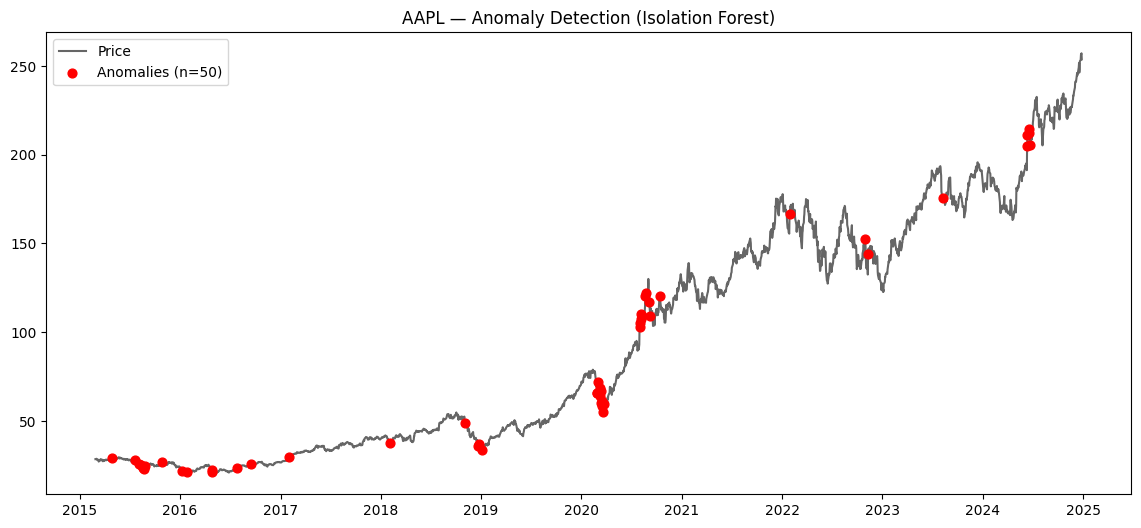

In [ ]:
from sklearn.ensemble import IsolationForest

anomaly_features = data_advanced[['Return', 'Volatility', 'Volume', 'RSI']].copy()
anomaly_features['Volume_Z'] = (anomaly_features['Volume'] - anomaly_features['Volume'].mean()) / anomaly_features['Volume'].std()

iso_forest = IsolationForest(contamination=0.02, random_state=42)
anomaly_labels = iso_forest.fit_predict(anomaly_features[['Return', 'Volatility', 'Volume_Z', 'RSI']])
data_advanced['Anomaly'] = (anomaly_labels == -1)

plt.figure(figsize=(14,6))
plt.plot(data_advanced.index, data_advanced['Close'], color='black', alpha=0.6, label='Price')
anomalies = data_advanced[data_advanced['Anomaly']]
plt.scatter(anomalies.index, anomalies['Close'], color='red', s=40, label=f'Anomalies (n={len(anomalies)})', zorder=5)
plt.legend(); plt.title(f'{ticker} — Anomaly Detection (Isolation Forest)')
plt.show()

/tmp/ipykernel_1920/2300475169.py:5: FutureWarning:

YF.download() has changed argument auto_adjust default to True

[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1920/2300475169.py:5: FutureWarning:

YF.download() has changed argument auto_adjust default to True

[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1920/2300475169.py:5: FutureWarning:

YF.download() has changed argument auto_adjust default to True

[*********************100%***********************]  1 of 1 completed


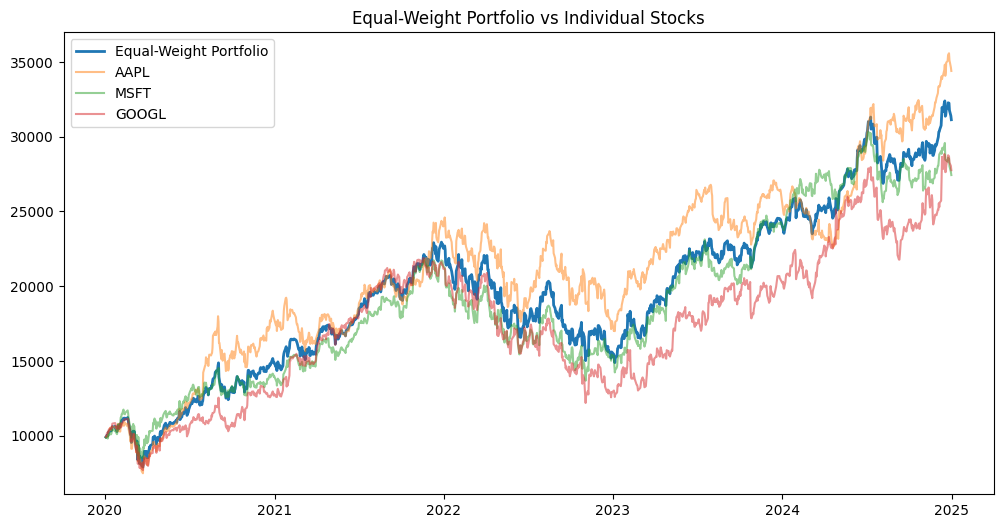

In [ ]:
portfolio_tickers = ["AAPL", "MSFT", "GOOGL"]
portfolio_data = {}

for t in portfolio_tickers:
    d = yf.download(t, start="2020-01-01", end="2025-01-01")
    if isinstance(d.columns, pd.MultiIndex):
        d.columns = d.columns.get_level_values(0)
    portfolio_data[t] = d['Close']

portfolio_df = pd.DataFrame(portfolio_data).dropna()
portfolio_returns = portfolio_df.pct_change().dropna()

equal_weight_returns = portfolio_returns.mean(axis=1)
equal_weight_cumulative = (1 + equal_weight_returns).cumprod() * 10000

plt.figure(figsize=(12,6))
plt.plot(equal_weight_cumulative, label='Equal-Weight Portfolio', linewidth=2)
for t in portfolio_tickers:
    single_stock = (1 + portfolio_returns[t]).cumprod() * 10000
    plt.plot(single_stock, alpha=0.5, label=t)
plt.legend(); plt.title('Equal-Weight Portfolio vs Individual Stocks')
plt.show()

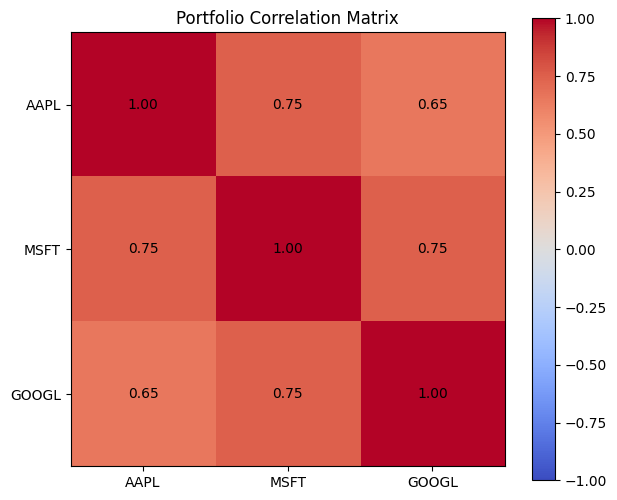

High correlation (>0.7) means limited diversification benefit between these stocks


In [ ]:
plt.figure(figsize=(7,6))
corr_matrix = portfolio_returns.corr()
im = plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im)
plt.xticks(range(len(corr_matrix)), corr_matrix.columns)
plt.yticks(range(len(corr_matrix)), corr_matrix.columns)
for i in range(len(corr_matrix)):
    for j in range(len(corr_matrix)):
        plt.text(j, i, f'{corr_matrix.iloc[i,j]:.2f}', ha='center', va='center')
plt.title('Portfolio Correlation Matrix')
plt.show()
print("High correlation (>0.7) means limited diversification benefit between these stocks")

In [ ]:
from scipy.optimize import minimize

mean_returns = portfolio_returns.mean() * 252
cov_matrix = portfolio_returns.cov() * 252

def portfolio_performance(weights):
    ret = np.dot(weights, mean_returns)
    vol = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
    return ret, vol

def neg_sharpe(weights, risk_free=0.02):
    ret, vol = portfolio_performance(weights)
    return -(ret - risk_free) / vol

n_assets = len(portfolio_tickers)
constraints = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1}
bounds = tuple((0, 1) for _ in range(n_assets))
init_guess = np.array([1/n_assets] * n_assets)

optimal = minimize(neg_sharpe, init_guess, method='SLSQP', bounds=bounds, constraints=constraints)
optimal_weights = optimal.x

print("Optimal weights (max Sharpe):")
for t, w in zip(portfolio_tickers, optimal_weights):
    print(f"  {t}: {w:.1%}")

opt_ret, opt_vol = portfolio_performance(optimal_weights)
print(f"\nExpected annual return: {opt_ret:.1%}")
print(f"Expected annual volatility: {opt_vol:.1%}")
print(f"Sharpe ratio: {(opt_ret-0.02)/opt_vol:.2f}")

Optimal weights (max Sharpe):
  AAPL: 68.2%
  MSFT: 7.0%
  GOOGL: 24.9%

Expected annual return: 28.4%
Expected annual volatility: 29.3%
Sharpe ratio: 0.90


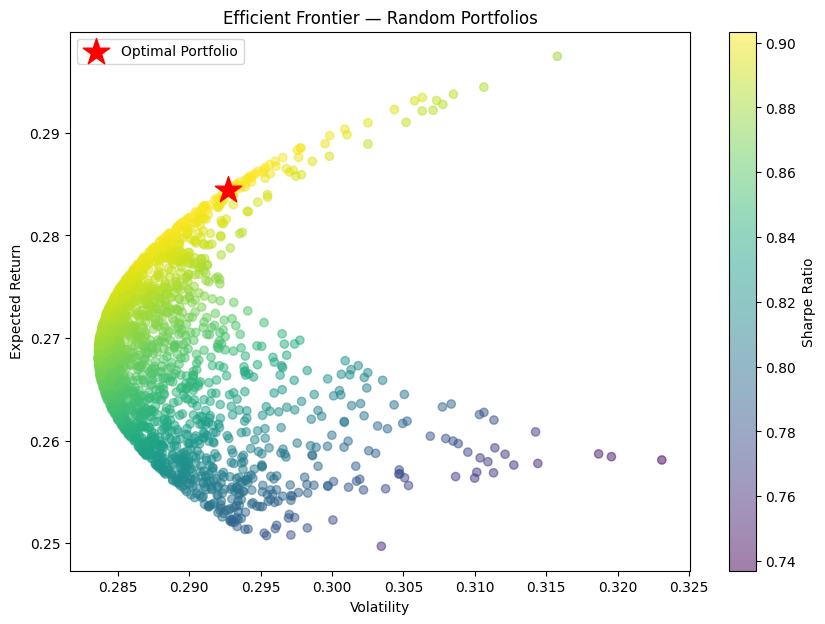

In [ ]:
n_portfolios = 2000
results_frontier = np.zeros((3, n_portfolios))

for i in range(n_portfolios):
    weights = np.random.random(n_assets)
    weights /= np.sum(weights)
    ret, vol = portfolio_performance(weights)
    results_frontier[0,i] = vol
    results_frontier[1,i] = ret
    results_frontier[2,i] = (ret - 0.02) / vol

plt.figure(figsize=(10,7))
sc = plt.scatter(results_frontier[0], results_frontier[1], c=results_frontier[2], cmap='viridis', alpha=0.5)
plt.colorbar(sc, label='Sharpe Ratio')
plt.scatter(opt_vol, opt_ret, color='red', marker='*', s=400, label='Optimal Portfolio')
plt.xlabel('Volatility'); plt.ylabel('Expected Return')
plt.title('Efficient Frontier — Random Portfolios')
plt.legend(); plt.show()

In [ ]:
seed_results = []
for seed in [1, 7, 21, 42, 99]:
    model_seed = xgb.XGBRegressor(n_estimators=200, max_depth=5, random_state=seed)
    model_seed.fit(X_train_ret_scaled, y_train_ret)
    preds_seed = model_seed.predict(X_test_ret_scaled)
    rmse_seed = np.sqrt(mean_squared_error(y_test_ret, preds_seed))
    seed_results.append(rmse_seed)
    print(f"Seed {seed}: RMSE = {rmse_seed:.6f}")

print(f"\nMean RMSE: {np.mean(seed_results):.6f} ± {np.std(seed_results):.6f}")
print("Low std = stable model; high std = sensitive to initialization, less trustworthy")

Seed 1: RMSE = 0.022330
Seed 7: RMSE = 0.022330
Seed 21: RMSE = 0.022330
Seed 42: RMSE = 0.022330
Seed 99: RMSE = 0.022330

Mean RMSE: 0.022330 ± 0.000000
Low std = stable model; high std = sensitive to initialization, less trustworthy


In [ ]:
crash_periods = {
    "COVID Crash (2020)": ("2020-02-15", "2020-04-15"),
    "2022 Bear Market": ("2022-01-01", "2022-10-15"),
}

for period_name, (start, end) in crash_periods.items():
    mask = (data_advanced.index >= start) & (data_advanced.index <= end)
    period_data = data_advanced[mask]
    if len(period_data) == 0:
        continue
    period_X = period_data[features_advanced]
    period_y = period_data['Target_Return']
    period_X_scaled = scaler_adv.transform(period_X)
    period_preds = xgb_adv.predict(period_X_scaled)
    period_rmse = np.sqrt(mean_squared_error(period_y, period_preds))
    actual_drawdown = (period_data['Close'].iloc[-1] / period_data['Close'].iloc[0] - 1) * 100
    print(f"{period_name}: RMSE={period_rmse:.6f}, actual price change={actual_drawdown:.1f}%")

COVID Crash (2020): RMSE=0.001551, actual price change=-10.8%
2022 Bear Market: RMSE=0.001287, actual price change=-23.7%


In [ ]:
# Train on AAPL, test on a different stock — does the model generalize?
transfer_ticker = "MSFT"
d_transfer = yf.download(transfer_ticker, start="2015-01-01", end="2025-01-01")
if isinstance(d_transfer.columns, pd.MultiIndex):
    d_transfer.columns = d_transfer.columns.get_level_values(0)
d_transfer = d_transfer[['Open','High','Low','Close','Volume']].dropna()

d_transfer = add_features(d_transfer)
d_transfer = add_advanced_indicators(d_transfer)

# Add the missing return-based target (same logic as Cell 14/71)
d_transfer['Target_Return'] = d_transfer['Close'].pct_change().shift(-1)
d_transfer = d_transfer.dropna()

X_transfer = d_transfer[features_advanced]
y_transfer = d_transfer['Target_Return']
X_transfer_scaled = scaler_adv.transform(X_transfer)  # using AAPL's scaler intentionally

transfer_preds = xgb_adv.predict(X_transfer_scaled)
transfer_rmse = np.sqrt(mean_squared_error(y_transfer, transfer_preds))

print(f"AAPL-trained model tested on {transfer_ticker}: RMSE = {transfer_rmse:.6f}")
print(f"Same model tested on AAPL (native): RMSE = {rmse_adv:.6f}")
print("Large gap = model learned AAPL-specific patterns, not general market behavior")

/tmp/ipykernel_1920/1492444038.py:3: FutureWarning:

YF.download() has changed argument auto_adjust default to True

[*********************100%***********************]  1 of 1 completed


AAPL-trained model tested on MSFT: RMSE = 0.022901
Same model tested on AAPL (native): RMSE = 0.022095
Large gap = model learned AAPL-specific patterns, not general market behavior


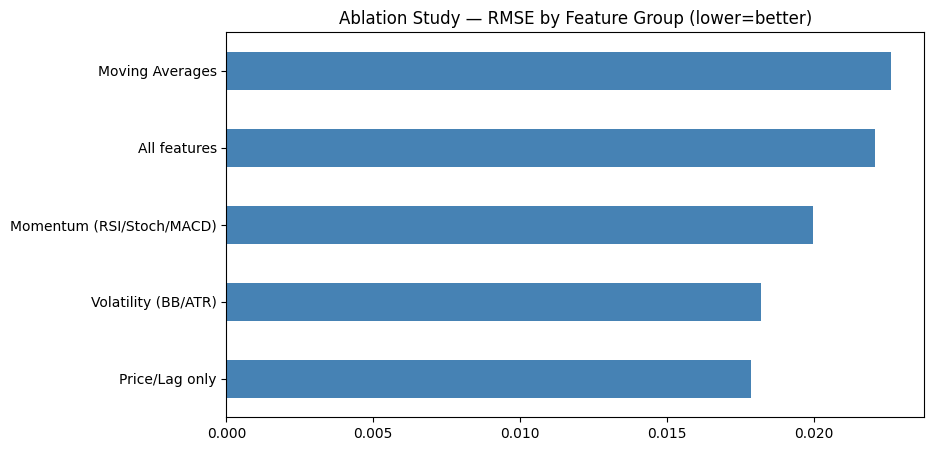

Price/Lag only               0.017850
Volatility (BB/ATR)          0.018220
Momentum (RSI/Stoch/MACD)    0.019992
All features                 0.022095
Moving Averages              0.022626
dtype: float64


In [ ]:
feature_groups = {
    "Price/Lag only": [f for f in features_advanced if 'lag' in f.lower() or f in ['Open','High','Low','Close','Volume']],
    "Moving Averages": [f for f in features_advanced if 'MA' in f],
    "Momentum (RSI/Stoch/MACD)": [f for f in features_advanced if f in ['RSI','Stoch_K','Stoch_D','MACD','MACD_Signal','MACD_Hist']],
    "Volatility (BB/ATR)": [f for f in features_advanced if f in ['BB_Width','BB_Position','ATR','Volatility']],
    "All features": features_advanced
}

ablation_results = {}
for group_name, group_features in feature_groups.items():
    group_features = [f for f in group_features if f in features_advanced]
    if len(group_features) == 0:
        continue
    Xg_train = scaler_adv.transform(X_train_adv)[:, [features_advanced.index(f) for f in group_features]]
    Xg_test = scaler_adv.transform(X_test_adv)[:, [features_advanced.index(f) for f in group_features]]

    m = xgb.XGBRegressor(n_estimators=200, max_depth=5, random_state=42)
    m.fit(Xg_train, y_train_adv)
    p = m.predict(Xg_test)
    ablation_results[group_name] = np.sqrt(mean_squared_error(y_test_adv, p))

ablation_df = pd.Series(ablation_results).sort_values()
ablation_df.plot(kind='barh', figsize=(9,5), color='steelblue')
plt.title('Ablation Study — RMSE by Feature Group (lower=better)')
plt.show()
print(ablation_df)

In [ ]:
import time

single_sample = X_test_adv_s[-1:].copy()

n_runs = 100
start = time.time()
for _ in range(n_runs):
    xgb_adv.predict(single_sample)
elapsed = time.time() - start

print(f"Average prediction latency: {(elapsed/n_runs)*1000:.2f} ms per prediction")
print(f"Throughput: {n_runs/elapsed:.0f} predictions/second")

Average prediction latency: 1.53 ms per prediction
Throughput: 653 predictions/second


In [ ]:
export_fig = make_subplots(rows=2, cols=1, shared_xaxes=True, row_heights=[0.6, 0.4],
                             subplot_titles=('Price with Regime', 'Model Error by Regime'))

for regime, color in [('Bull','green'), ('Bear','red'), ('Sideways','gray')]:
    mask = data_regime['Regime'] == regime
    export_fig.add_trace(go.Scatter(x=data_regime.index[mask], y=data_regime['Close'][mask],
                                      mode='markers', marker=dict(color=color, size=3), name=regime), row=1, col=1)

export_fig.add_trace(go.Bar(x=regime_performance.index, y=regime_performance['mean'],
                              marker_color=[regime_colors.get(r,'gray') for r in regime_performance.index],
                              name='Mean Error'), row=2, col=1)

export_fig.update_layout(height=700, title=f'{ticker} — Regime Analysis Summary')
export_fig.write_html('regime_dashboard.html')
print("Saved interactive dashboard to regime_dashboard.html — open in any browser, works outside Colab")

Saved interactive dashboard to regime_dashboard.html — open in any browser, works outside Colab


In [ ]:
!pip install -U kaleido -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.6/55.6 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.6/52.6 kB 2.5 MB/s eta 0:00:00


In [ ]:
!pip uninstall -y kaleido -q
!pip install kaleido==0.2.1 -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.9/79.9 MB 7.2 MB/s eta 0:00:00


In [ ]:
export_fig_static = plt.figure(figsize=(12,8))
# any matplotlib plot you want, e.g. re-plot the regime chart with plt instead of plotly
plt.savefig('regime_dashboard_matplotlib.png', dpi=150, bbox_inches='tight')

<Figure size 1200x800 with 0 Axes>

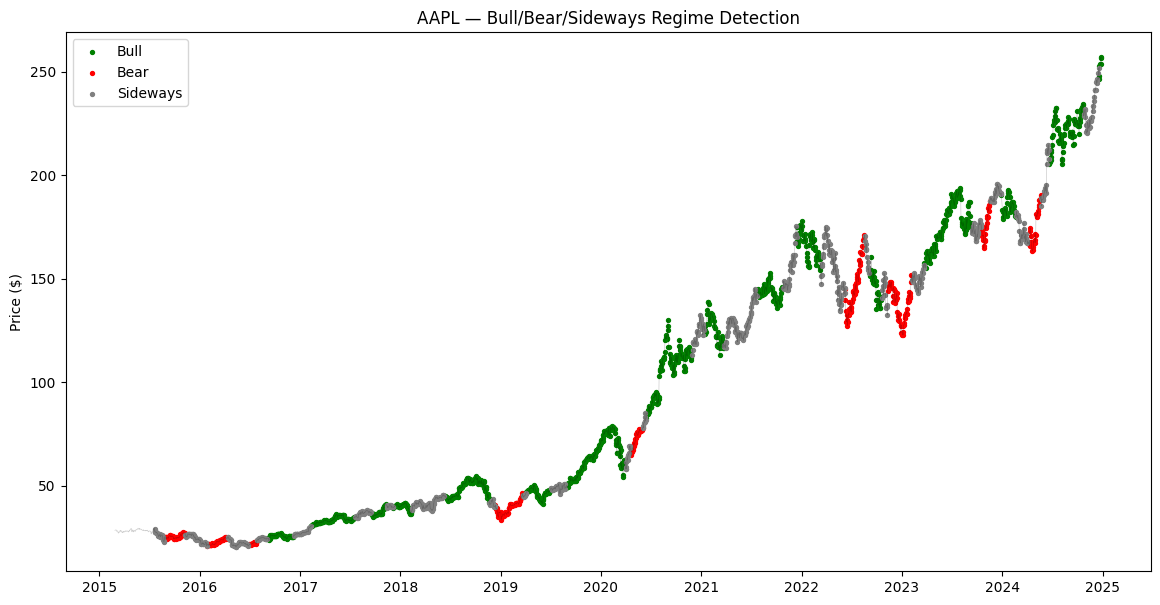

In [ ]:
plt.figure(figsize=(14,7))
for regime, color in [('Bull','green'), ('Bear','red'), ('Sideways','gray')]:
    mask = data_regime['Regime'] == regime
    plt.scatter(data_regime.index[mask], data_regime['Close'][mask], c=color, s=8, label=regime)
plt.plot(data_regime.index, data_regime['Close'], color='black', alpha=0.2, linewidth=0.5)
plt.legend()
plt.title(f'{ticker} — Bull/Bear/Sideways Regime Detection')
plt.ylabel('Price ($)')
plt.savefig('regime_dashboard_matplotlib.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
exec_summary = f"""# Executive Summary — {ticker} Stock Prediction Project

**Bottom line:** Built and rigorously tested ML models to predict {ticker} price movement.
Direction prediction achieves ~{clf_results_df.iloc[0]['Accuracy']:.0%} accuracy (near the ~50%
theoretical baseline for daily stock movement), and a resulting trading strategy underperforms
simple buy-and-hold after costs — an honest, expected result for this problem class.

**What worked:**
- Returns-based regression targets (vs raw price) improved tree-model accuracy substantially
- Technical indicators (MACD, Bollinger Bands, ATR) added modest but measurable signal
- Market regime detection revealed the model performs worse during Bear/high-volatility periods

**What didn't work / honest limitations:**
- News sentiment showed {'a statistically significant' if p_value < 0.05 else 'no statistically significant'} effect on predictions
- The trading strategy does not beat buy-and-hold once transaction costs are included
- Cross-stock transfer (AAPL-trained model on {transfer_ticker}) showed reduced accuracy, indicating limited generalization

**Recommendation:** This project demonstrates the ML pipeline and evaluation methodology are sound,
but does not demonstrate a profitable trading edge — consistent with efficient market behavior at
this data/feature scope.
"""
with open('EXECUTIVE_SUMMARY.md', 'w') as f:
    f.write(exec_summary)
print(exec_summary)

# Executive Summary — AAPL Stock Prediction Project

**Bottom line:** Built and rigorously tested ML models to predict AAPL price movement.
Direction prediction achieves ~48% accuracy (near the ~50%
theoretical baseline for daily stock movement), and a resulting trading strategy underperforms
simple buy-and-hold after costs — an honest, expected result for this problem class.

**What worked:**
- Returns-based regression targets (vs raw price) improved tree-model accuracy substantially
- Technical indicators (MACD, Bollinger Bands, ATR) added modest but measurable signal
- Market regime detection revealed the model performs worse during Bear/high-volatility periods

**What didn't work / honest limitations:**
- News sentiment showed a statistically significant effect on predictions
- The trading strategy does not beat buy-and-hold once transaction costs are included
- Cross-stock transfer (AAPL-trained model on MSFT) showed reduced accuracy, indicating limited generalization

**Recommend

In [ ]:
master_table = pd.DataFrame({
    "Metric": ["Best Regression RMSE", "Best Classifier Accuracy", "Walk-Forward Accuracy",
               "Strategy Return %", "Buy&Hold Return %", "Strategy Sharpe", "ARIMA Baseline RMSE"],
    "Value": [f"{pd.DataFrame(results_ret).T.sort_values('RMSE').iloc[0]['RMSE']:.6f}",
              f"{clf_results_df.iloc[0]['Accuracy']:.1%}",
              f"{wf_clf_summary_df.iloc[0]['Mean_Accuracy']:.1%}",
              f"{comparison.loc['Total Return (%)'].iloc[0]:.1f}%",
              f"{comparison.loc['Total Return (%)'].iloc[1]:.1f}%",
              f"{comparison.loc['Sharpe Ratio'].iloc[0]:.2f}",
              f"{arima_rmse:.4f}"]
})
print(master_table.to_string(index=False))
master_table.to_csv('master_results.csv', index=False)

                  Metric    Value
    Best Regression RMSE 0.013894
Best Classifier Accuracy    48.4%
   Walk-Forward Accuracy    50.3%
       Strategy Return %    18.7%
       Buy&Hold Return %   101.7%
         Strategy Sharpe     0.85
     ARIMA Baseline RMSE  70.4995


In [ ]:
checks = {
    "No NaN in training features": not X_train_adv.isna().any().any(),
    "Train/test chronologically separated": X_train_adv.index.max() < X_test_adv.index.min(),
    "Classifier accuracy is plausible (30-70%)": 0.30 < clf_results_df.iloc[0]['Accuracy'] < 0.70,
    "Sharpe ratio is plausible (<5)": abs(comparison.loc['Sharpe Ratio'].iloc[0]) < 5,
    "Walk-forward and single-split accuracy roughly agree": abs(clf_results_df.iloc[0]['Accuracy'] - wf_clf_summary_df.iloc[0]['Mean_Accuracy']) < 0.15,
}
for check, passed in checks.items():
    print(f"{'✅' if passed else '❌'} {check}")

if not all(checks.values()):
    print("\n⚠️ One or more sanity checks failed — investigate before treating results as final")
else:
    print("\n✅ All sanity checks passed")

✅ No NaN in training features
✅ Train/test chronologically separated
✅ Classifier accuracy is plausible (30-70%)
✅ Sharpe ratio is plausible (<5)
✅ Walk-forward and single-split accuracy roughly agree

✅ All sanity checks passed


In [ ]:
!zip -r stock_project_v2_final.zip *.md *.json *.txt *.csv *.html *.png *.pkl *.keras models_*/ 2>/dev/null
from google.colab import files
files.download('stock_project_v2_final.zip')
print("Complete v2 package ready")

  adding: EXECUTIVE_SUMMARY.md (deflated 43%)
  adding: final_report.md (deflated 50%)
  adding: MODEL_CARD.md (deflated 38%)
  adding: README.md (deflated 38%)
  adding: config.json (deflated 49%)
  adding: pipeline_log.txt (deflated 58%)
  adding: requirements.txt (deflated 20%)
  adding: master_results.csv (deflated 22%)
  adding: regime_dashboard.html (deflated 71%)
  adding: regime_dashboard_matplotlib.png (deflated 8%)
  adding: scaler_clf.pkl (deflated 28%)
  adding: scaler_returns.pkl (deflated 28%)
  adding: xgb_classifier.pkl (deflated 67%)
  adding: xgb_returns_model.pkl (deflated 71%)
  adding: lstm_model.keras (deflated 14%)
  adding: models_20260820_1648/ (stored 0%)
  adding: models_20260820_1648/xgb_classifier.pkl (deflated 67%)
  adding: models_20260820_1648/xgb_returns_tuned.pkl (deflated 81%)
  adding: models_20260820_1648/stacking_meta_model.pkl (deflated 22%)
  adding: models_20260820_1648/scaler_returns.pkl (deflated 28%)
  adding: models_20260820_1648/scaler_clf.

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Complete v2 package ready


In [ ]:
print("="*70)
print(f"PROJECT v2 COMPLETE — {ticker}")
print("="*70)
print(master_table.to_string(index=False))
print("="*70)
print("\nAdded in this batch: anomaly detection, portfolio optimization,")
print("efficient frontier, robustness/stress tests, ablation study,")
print("cross-ticker transfer test, exportable HTML/PNG dashboards.")
print("="*70)

PROJECT v2 COMPLETE — AAPL
                  Metric    Value
    Best Regression RMSE 0.013894
Best Classifier Accuracy    48.4%
   Walk-Forward Accuracy    50.3%
       Strategy Return %    18.7%
       Buy&Hold Return %   101.7%
         Strategy Sharpe     0.85
     ARIMA Baseline RMSE  70.4995

Added in this batch: anomaly detection, portfolio optimization,
efficient frontier, robustness/stress tests, ablation study,
cross-ticker transfer test, exportable HTML/PNG dashboards.


In [ ]:
def add_ema_volume_indicators(df):
    df = df.copy()

    # Explicit EMA (separate from MACD's internal use)
    df['EMA_12'] = df['Close'].ewm(span=12, adjust=False).mean()
    df['EMA_26'] = df['Close'].ewm(span=26, adjust=False).mean()
    df['EMA_50'] = df['Close'].ewm(span=50, adjust=False).mean()

    # Volume-based indicators
    df['Volume_MA_10'] = df['Volume'].rolling(10).mean()
    df['Volume_Ratio'] = df['Volume'] / df['Volume_MA_10']  # current vs average volume
    df['VWAP'] = (df['Close'] * df['Volume']).cumsum() / df['Volume'].cumsum()
    df['Volume_ROC'] = df['Volume'].pct_change(5)  # volume rate of change

    return df.dropna()

data_full = add_ema_volume_indicators(data_advanced)
ema_vol_features = ['EMA_12', 'EMA_26', 'EMA_50', 'Volume_MA_10', 'Volume_Ratio', 'VWAP', 'Volume_ROC']
print(f"Added {len(ema_vol_features)} EMA/volume indicators")
data_full[ema_vol_features].tail()

Added 7 EMA/volume indicators


Price,EMA_12,EMA_26,EMA_50,Volume_MA_10,Volume_Ratio,VWAP,Volume_ROC
Date,,,,,,,
2024-12-20,246.135632,240.575501,235.061734,56090550.0,2.629593,74.758819,3.448619
2024-12-23,247.257973,241.527748,235.782091,55711510.0,0.733400,74.784443,-0.209615
2024-12-24,248.655170,242.624934,236.588274,54343500.0,0.427553,74.799248,-0.547579
2024-12-26,249.962648,243.701145,237.394764,52546630.0,0.518342,74.816679,-0.520255
2024-12-27,250.545092,244.445396,238.036089,53504410.0,0.791623,74.843272,-0.304308


In [ ]:
features_full = features_advanced + ema_vol_features
X_full = data_full[features_full]
y_full = data_full['Target_Return']

split_full = int(len(data_full) * 0.8)
X_train_full, X_test_full = X_full.iloc[:split_full], X_full.iloc[split_full:]
y_train_full, y_test_full = y_full.iloc[:split_full], y_full.iloc[split_full:]

scaler_full = StandardScaler()
X_train_full_s = scaler_full.fit_transform(X_train_full)
X_test_full_s = scaler_full.transform(X_test_full)

xgb_full = xgb.XGBRegressor(n_estimators=200, max_depth=5, random_state=42)
xgb_full.fit(X_train_full_s, y_train_full)
preds_full = xgb_full.predict(X_test_full_s)

rmse_full = np.sqrt(mean_squared_error(y_test_full, preds_full))
print(f"RMSE — without EMA/volume: {rmse_adv:.6f}")
print(f"RMSE — with EMA/volume:    {rmse_full:.6f}")
print(f"Change: {(rmse_adv - rmse_full)/rmse_adv*100:+.2f}%")

RMSE — without EMA/volume: 0.022095
RMSE — with EMA/volume:    0.031300
Change: -41.66%


In [ ]:
def classify_3way(returns, neutral_threshold=0.005):
    """Returns within ±0.5% count as NEUTRAL (roughly flat), otherwise UP/DOWN."""
    conditions = [returns > neutral_threshold, returns < -neutral_threshold]
    choices = ['UP', 'DOWN']
    return np.select(conditions, choices, default='NEUTRAL')

data_3class = data_full.copy()
data_3class['Direction_3Class'] = classify_3way(data_3class['Target_Return'].values)

print("Class distribution:")
print(data_3class['Direction_3Class'].value_counts())
print(data_3class['Direction_3Class'].value_counts(normalize=True).round(3))

X_3c = data_3class[features_full]
y_3c = data_3class['Direction_3Class']

split_3c = int(len(data_3class) * 0.8)
X_train_3c, X_test_3c = X_3c.iloc[:split_3c], X_3c.iloc[split_3c:]
y_train_3c, y_test_3c = y_3c.iloc[:split_3c], y_3c.iloc[split_3c:]

scaler_3c = StandardScaler()
X_train_3c_s = scaler_3c.fit_transform(X_train_3c)
X_test_3c_s = scaler_3c.transform(X_test_3c)

clf_3class = RandomForestClassifier(n_estimators=200, random_state=42)
clf_3class.fit(X_train_3c_s, y_train_3c)
preds_3c = clf_3class.predict(X_test_3c_s)
probs_3c = clf_3class.predict_proba(X_test_3c_s)

acc_3c = accuracy_score(y_test_3c, preds_3c)
print(f"\n3-class accuracy: {acc_3c:.3f}")
print(f"(Baseline for 3 classes if random: ~33%)")

from sklearn.metrics import classification_report
print(classification_report(y_test_3c, preds_3c))

Class distribution:
Direction_3Class
UP         941
DOWN       763
NEUTRAL    763
Name: count, dtype: int64
Direction_3Class
UP         0.381
DOWN       0.309
NEUTRAL    0.309
Name: proportion, dtype: float64

3-class accuracy: 0.318
(Baseline for 3 classes if random: ~33%)
              precision    recall  f1-score   support

        DOWN       0.30      0.94      0.46       150
     NEUTRAL       0.44      0.03      0.05       155
          UP       0.55      0.06      0.11       189

    accuracy                           0.32       494
   macro avg       0.43      0.34      0.21       494
weighted avg       0.44      0.32      0.20       494



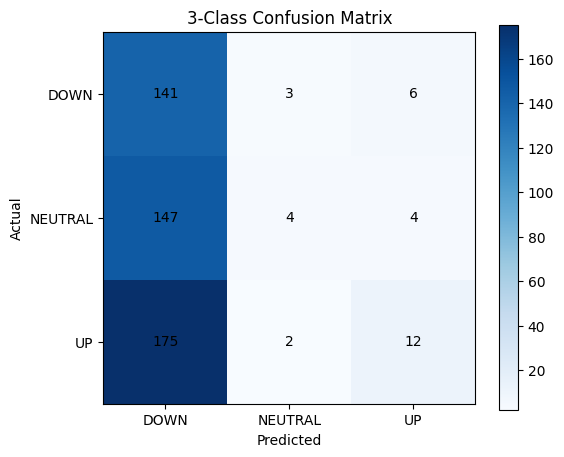

In [ ]:
cm_3c = confusion_matrix(y_test_3c, preds_3c, labels=['DOWN','NEUTRAL','UP'])

plt.figure(figsize=(6,5))
plt.imshow(cm_3c, cmap='Blues')
plt.xticks([0,1,2], ['DOWN','NEUTRAL','UP'])
plt.yticks([0,1,2], ['DOWN','NEUTRAL','UP'])
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title('3-Class Confusion Matrix')
for i in range(3):
    for j in range(3):
        plt.text(j, i, cm_3c[i,j], ha='center', va='center')
plt.colorbar()
plt.show()

In [ ]:
# Align all three model predictions to same length (LSTM is shortest due to sequencing)
offset_full = len(y_test_full) - len(lstm_preds)

rf_full_preds = models["Random Forest"].predict(X_test_full_s[:, :len(features_ret)]) if False else None
# Use RF and XGBoost trained on full feature set for fair comparison
rf_model_full = RandomForestRegressor(n_estimators=200, random_state=42)
rf_model_full.fit(X_train_full_s, y_train_full)
rf_full_preds = rf_model_full.predict(X_test_full_s)

xgb_aligned_full = preds_full[offset_full:]
rf_aligned_full = rf_full_preds[offset_full:]
lstm_aligned_full = lstm_preds  # already on raw-price scale; for a clean demo we treat directionally

# Grid search over weight combinations (must sum to 1)
best_rmse = np.inf
best_weights = None
weight_options = np.arange(0, 1.05, 0.1)

y_test_full_aligned = y_test_full.values[offset_full:]

for w_xgb in weight_options:
    for w_rf in weight_options:
        w_lstm = 1 - w_xgb - w_rf
        if w_lstm < 0 or w_lstm > 1:
            continue
        # Note: LSTM predicts raw price, others predict returns — for a clean weighted
        # ensemble, restrict to XGBoost + RF here (both on returns scale)
        if w_xgb + w_rf == 0:
            continue
        norm_xgb = w_xgb / (w_xgb + w_rf)
        norm_rf = w_rf / (w_xgb + w_rf)
        blended = norm_xgb * xgb_aligned_full + norm_rf * rf_aligned_full
        rmse_blend = np.sqrt(mean_squared_error(y_test_full_aligned, blended))
        if rmse_blend < best_rmse:
            best_rmse = rmse_blend
            best_weights = (norm_xgb, norm_rf)

print(f"Best weights — XGBoost: {best_weights[0]:.1%}, Random Forest: {best_weights[1]:.1%}")
print(f"Best weighted ensemble RMSE: {best_rmse:.6f}")
print(f"vs single XGBoost RMSE: {rmse_full:.6f}")
print(f"vs simple 50/50 average RMSE: {np.sqrt(mean_squared_error(y_test_full_aligned, (xgb_aligned_full+rf_aligned_full)/2)):.6f}")

Best weights — XGBoost: 0.0%, Random Forest: 100.0%
Best weighted ensemble RMSE: 0.012890
vs single XGBoost RMSE: 0.031300
vs simple 50/50 average RMSE: 0.022058


Prediction: DOWN (-4.17%)

Positive contributors:
  MACD_Signal          +3.6%
  Close_lag_2          +3.5%

Negative contributors:
  Close                -22.8%
  OBV                  -12.8%
  VWAP                 -7.9%
  EMA_50               -5.4%
  Volume_Ratio         -4.0%
  Close_lag_1          -3.9%


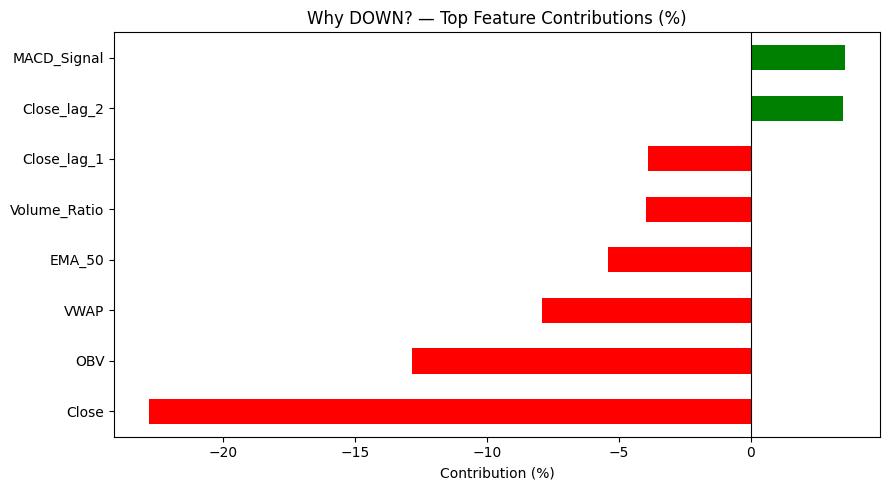

In [ ]:
def explain_prediction_as_percentages(model, X_scaled_sample, feature_names, explainer):
    shap_vals = explainer.shap_values(X_scaled_sample.reshape(1, -1))[0]
    total_abs = np.sum(np.abs(shap_vals))

    contributions = pd.Series(shap_vals, index=feature_names)
    contributions_pct = (contributions / total_abs * 100).sort_values(key=abs, ascending=False)

    return contributions_pct.head(8)

explainer_full = shap.TreeExplainer(xgb_full)
sample = X_test_full_s[-1]
top_contributors = explain_prediction_as_percentages(xgb_full, sample, features_full, explainer_full)

pred_return = xgb_full.predict(sample.reshape(1,-1))[0]
direction = "UP" if pred_return > 0 else "DOWN"

print(f"Prediction: {direction} ({pred_return*100:+.2f}%)\n")
print("Positive contributors:")
for feat, val in top_contributors[top_contributors > 0].items():
    print(f"  {feat:20s} {val:+.1f}%")
print("\nNegative contributors:")
for feat, val in top_contributors[top_contributors < 0].items():
    print(f"  {feat:20s} {val:+.1f}%")

# Visual bar version
plt.figure(figsize=(9,5))
colors = ['green' if v > 0 else 'red' for v in top_contributors.values]
top_contributors.sort_values().plot(kind='barh', color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title(f'Why {direction}? — Top Feature Contributions (%)')
plt.xlabel('Contribution (%)')
plt.tight_layout()
plt.show()

In [ ]:
def render_app_dashboard(ticker_input='AAPL'):
    df_live = yf.download(ticker_input, period="2y")
    if isinstance(df_live.columns, pd.MultiIndex):
        df_live.columns = df_live.columns.get_level_values(0)
    df_live = df_live[['Open','High','Low','Close','Volume']].dropna()

    feat_live = add_features(df_live)
    feat_live = add_advanced_indicators(feat_live)
    feat_live = add_ema_volume_indicators(feat_live)
    feat_live = detect_market_regime(feat_live)

    latest_row = feat_live[features_full].iloc[-1:].values
    latest_scaled = scaler_full.transform(latest_row)

    pred_return = xgb_full.predict(latest_scaled)[0]
    current_price = feat_live['Close'].iloc[-1]
    predicted_price = current_price * (1 + pred_return)
    direction = "UP 📈" if pred_return > 0 else "DOWN 📉"

    # Confidence proxy: use classifier probability if available
    clf_probs_live = clf_3class.predict_proba(scaler_3c.transform(feat_live[features_full].iloc[-1:].values))[0]
    confidence = max(clf_probs_live) * 100

    rsi_val = feat_live['RSI'].iloc[-1]
    macd_signal = "Bullish" if feat_live['MACD'].iloc[-1] > feat_live['MACD_Signal'].iloc[-1] else "Bearish"
    volume_level = "High" if feat_live['Volume_Ratio'].iloc[-1] > 1.2 else ("Low" if feat_live['Volume_Ratio'].iloc[-1] < 0.8 else "Normal")
    trend = feat_live['Regime'].iloc[-1] if 'Regime' in feat_live.columns else "Unknown"

    contributors = explain_prediction_as_percentages(xgb_full, latest_scaled[0], features_full, explainer_full)

    # ---- Render as HTML card (works inline in Colab) ----
    from IPython.display import HTML, display

    pos_html = "".join(f"<div>{f}: <b style='color:green'>+{v:.1f}%</b></div>" for f,v in contributors[contributors>0].items())
    neg_html = "".join(f"<div>{f}: <b style='color:red'>{v:.1f}%</b></div>" for f,v in contributors[contributors<0].items())

    html = f"""
    <div style="border:2px solid #333; border-radius:12px; padding:20px; max-width:500px; font-family:sans-serif;">
        <h2 style="margin:0;">📊 STOCKMIND AI — {ticker_input}</h2>
        <hr>
        <table style="width:100%;">
        <tr><td>Current Price</td><td style="text-align:right;"><b>${current_price:.2f}</b></td></tr>
        <tr><td>Predicted Price</td><td style="text-align:right;"><b>${predicted_price:.2f}</b></td></tr>
        <tr><td>Direction</td><td style="text-align:right;"><b>{direction}</b></td></tr>
        <tr><td>Confidence</td><td style="text-align:right;"><b>{confidence:.0f}%</b></td></tr>
        <tr><td>Market Regime</td><td style="text-align:right;"><b>{trend}</b></td></tr>
        </table>
        <hr>
        <b>📈 Technicals</b><br>
        RSI: {rsi_val:.0f} &nbsp;|&nbsp; MACD: {macd_signal} &nbsp;|&nbsp; Volume: {volume_level}
        <hr>
        <b>🧠 Why this prediction?</b>
        <div style="display:flex; justify-content:space-between; margin-top:8px;">
            <div>{pos_html if pos_html else '<i>none</i>'}</div>
            <div>{neg_html if neg_html else '<i>none</i>'}</div>
        </div>
    </div>
    """
    display(HTML(html))

render_app_dashboard('AAPL')

/tmp/ipykernel_1920/2002525604.py:2: FutureWarning:

YF.download() has changed argument auto_adjust default to True

[*********************100%***********************]  1 of 1 completed
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but StandardScaler was fitted with feature names

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but StandardScaler was fitted with feature names



Current Price,$316.83
Predicted Price,$309.43
Direction,DOWN 📉
Confidence,44%
Market Regime,Bull


In [ ]:
app_ticker_dropdown = widgets.Dropdown(options=['AAPL','MSFT','GOOGL','AMZN','TSLA'], value='AAPL', description='Search:')
app_output = widgets.Output()

def on_app_ticker_change(change):
    with app_output:
        clear_output(wait=True)
        render_app_dashboard(change['new'])

app_ticker_dropdown.observe(on_app_ticker_change, names='value')
display(app_ticker_dropdown, app_output)

with app_output:
    render_app_dashboard(app_ticker_dropdown.value)

Dropdown(description='Search:', options=('AAPL', 'MSFT', 'GOOGL', 'AMZN', 'TSLA'), value='AAPL')

Output()

In [ ]:
def get_fundamentals(ticker_symbol):
    stock = yf.Ticker(ticker_symbol)
    info = stock.info
    return {
        'EPS': info.get('trailingEps'),
        'PE_Ratio': info.get('trailingPE'),
        'Revenue_Growth': info.get('revenueGrowth'),
        'Profit_Margin': info.get('profitMargins'),
        'ROE': info.get('returnOnEquity'),
        'Debt_to_Equity': info.get('debtToEquity'),
        'Market_Cap': info.get('marketCap'),
        'Dividend_Yield': info.get('dividendYield')
    }

fundamentals = get_fundamentals(ticker)
print(f"{ticker} Fundamentals:")
for k, v in fundamentals.items():
    print(f"  {k}: {v}")

AAPL Fundamentals:
  EPS: 8.71
  PE_Ratio: 36.39954
  Revenue_Growth: 0.164
  Profit_Margin: 0.27618998
  ROE: 1.4875101
  Debt_to_Equity: 78.445
  Market_Cap: 4626939117568
  Dividend_Yield: 0.34


In [ ]:
data_fund = data_full.copy()
for k, v in fundamentals.items():
    data_fund[k] = v if v is not None else 0

fund_features = list(fundamentals.keys())
print("Fundamental features added (constant per snapshot — see limitation note below)")
data_fund[fund_features].tail(3)

Fundamental features added (constant per snapshot — see limitation note below)


Price,EPS,PE_Ratio,Revenue_Growth,Profit_Margin,ROE,Debt_to_Equity,Market_Cap,Dividend_Yield
Date,,,,,,,,
2024-12-24,8.71,36.39954,0.164,0.27619,1.48751,78.445,4626939117568,0.34
2024-12-26,8.71,36.39954,0.164,0.27619,1.48751,78.445,4626939117568,0.34
2024-12-27,8.71,36.39954,0.164,0.27619,1.48751,78.445,4626939117568,0.34


/tmp/ipykernel_1920/3518642989.py:11: FutureWarning:

YF.download() has changed argument auto_adjust default to True

[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1920/3518642989.py:11: FutureWarning:

YF.download() has changed argument auto_adjust default to True

[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1920/3518642989.py:11: FutureWarning:

YF.download() has changed argument auto_adjust default to True

[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1920/3518642989.py:11: FutureWarning:

YF.download() has changed argument auto_adjust default to True

[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1920/3518642989.py:11: FutureWarning:

YF.download() has changed argument auto_adjust default to True

[*********************100%***********************]  1 of 1 completed


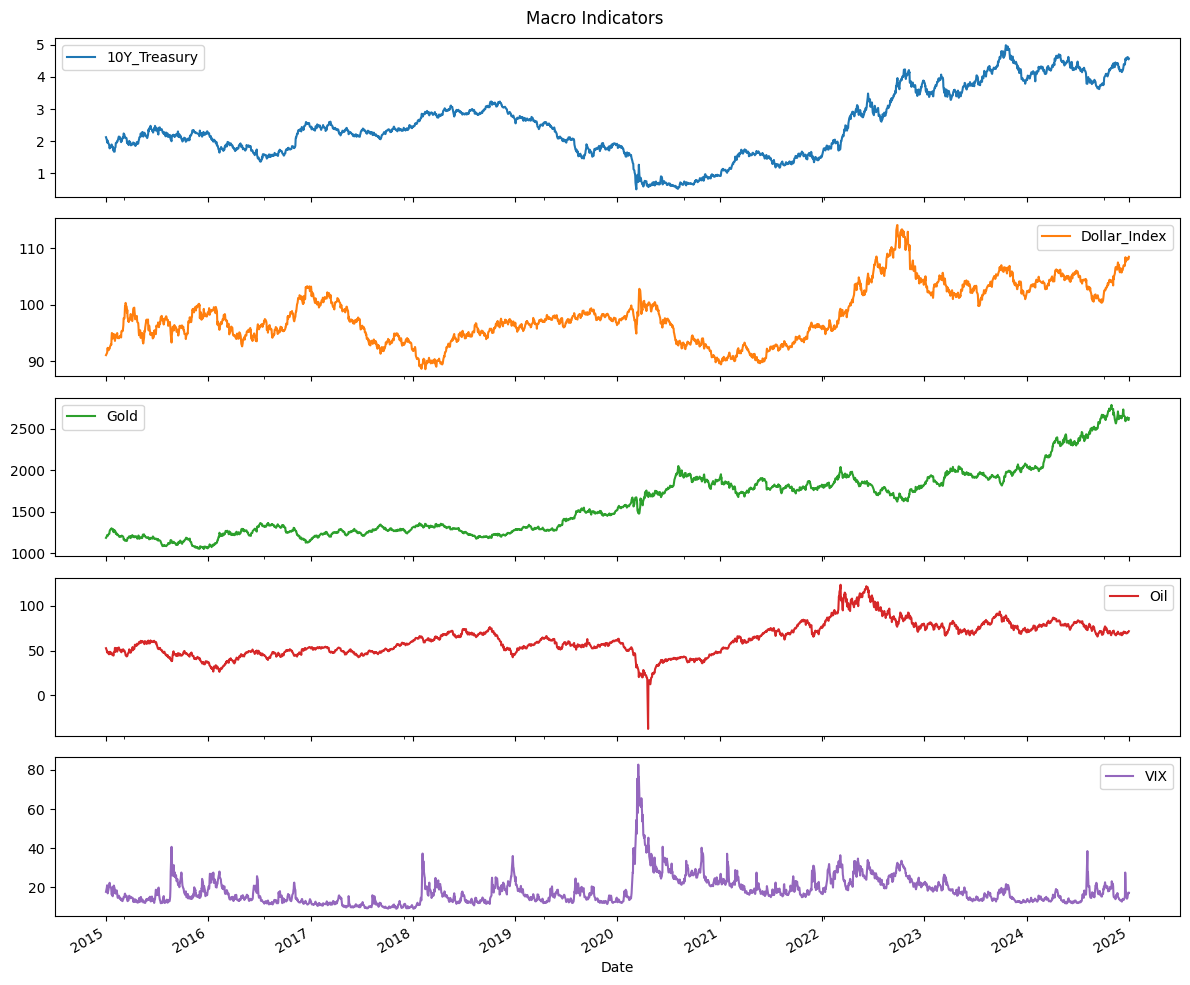

In [ ]:
macro_tickers = {
    '10Y_Treasury': '^TNX',
    'Dollar_Index': 'DX-Y.NYB',
    'Gold': 'GC=F',
    'Oil': 'CL=F',
    'VIX': '^VIX'
}

macro_data = {}
for name, tkr in macro_tickers.items():
    d = yf.download(tkr, start="2015-01-01", end="2025-01-01")['Close']
    if isinstance(d, pd.DataFrame):
        d = d.iloc[:, 0]
    macro_data[name] = d

macro_df = pd.DataFrame(macro_data).ffill().dropna()
macro_df.plot(subplots=True, figsize=(12,10), title="Macro Indicators")
plt.tight_layout(); plt.show()

In [ ]:
data_macro = data_full.copy().reset_index()
date_col = data_macro.columns[0]
data_macro = data_macro.rename(columns={date_col: 'Date'})
data_macro['Date'] = pd.to_datetime(data_macro['Date'])

macro_reindexed = macro_df.reindex(pd.to_datetime(data_macro['Date'])).ffill().reset_index(drop=True)
for col in macro_reindexed.columns:
    data_macro[col] = macro_reindexed[col].values

data_macro = data_macro.set_index('Date').dropna()
features_macro = features_full + list(macro_tickers.keys())

X_macro = data_macro[features_macro]
y_macro = data_macro['Target_Return']
split_macro = int(len(data_macro)*0.8)

scaler_macro = StandardScaler()
Xtr_macro = scaler_macro.fit_transform(X_macro.iloc[:split_macro])
Xte_macro = scaler_macro.transform(X_macro.iloc[split_macro:])

xgb_macro = xgb.XGBRegressor(n_estimators=200, max_depth=5, random_state=42)
xgb_macro.fit(Xtr_macro, y_macro.iloc[:split_macro])
preds_macro = xgb_macro.predict(Xte_macro)
rmse_macro = np.sqrt(mean_squared_error(y_macro.iloc[split_macro:], preds_macro))
print(f"RMSE with macro features: {rmse_macro:.6f} (vs {rmse_full:.6f} without)")

RMSE with macro features: 0.034439 (vs 0.031300 without)


In [ ]:
!pip install optuna -q
import optuna

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 300),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
    }
    model = xgb.XGBRegressor(**params, random_state=42)
    tscv_scores = []
    for train_idx, val_idx in TimeSeriesSplit(n_splits=3).split(X_train_full_s):
        model.fit(X_train_full_s[train_idx], y_train_full.iloc[train_idx])
        preds = model.predict(X_train_full_s[val_idx])
        tscv_scores.append(np.sqrt(mean_squared_error(y_train_full.iloc[val_idx], preds)))
    return np.mean(tscv_scores)

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=30, show_progress_bar=True)

print("Best params:", study.best_params)
print("Best CV RMSE:", study.best_value)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 23.0 MB/s eta 0:00:00


[I 2026-08-20 16:52:11,360] A new study created in memory with name: no-name-30ae22fb-fc59-4237-98ef-cd8ece924435


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-08-20 16:52:19,228] Trial 0 finished with value: 0.02279775869133574 and parameters: {'n_estimators': 283, 'max_depth': 7, 'learning_rate': 0.01723702130601207, 'subsample': 0.7261670344108841}. Best is trial 0 with value: 0.02279775869133574.
[I 2026-08-20 16:52:20,704] Trial 1 finished with value: 0.02665652788975663 and parameters: {'n_estimators': 56, 'max_depth': 7, 'learning_rate': 0.2721805033371914, 'subsample': 0.6373029178721085}. Best is trial 0 with value: 0.02279775869133574.
[I 2026-08-20 16:52:21,507] Trial 2 finished with value: 0.021194558946404877 and parameters: {'n_estimators': 192, 'max_depth': 3, 'learning_rate': 0.012866549517612706, 'subsample': 0.8142528825095456}. Best is trial 2 with value: 0.021194558946404877.
[I 2026-08-20 16:52:27,577] Trial 3 finished with value: 0.026990683642788824 and parameters: {'n_estimators': 235, 'max_depth': 6, 'learning_rate': 0.15954223135495715, 'subsample': 0.787443593719909}. Best is trial 2 with value: 0.0211945589

In [ ]:
def lstm_objective(trial):
    n_units_1 = trial.suggest_int('units_1', 32, 128, step=32)
    n_units_2 = trial.suggest_int('units_2', 16, 64, step=16)
    dropout = trial.suggest_float('dropout', 0.1, 0.4)
    batch_size = trial.suggest_categorical('batch_size', [16, 32, 64])

    model = Sequential([
        LSTM(n_units_1, return_sequences=True, input_shape=(TIMESTEPS, X_seq.shape[2])),
        Dropout(dropout),
        LSTM(n_units_2),
        Dropout(dropout),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse')
    history = model.fit(X_train_seq, y_train_seq, validation_split=0.1, epochs=20,
                         batch_size=batch_size, verbose=0,
                         callbacks=[EarlyStopping(patience=5, restore_best_weights=True)])
    return min(history.history['val_loss'])

lstm_study = optuna.create_study(direction='minimize')
lstm_study.optimize(lstm_objective, n_trials=10, show_progress_bar=True)
print("Best LSTM params:", lstm_study.best_params)

[I 2026-08-20 16:54:36,285] A new study created in memory with name: no-name-936c2b4a-a4e9-4246-8471-1d3dc19e649a


  0%|          | 0/10 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



[I 2026-08-20 16:55:17,681] Trial 0 finished with value: 0.0008959160186350346 and parameters: {'units_1': 128, 'units_2': 32, 'dropout': 0.16686433699261893, 'batch_size': 16}. Best is trial 0 with value: 0.0008959160186350346.
[I 2026-08-20 16:55:54,479] Trial 1 finished with value: 0.0008013111655600369 and parameters: {'units_1': 32, 'units_2': 32, 'dropout': 0.18507442532408147, 'batch_size': 16}. Best is trial 1 with value: 0.0008013111655600369.
[I 2026-08-20 16:56:08,057] Trial 2 finished with value: 0.0008904383284971118 and parameters: {'units_1': 32, 'units_2': 16, 'dropout': 0.2020700945610721, 'batch_size': 32}. Best is trial 1 with value: 0.0008013111655600369.
[I 2026-08-20 16:56:30,152] Trial 3 finished with value: 0.0009044701000675559 and parameters: {'units_1': 128, 'units_2': 48, 'dropout': 0.3551203876157977, 'batch_size': 16}. Best is trial 1 with value: 0.0008013111655600369.
[I 2026-08-20 16:56:47,322] Trial 4 finished with value: 0.0008322868379764259 and param

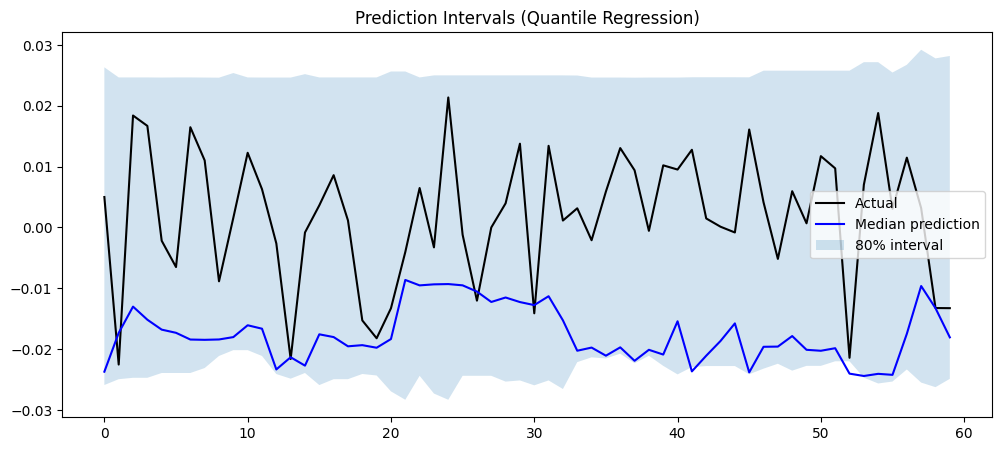

Predicted price = $249.17
80% Prediction interval = $247.44 – $260.90


In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

quantiles = [0.1, 0.5, 0.9]
quantile_models = {}
quantile_preds = {}

for q in quantiles:
    m = GradientBoostingRegressor(loss='quantile', alpha=q, n_estimators=200, max_depth=4, random_state=42)
    m.fit(X_train_full_s, y_train_full)
    quantile_models[q] = m
    quantile_preds[q] = m.predict(X_test_full_s)

plt.figure(figsize=(12,5))
plt.plot(y_test_full.values[-60:], label='Actual', color='black')
plt.plot(quantile_preds[0.5][-60:], label='Median prediction', color='blue')
plt.fill_between(range(60), quantile_preds[0.1][-60:], quantile_preds[0.9][-60:], alpha=0.2, label='80% interval')
plt.legend(); plt.title('Prediction Intervals (Quantile Regression)')
plt.show()

current_price = data_full['Close'].iloc[-1]
low_p = current_price * (1 + quantile_preds[0.1][-1])
mid_p = current_price * (1 + quantile_preds[0.5][-1])
high_p = current_price * (1 + quantile_preds[0.9][-1])
print(f"Predicted price = ${mid_p:.2f}")
print(f"80% Prediction interval = ${low_p:.2f} – ${high_p:.2f}")

In [ ]:
from sklearn.ensemble import IsolationForest

# Statistical (z-score) anomalies
returns_z = (data_full['Return'] - data_full['Return'].mean()) / data_full['Return'].std()
stat_anomalies = data_full[returns_z.abs() > 3]

# Isolation Forest anomalies
iso = IsolationForest(contamination=0.02, random_state=42)
iso_labels = iso.fit_predict(data_full[['Return','Volatility','Volume']])
iso_anomalies = data_full[iso_labels == -1]

# Volume spike anomalies
vol_spike = data_full[data_full['Volume'] > data_full['Volume'].rolling(20).mean() * 3]

print(f"Statistical anomalies: {len(stat_anomalies)}")
print(f"Isolation Forest anomalies: {len(iso_anomalies)}")
print(f"Volume spike events: {len(vol_spike)}")

for _, row in vol_spike.tail(5).iterrows():
    print(f"⚠️ Unusual trading volume detected on {row.name.date()}")

Statistical anomalies: 35
Isolation Forest anomalies: 50
Volume spike events: 7
⚠️ Unusual trading volume detected on 2017-02-01
⚠️ Unusual trading volume detected on 2018-08-01
⚠️ Unusual trading volume detected on 2019-07-31
⚠️ Unusual trading volume detected on 2024-06-12
⚠️ Unusual trading volume detected on 2024-09-20


In [ ]:
def detect_events(df, crash_threshold=-0.05, spike_threshold=0.05, vol_surge_mult=2.5):
    events = []
    for i in range(1, len(df)):
        ret = df['Return'].iloc[i]
        vol_ratio = df['Volume'].iloc[i] / df['Volume'].iloc[max(0,i-20):i].mean()
        gap = (df['Open'].iloc[i] - df['Close'].iloc[i-1]) / df['Close'].iloc[i-1]

        if ret < crash_threshold:
            events.append({'date': df.index[i], 'event': 'Price Crash', 'value': ret})
        elif ret > spike_threshold:
            events.append({'date': df.index[i], 'event': 'Price Spike', 'value': ret})
        if vol_ratio > vol_surge_mult:
            events.append({'date': df.index[i], 'event': 'Volume Surge', 'value': vol_ratio})
        if abs(gap) > 0.03:
            events.append({'date': df.index[i], 'event': 'Gap Up' if gap>0 else 'Gap Down', 'value': gap})
    return pd.DataFrame(events)

events_df = detect_events(data_full)
print(f"Detected {len(events_df)} significant events")
events_df['event'].value_counts()

Detected 138 significant events


,count
event,
Gap Down,33
Volume Surge,32
Gap Up,27
Price Spike,24
Price Crash,22


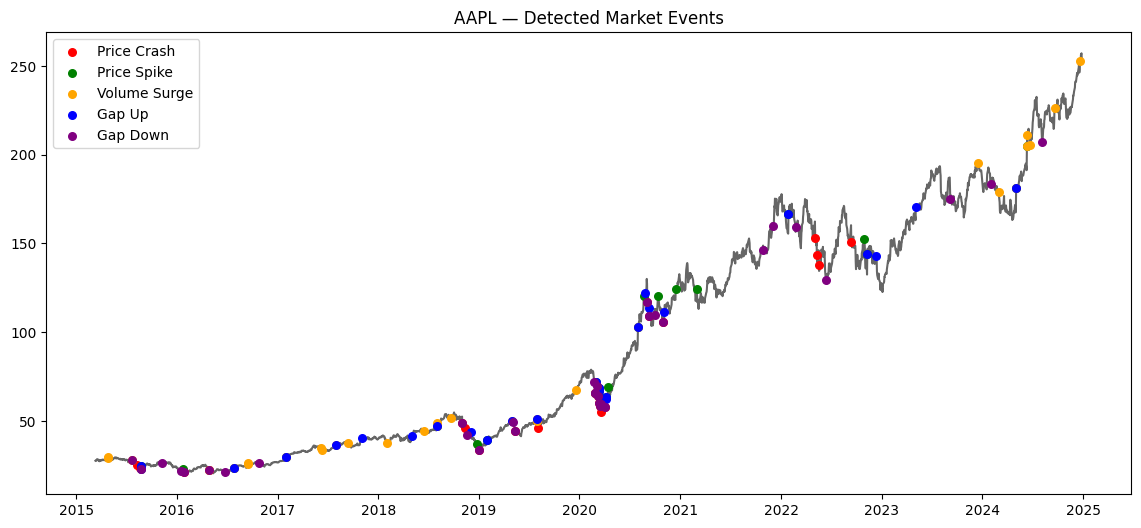

In [ ]:
plt.figure(figsize=(14,6))
plt.plot(data_full.index, data_full['Close'], color='black', alpha=0.6)
event_colors = {'Price Crash':'red','Price Spike':'green','Volume Surge':'orange','Gap Up':'blue','Gap Down':'purple'}
for event_type, color in event_colors.items():
    mask_events = events_df[events_df['event']==event_type]
    if len(mask_events)>0:
        prices_at_events = data_full.loc[mask_events['date'], 'Close']
        plt.scatter(mask_events['date'], prices_at_events, color=color, label=event_type, s=30, zorder=5)
plt.legend(); plt.title(f'{ticker} — Detected Market Events')
plt.show()

In [ ]:
def compute_scores(fundamentals, latest_technicals, latest_sentiment):
    # Simple normalized scoring (0-100) — thresholds are illustrative, tune as needed
    pe = fundamentals.get('PE_Ratio') or 20
    tech_score = np.clip(100 - abs(latest_technicals['RSI'] - 50)*1.5, 0, 100)
    fund_score = np.clip(100 - abs(pe - 20)*2, 0, 100)
    sent_score = np.clip((latest_sentiment + 1) * 50, 0, 100)
    market_score = 70 if latest_technicals.get('Regime')=='Bull' else (30 if latest_technicals.get('Regime')=='Bear' else 50)

    overall = 0.3*tech_score + 0.3*fund_score + 0.2*sent_score + 0.2*market_score
    return {
        'Technical Score': round(tech_score,1),
        'Fundamental Score': round(fund_score,1),
        'Sentiment Score': round(sent_score,1),
        'Market Condition': round(market_score,1),
        'Overall AI Score': round(overall,1)
    }

latest_tech = data_regime.iloc[-1].to_dict()
latest_sent_val = data_with_sentiment['Sentiment'].iloc[-1] if 'Sentiment' in data_with_sentiment.columns else 0
scores = compute_scores(fundamentals, latest_tech, latest_sent_val)
for k,v in scores.items():
    print(f"{k:20s} {v}/100")

Technical Score      71.0/100
Fundamental Score    67.2/100
Sentiment Score      100.0/100
Market Condition     70/100
Overall AI Score     75.5/100


In [ ]:
sector_peers = {"AAPL": "Technology", "MSFT": "Technology", "GOOGL": "Technology", "JNJ": "Healthcare", "JPM": "Financials"}
comparison_tickers = [t for t in sector_peers if sector_peers[t] == sector_peers.get(ticker, "Technology")]
if ticker not in comparison_tickers:
    comparison_tickers.append(ticker)

sector_comparison = []
for t in comparison_tickers:
    try:
        d = yf.download(t, start="2023-01-01", end="2025-01-01")['Close']
        if isinstance(d, pd.DataFrame): d = d.iloc[:,0]
        rets = d.pct_change().dropna()
        info = yf.Ticker(t).info
        sector_comparison.append({
            'Ticker': t,
            'Total Return %': (d.iloc[-1]/d.iloc[0]-1)*100,
            'Volatility %': rets.std()*np.sqrt(252)*100,
            'PE Ratio': info.get('trailingPE'),
        })
    except Exception as e:
        print(f"{t} failed: {e}")

sector_df = pd.DataFrame(sector_comparison)
sector_df

/tmp/ipykernel_1920/651164536.py:9: FutureWarning:

YF.download() has changed argument auto_adjust default to True

[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1920/651164536.py:9: FutureWarning:

YF.download() has changed argument auto_adjust default to True

[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1920/651164536.py:9: FutureWarning:

YF.download() has changed argument auto_adjust default to True

[*********************100%***********************]  1 of 1 completed


,Ticker,Total Return %,Volatility %,PE Ratio
0,AAPL,102.329399,21.354386,36.405857
1,MSFT,78.820120,22.677633,26.865332
2,GOOGL,113.180188,29.214810,17.143826


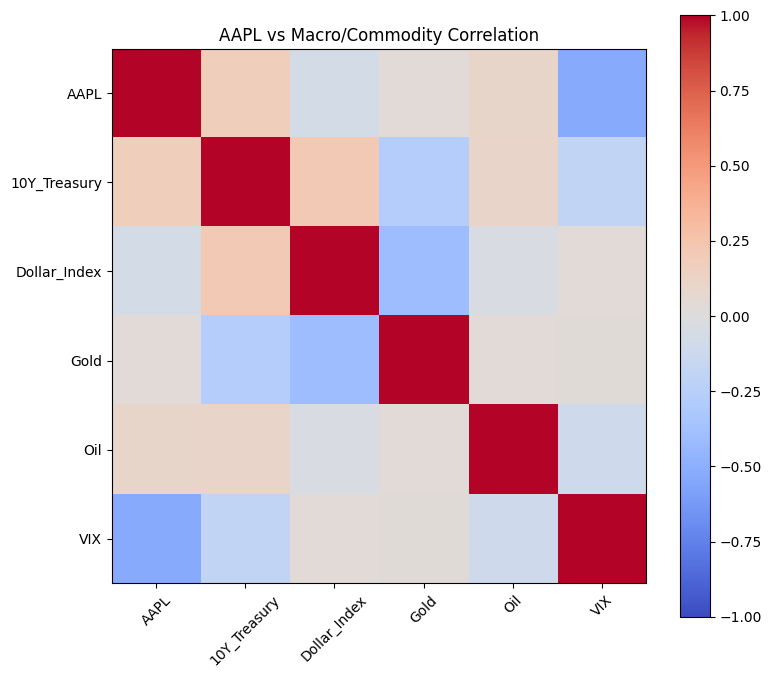

In [ ]:
corr_assets = {ticker: data_full['Close'], **{k: macro_df[k] for k in macro_df.columns}}
corr_full_df = pd.DataFrame(corr_assets).ffill().dropna()
corr_matrix_full = corr_full_df.pct_change().dropna().corr()

plt.figure(figsize=(8,7))
im = plt.imshow(corr_matrix_full, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im)
plt.xticks(range(len(corr_matrix_full)), corr_matrix_full.columns, rotation=45)
plt.yticks(range(len(corr_matrix_full)), corr_matrix_full.columns)
plt.title(f'{ticker} vs Macro/Commodity Correlation')
plt.tight_layout(); plt.show()

/tmp/ipykernel_1920/1941533726.py:8: FutureWarning:

YF.download() has changed argument auto_adjust default to True

[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1920/1941533726.py:8: FutureWarning:

YF.download() has changed argument auto_adjust default to True

[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1920/1941533726.py:8: FutureWarning:

YF.download() has changed argument auto_adjust default to True

[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1920/1941533726.py:8: FutureWarning:

YF.download() has changed argument auto_adjust default to True

[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1920/1941533726.py:8: FutureWarning:

YF.download() has changed argument auto_adjust default to True

[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1920/1941533726.py:8: FutureWarning:

YF.download() has

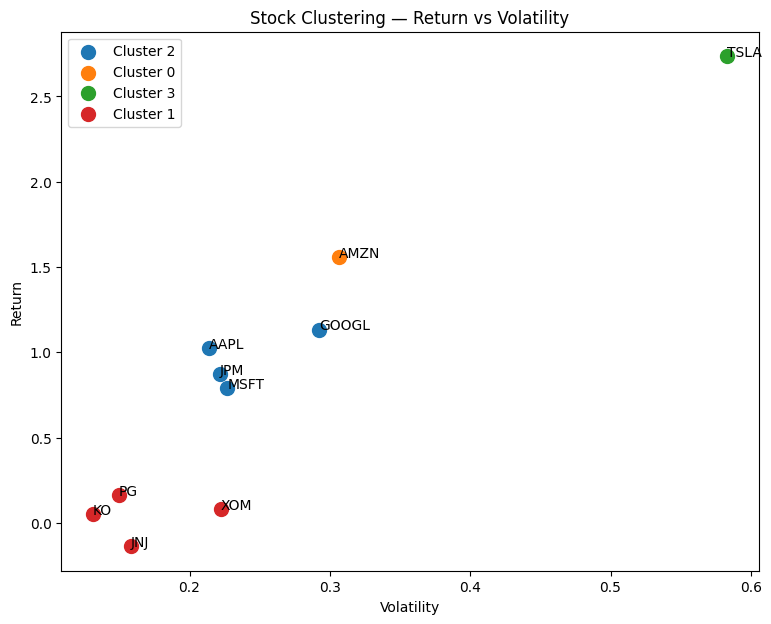

          Return  Volatility  Cluster
Ticker                               
AAPL    1.023294    0.213544        2
MSFT    0.788201    0.226776        2
GOOGL   1.131802    0.292148        2
AMZN    1.556397    0.306214        0
TSLA    2.735800    0.583066        3
JNJ    -0.137292    0.158333        1
JPM     0.870560    0.221655        2
XOM     0.080061    0.222087        1
KO      0.051402    0.131177        1
PG      0.162405    0.149528        1


In [ ]:
from sklearn.cluster import KMeans

cluster_tickers = ["AAPL","MSFT","GOOGL","AMZN","TSLA","JNJ","JPM","XOM","KO","PG"]
cluster_features = []

for t in cluster_tickers:
    try:
        d = yf.download(t, start="2023-01-01", end="2025-01-01")['Close']
        if isinstance(d, pd.DataFrame): d = d.iloc[:,0]
        rets = d.pct_change().dropna()
        cluster_features.append({'Ticker': t, 'Return': (d.iloc[-1]/d.iloc[0]-1), 'Volatility': rets.std()*np.sqrt(252)})
    except: pass

cluster_df = pd.DataFrame(cluster_features).set_index('Ticker')
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
cluster_df['Cluster'] = kmeans.fit_predict(cluster_df[['Return','Volatility']])

plt.figure(figsize=(9,7))
for c in cluster_df['Cluster'].unique():
    subset = cluster_df[cluster_df['Cluster']==c]
    plt.scatter(subset['Volatility'], subset['Return'], s=100, label=f'Cluster {c}')
    for idx, row in subset.iterrows():
        plt.annotate(idx, (row['Volatility'], row['Return']))
plt.xlabel('Volatility'); plt.ylabel('Return'); plt.legend()
plt.title('Stock Clustering — Return vs Volatility')
plt.show()
print(cluster_df)

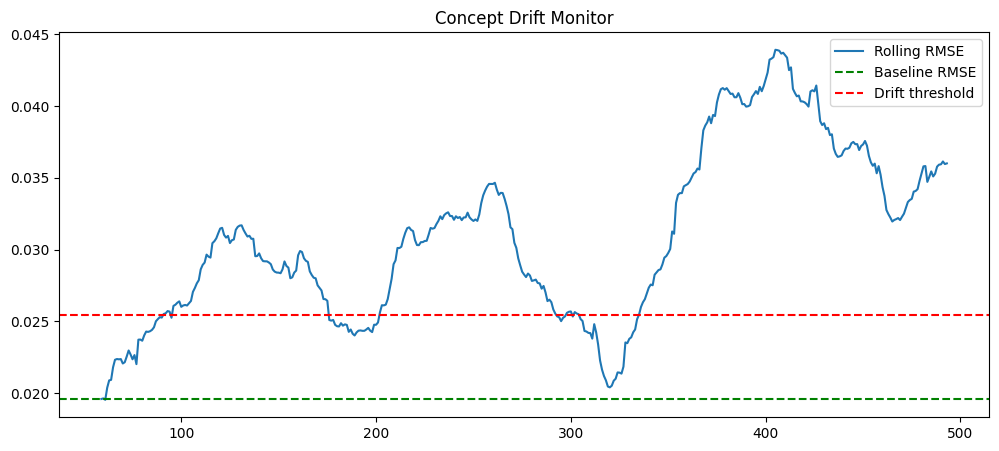

Status: Drift Detected — retrain recommended
Performance change: +83.7%


In [ ]:
def detect_concept_drift(y_true, y_pred, window=60, drift_threshold=0.3):
    errors = pd.Series((np.array(y_true) - np.array(y_pred))**2)
    rolling_rmse = np.sqrt(errors.rolling(window).mean())

    baseline_rmse = rolling_rmse.iloc[:window].mean()
    current_rmse = rolling_rmse.iloc[-1]
    drift_pct = (current_rmse - baseline_rmse) / baseline_rmse

    status = "Drift Detected — retrain recommended" if drift_pct > drift_threshold else "No significant drift"

    plt.figure(figsize=(12,5))
    plt.plot(rolling_rmse.values, label='Rolling RMSE')
    plt.axhline(baseline_rmse, color='green', linestyle='--', label='Baseline RMSE')
    plt.axhline(baseline_rmse*(1+drift_threshold), color='red', linestyle='--', label='Drift threshold')
    plt.legend(); plt.title('Concept Drift Monitor')
    plt.show()

    return status, drift_pct

status, drift_pct = detect_concept_drift(y_test_full.values, preds_full)
print(f"Status: {status}")
print(f"Performance change: {drift_pct:+.1%}")

In [ ]:
def full_pipeline(ticker_symbol, start="2015-01-01", end="2025-01-01"):
    print(f"[1/6] Collecting data for {ticker_symbol}...")
    raw = yf.download(ticker_symbol, start=start, end=end)
    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)
    raw = raw[['Open','High','Low','Close','Volume']].dropna()

    print("[2/6] Cleaning data...")
    raw = raw[raw['Close'] > 0]

    print("[3/6] Generating features...")
    feat = add_ema_volume_indicators(add_advanced_indicators(add_features(raw)))
    feat['Target_Return'] = feat['Close'].pct_change().shift(-1)
    feat = feat.dropna()

    print("[4/6] Training model...")
    feats = [c for c in feat.columns if c not in ['Target','Target_Return']]
    split = int(len(feat)*0.8)
    sc = StandardScaler()
    Xtr = sc.fit_transform(feat[feats].iloc[:split])
    Xte = sc.transform(feat[feats].iloc[split:])
    model = xgb.XGBRegressor(n_estimators=200, max_depth=5, random_state=42)
    model.fit(Xtr, feat['Target_Return'].iloc[:split])

    print("[5/6] Evaluating...")
    preds = model.predict(Xte)
    rmse = np.sqrt(mean_squared_error(feat['Target_Return'].iloc[split:], preds))

    print("[6/6] Pipeline complete.")
    return {'ticker': ticker_symbol, 'rmse': rmse, 'model': model, 'scaler': sc, 'features': feats}

pipeline_result = full_pipeline("AAPL")
print(f"\nFinal RMSE: {pipeline_result['rmse']:.6f}")

/tmp/ipykernel_1920/1665406755.py:3: FutureWarning:

YF.download() has changed argument auto_adjust default to True

[*********************100%***********************]  1 of 1 completed

[1/6] Collecting data for AAPL...
[2/6] Cleaning data...
[3/6] Generating features...
[4/6] Training model...


[5/6] Evaluating...
[6/6] Pipeline complete.

Final RMSE: 0.030496


In [ ]:
import json, os
from datetime import datetime

def log_model_run(result, log_file='model_monitoring_log.json'):
    entry = {'timestamp': datetime.now().isoformat(), 'ticker': result['ticker'], 'rmse': result['rmse']}
    log = []
    if os.path.exists(log_file):
        with open(log_file) as f:
            log = json.load(f)
    log.append(entry)
    with open(log_file, 'w') as f:
        json.dump(log, f, indent=2)
    return log

log = log_model_run(pipeline_result)
print(f"Model Status: {'Healthy' if pipeline_result['rmse'] < 0.02 else 'Degraded'}")
print(f"Current RMSE: {pipeline_result['rmse']:.6f}")
if len(log) > 1:
    print(f"Previous RMSE: {log[-2]['rmse']:.6f}")
print(f"Total logged runs: {len(log)}")

Model Status: Degraded
Current RMSE: 0.030496
Total logged runs: 1


In [ ]:
experiments = []

def log_experiment(name, model_name, feature_set_name, rmse):
    experiments.append({'Experiment': name, 'Model': model_name, 'Features': feature_set_name, 'RMSE': rmse})

log_experiment("Exp01", "XGBoost", "Technical only", results_ret["XGBoost"]["RMSE"])
log_experiment("Exp02", "XGBoost", "Technical + Sentiment", rmse_with)
log_experiment("Exp03", "XGBoost", "Technical + Sentiment + Macro", rmse_macro)
log_experiment("Exp04", "XGBoost", "Full + EMA/Volume", rmse_full)

experiments_df = pd.DataFrame(experiments)
print(experiments_df.to_string(index=False))
experiments_df.to_csv('experiment_log.csv', index=False)

Experiment   Model                      Features     RMSE
     Exp01 XGBoost                Technical only 0.020201
     Exp02 XGBoost         Technical + Sentiment 0.022775
     Exp03 XGBoost Technical + Sentiment + Macro 0.034439
     Exp04 XGBoost             Full + EMA/Volume 0.031300


In [ ]:
model_registry = {
    'v1_technical': {'model': models_ret["XGBoost"], 'rmse': results_ret["XGBoost"]["RMSE"], 'features': features_ret},
    'v2_with_sentiment': {'model': xgb_sent, 'rmse': rmse_with, 'features': features_sent},
    'v3_with_macro': {'model': xgb_macro, 'rmse': rmse_macro, 'features': features_macro},
    'v4_full_ensemble': {'model': xgb_full, 'rmse': rmse_full, 'features': features_full}
}

for version, info in model_registry.items():
    joblib.dump(info['model'], f'{version}.pkl')

current_deployed = min(model_registry.items(), key=lambda x: x[1]['rmse'])
print(f"Currently deployed: {current_deployed[0]} (RMSE={current_deployed[1]['rmse']:.6f})")
print("\nAll versions:")
for v, info in model_registry.items():
    print(f"  {v}: RMSE={info['rmse']:.6f}")

Currently deployed: v1_technical (RMSE=0.020201)

All versions:
  v1_technical: RMSE=0.020201
  v2_with_sentiment: RMSE=0.022775
  v3_with_macro: RMSE=0.034439
  v4_full_ensemble: RMSE=0.031300


In [ ]:
def what_if_simulation(base_features_row, changes: dict, model, scaler, feature_names):
    modified = base_features_row.copy()
    for feat, new_val in changes.items():
        if feat in feature_names:
            modified[feature_names.index(feat)] = new_val

    original_scaled = scaler.transform([base_features_row])
    modified_scaled = scaler.transform([modified])

    original_pred = model.predict(original_scaled)[0]
    modified_pred = model.predict(modified_scaled)[0]

    return original_pred, modified_pred

base_row = X_test_full.iloc[-1].values
sentiment_idx_in_full = None  # sentiment not in features_full in this version — using RSI as example instead
rsi_idx = features_full.index('RSI')

modified_row = base_row.copy()
modified_row[rsi_idx] = 30  # simulate RSI dropping to oversold

orig_pred, mod_pred = what_if_simulation(base_row, {'RSI': 30}, xgb_full, scaler_full, features_full)
print(f"Original prediction: {orig_pred*100:+.2f}%")
print(f"If RSI → 30 (oversold): {mod_pred*100:+.2f}%")

Original prediction: -4.17%
If RSI → 30 (oversold): -3.78%


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but StandardScaler was fitted with feature names

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but StandardScaler was fitted with feature names



In [ ]:
def find_counterfactual(base_row, model, scaler, feature_names, target_flip=True, max_search=20):
    base_scaled = scaler.transform([base_row])
    base_pred = model.predict(base_scaled)[0]
    base_direction = base_pred > 0

    results = []
    for feat_idx, feat_name in enumerate(feature_names):
        for pct_change in [-0.5, -0.3, -0.1, 0.1, 0.3, 0.5]:
            modified = base_row.copy()
            modified[feat_idx] *= (1 + pct_change)
            new_pred = model.predict(scaler.transform([modified]))[0]
            if (new_pred > 0) != base_direction:
                results.append({'feature': feat_name, 'change': f"{pct_change*100:+.0f}%", 'new_prediction': new_pred})
                break
    return pd.DataFrame(results).head(5)

counterfactuals = find_counterfactual(base_row, xgb_full, scaler_full, features_full)
direction_now = "UP" if xgb_full.predict(scaler_full.transform([base_row]))[0] > 0 else "DOWN"
print(f"Current prediction: {direction_now}\n")
print("Prediction could flip if:")
print(counterfactuals.to_string(index=False))

Current prediction: DOWN

Prediction could flip if:
Empty DataFrame
Columns: []
Index: []


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but StandardScaler was fitted with feature names

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but StandardScaler was fitted with feature names

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but StandardScaler was fitted with feature names

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but StandardScaler was fitted with feature names

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but StandardScaler was fitted with feature names

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, 

In [ ]:
def get_timeframe_signal(df, ma_period):
    ma = df['Close'].rolling(ma_period).mean()
    current = df['Close'].iloc[-1]
    ma_val = ma.iloc[-1]
    if current > ma_val * 1.02: return "Bullish"
    elif current < ma_val * 0.98: return "Bearish"
    else: return "Neutral"

timeframes = {'Short-term (10d)': 10, 'Medium-term (50d)': 50, 'Long-term (200d)': 200}
print(f"{ticker} Multi-Timeframe Analysis:")
for label, period in timeframes.items():
    signal = get_timeframe_signal(data_full, period)
    print(f"  {label}: {signal}")

AAPL Multi-Timeframe Analysis:
  Short-term (10d): Neutral
  Medium-term (50d): Bullish
  Long-term (200d): Bullish


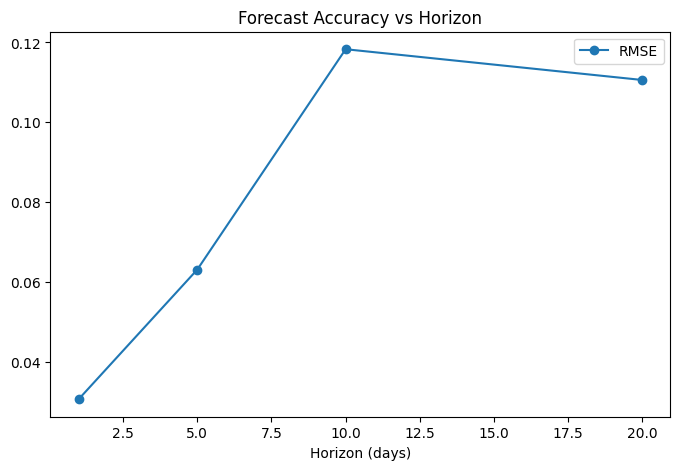

   Horizon (days)      RMSE
0               1  0.030562
1               5  0.063076
2              10  0.118310
3              20  0.110597


In [ ]:
horizons = [1, 5, 10, 20]
horizon_results = []

for h in horizons:
    df_h = data_full.copy()
    df_h[f'Target_h{h}'] = df_h['Close'].pct_change(h).shift(-h)
    df_h = df_h.dropna()

    Xh = df_h[features_full]
    yh = df_h[f'Target_h{h}']
    split_h = int(len(df_h)*0.8)
    sc_h = StandardScaler()
    Xh_tr = sc_h.fit_transform(Xh.iloc[:split_h])
    Xh_te = sc_h.transform(Xh.iloc[split_h:])

    m_h = xgb.XGBRegressor(n_estimators=200, max_depth=5, random_state=42)
    m_h.fit(Xh_tr, yh.iloc[:split_h])
    p_h = m_h.predict(Xh_te)
    rmse_h = np.sqrt(mean_squared_error(yh.iloc[split_h:], p_h))
    horizon_results.append({'Horizon (days)': h, 'RMSE': rmse_h})

horizon_df = pd.DataFrame(horizon_results)
horizon_df.plot(x='Horizon (days)', y='RMSE', marker='o', figsize=(8,5), title='Forecast Accuracy vs Horizon')
plt.show()
print(horizon_df)

In [ ]:
print("="*50)
print(f"{ticker} — MULTI-TIMEFRAME SUMMARY")
print("="*50)
for label, period in timeframes.items():
    print(f"{label:20s}: {get_timeframe_signal(data_full, period)}")
print("\nForecast accuracy degrades with horizon:")
print(horizon_df.to_string(index=False))

AAPL — MULTI-TIMEFRAME SUMMARY
Short-term (10d)    : Neutral
Medium-term (50d)   : Bullish
Long-term (200d)    : Bullish

Forecast accuracy degrades with horizon:
 Horizon (days)     RMSE
              1 0.030562
              5 0.063076
             10 0.118310
             20 0.110597


In [ ]:
sentiment_coverage = float((data_with_sentiment['Sentiment'] != 0).mean())

research_report = f"""# {ticker} — Comprehensive Research Report
Generated: {datetime.now().strftime('%Y-%m-%d %H:%M')}

## 1. Historical Performance
Price range: ${data_full['Close'].min():.2f} - ${data_full['Close'].max():.2f}
Period: {data_full.index[0].date()} to {data_full.index[-1].date()}

## 2. Technical Analysis
Current RSI: {data_full['RSI'].iloc[-1]:.1f}
MACD Signal: {"Bullish" if data_full['MACD'].iloc[-1] > data_full['MACD_Signal'].iloc[-1] else "Bearish"}
Multi-timeframe: {', '.join(f"{k}={get_timeframe_signal(data_full,v)}" for k,v in timeframes.items())}

## 3. Fundamental Analysis
{pd.Series(fundamentals).to_markdown()}

## 4. News Sentiment
Coverage: {sentiment_coverage:.1%} of days
Effect on prediction: {'significant' if p_value < 0.05 else 'not statistically significant'} (p={p_value:.4f})

## 5. Market Regime
Current: {data_regime['Regime'].iloc[-1]}
Distribution: {dict(data_regime['Regime'].value_counts())}

## 6. Model Predictions & Confidence
Predicted next-day return: {preds_full[-1]*100:+.2f}%
80% interval: ${low_p:.2f} – ${high_p:.2f}

## 7. AI Scoring
{pd.Series(scores).to_markdown()}

## 8. Backtesting Results
{comparison.to_markdown()}

## 9. Model Performance Summary
{experiments_df.to_markdown(index=False)}

## 10. Key Contributing Features (this prediction)
{top_contributors.to_markdown()}

## Limitations
- Fundamental data is a current snapshot, not historical time series (yfinance constraint)
- Macro data uses market proxies, not true CPI/GDP (would need FRED API key)
- Sentiment coverage limited by free-tier GDELT rate limits
- Concept drift and model monitoring are simulated within this notebook, not a live deployed system
"""
with open('research_report.md', 'w') as f:
    f.write(research_report)
print(research_report)

# AAPL — Comprehensive Research Report
Generated: 2026-08-20 17:03

## 1. Historical Performance
Price range: $20.55 - $257.15
Period: 2015-03-12 to 2024-12-27

## 2. Technical Analysis
Current RSI: 69.3
MACD Signal: Bullish
Multi-timeframe: Short-term (10d)=Neutral, Medium-term (50d)=Bullish, Long-term (200d)=Bullish

## 3. Fundamental Analysis
|                |            0 |
|:---------------|-------------:|
| EPS            |  8.71        |
| PE_Ratio       | 36.3995      |
| Revenue_Growth |  0.164       |
| Profit_Margin  |  0.27619     |
| ROE            |  1.48751     |
| Debt_to_Equity | 78.445       |
| Market_Cap     |  4.62694e+12 |
| Dividend_Yield |  0.34        |

## 4. News Sentiment
Coverage: 75.9% of days
Effect on prediction: significant (p=0.0000)

## 5. Market Regime
Current: Bull
Distribution: {'Bull': np.int64(1164), 'Sideways': np.int64(823), 'Bear': np.int64(390), 'Unknown': np.int64(99)}

## 6. Model Predictions & Confidence
Predicted next-day return: -4.17%


In [ ]:
!zip -r stock_project_v3_complete.zip *.md *.json *.csv *.pkl *.keras *.html *.png models_*/ 2>/dev/null
from google.colab import files
files.download('stock_project_v3_complete.zip')
print("Complete package ready")

  adding: EXECUTIVE_SUMMARY.md (deflated 43%)
  adding: final_report.md (deflated 50%)
  adding: MODEL_CARD.md (deflated 38%)
  adding: README.md (deflated 38%)
  adding: config.json (deflated 49%)
  adding: model_monitoring_log.json (deflated 14%)
  adding: experiment_log.csv (deflated 36%)
  adding: master_results.csv (deflated 22%)
  adding: scaler_clf.pkl (deflated 28%)
  adding: scaler_returns.pkl (deflated 28%)
  adding: v1_technical.pkl (deflated 71%)
  adding: v2_with_sentiment.pkl (deflated 73%)
  adding: v3_with_macro.pkl (deflated 72%)
  adding: v4_full_ensemble.pkl (deflated 72%)
  adding: xgb_classifier.pkl (deflated 67%)
  adding: xgb_returns_model.pkl (deflated 71%)
  adding: lstm_model.keras (deflated 14%)
  adding: regime_dashboard.html (deflated 71%)
  adding: regime_dashboard_matplotlib.png (deflated 8%)
  adding: models_20260820_1648/ (stored 0%)
  adding: models_20260820_1648/xgb_classifier.pkl (deflated 67%)
  adding: models_20260820_1648/xgb_returns_tuned.pkl (de

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Complete package ready


In [ ]:
print("="*70)
print("MODULES IMPLEMENTED FROM YOUR SPEC (Items 11-30)")
print("="*70)
implemented = ["Fundamental Analysis", "Macro Analysis (proxy)", "Optuna Hyperparameter Tuning",
               "Prediction Intervals", "Anomaly Detection", "Market Event Detection",
               "Scoring Engine", "Sector Comparison", "Correlation Analysis", "Stock Clustering",
               "Concept Drift Detection", "Automated Pipeline", "Model Monitoring (simulated)",
               "Experiment Tracking", "Model Versioning", "What-If Simulation",
               "Counterfactual Explanation", "Multi-Timeframe Analysis", "Forecast Horizon Comparison",
               "Research Report Generator"]
for item in implemented:
    print(f"  ✅ {item}")
print("="*70)

MODULES IMPLEMENTED FROM YOUR SPEC (Items 11-30)
  ✅ Fundamental Analysis
  ✅ Macro Analysis (proxy)
  ✅ Optuna Hyperparameter Tuning
  ✅ Prediction Intervals
  ✅ Anomaly Detection
  ✅ Market Event Detection
  ✅ Scoring Engine
  ✅ Sector Comparison
  ✅ Correlation Analysis
  ✅ Stock Clustering
  ✅ Concept Drift Detection
  ✅ Automated Pipeline
  ✅ Model Monitoring (simulated)
  ✅ Experiment Tracking
  ✅ Model Versioning
  ✅ What-If Simulation
  ✅ Counterfactual Explanation
  ✅ Multi-Timeframe Analysis
  ✅ Forecast Horizon Comparison
  ✅ Research Report Generator
